In [50]:
library(Seurat)
library(Signac)
library(scCustomize)
library(dplyr)
library(GenomicRanges)
library(ggplot2)
library(patchwork)
library(tidyverse)
library(Matrix)
library(harmony)
library(data.table)
library(future)
library(GenomeInfoDb)
library(BSgenome.Mmusculus.UCSC.mm10)
library(EnsDb.Mmusculus.v79)
library(DoubletFinder)
setwd('/data/bio_data/')
set.seed(1234)

In [3]:
Process_RNA <- function(proj=proj, nfeatures=2000, pc.nums=50, dims=1:50, pca.name = 'pca', umap.name= 'umap.rna', res = 0.8){
  DefaultAssay(proj) <- "RNA"
  #
  proj <- NormalizeData(proj)
  proj <- FindVariableFeatures(proj, nfeatures = nfeatures)
  VariableFeatures(proj) <- VariableFeatures(proj)[!VariableFeatures(proj) %in% blacklist.genes]
  proj <- ScaleData(proj)
  proj <- RunPCA(proj, npcs = pc.nums, reduction.name = pca.name)
  #
  return(proj)
}
runDoubletFinder <- function(obj, dims, estDubRate=0.075, ncores=1){
  # Run DoubletFinder on a provided (preprocessed) Seurat object
  # Return the seurat object with the selected pANN parameter and the 
  # DoubletFinder doublet classifications
  
  ### pK Identification (parameter-sweep) ###
  # "pK ~ This defines the PC neighborhood size used to compute pANN (proportion of artificial nearest neighbors), 
  # expressed as a proportion of the merged real-artificial data. 
  # No default is set, as pK should be adjusted for each scRNA-seq dataset"
  
  sweep.res.list <- paramSweep(obj, PCs=dims, sct=FALSE, num.cores=ncores)
  sweep.stats <- summarizeSweep(sweep.res.list, GT=FALSE)
  bcmvn <- find.pK(sweep.stats)
  pK <- bcmvn$pK[which.max(bcmvn$BCmetric)] %>% as.character() %>% as.numeric()
  message(sprintf("Using pK = %s...", pK))
  
  # Get expected doublets (DF.classify will identify exactly this percent as doublets!)
  nExp_poi <- round(estDubRate * length(Cells(obj)))
  
  # DoubletFinder:
  obj <- doubletFinder_v3(obj, PCs = dims, pN = 0.25, pK = pK, nExp = nExp_poi, reuse.pANN = FALSE, sct = FALSE)
  
  # Rename results into more useful annotations
  pann <- grep(pattern="^pANN", x=names(obj@meta.data), value=TRUE)
  message(sprintf("Using pANN = %s...", pann))
  classify <- grep(pattern="^DF.classifications", x=names(obj@meta.data), value=TRUE)
  obj$pANN <- obj[[pann]]
  obj$DF.classify <- obj[[classify]]
  obj[[pann]] <- NULL
  obj[[classify]] <- NULL
  
  return(obj)
}

# RNA

In [81]:
# RNA matrix
data_path='scCAT_seq/00_scCAT_data/Embryo/'
sample_names=c('E8_II25_web_0', 'E8_II26_web_0', 'E8_II27_web_0', 'E8_II28_web_0', 'E8_II29_web_0', 'E9_II30_web_0', 'E9_II31_web_0', 'E9_II32_web_0', 'E10_IH15_web_0','E10_IH16_web_0','E10_IH17_web_0','E10_IH18_web_0','E10_IH19_web_0','E11_HY9_web_0','E11_HY10_web_0','E11_HY11_web_0','E12_HY15_web_0','E12_HY16_web_0','E12_HY17_web_0')
names=c('E8_II25', 'E8_II26', 'E8_II27', 'E8_II28', 'E8_II29', 'E9_II30', 'E9_II31', 'E9_II32', 'E10_IH15','E10_IH16','E10_IH17','E10_IH18','E10_IH19','E11_HY9','E11_HY10','E11_HY11','E12_HY15','E12_HY16','E12_HY17')
# filter matrix
counts_files=c()
for (i in 1:length(sample_names)){
    counts_files=c(counts_files, paste0(data_path, sample_names[i],'/RNA/FilterMatrix/'))
}
for (i in counts_files){print (i); print (dir.exists(i))}

[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II25_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II26_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II27_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II28_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II29_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E9_II30_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E9_II31_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E9_II32_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH15_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH16_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH17_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH18_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH19_web_0/RNA/Filte

## soupX

In [82]:
# soupX matrix
counts_files_soupx=c()
for (i in 1:length(sample_names)){
    counts_files_soupx=c(counts_files_soupx, paste0(data_path, sample_names[i],'/RNA/SoupxMatrix/'))
}
for (i in counts_files_soupx){print (i); print (dir.exists(i))}

[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II25_web_0/RNA/SoupxMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II26_web_0/RNA/SoupxMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II27_web_0/RNA/SoupxMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II28_web_0/RNA/SoupxMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II29_web_0/RNA/SoupxMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E9_II30_web_0/RNA/SoupxMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E9_II31_web_0/RNA/SoupxMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E9_II32_web_0/RNA/SoupxMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH15_web_0/RNA/SoupxMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH16_web_0/RNA/SoupxMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH17_web_0/RNA/SoupxMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH18_web_0/RNA/SoupxMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH19_web_0/RNA/SoupxMatrix/"
[1]

In [83]:
# 批量读入
seurat.list <- c()
for (i in 1:length(counts_files)){
    seurat.obj=Create_scRNA_object(data.dir=counts_files[i])
    meta=seurat.obj@meta.data[, c('nCount_RNA', 'nFeature_RNA')]
    colnames(meta)=c('nCounts', 'nFeatures')
    seurat.list[[i]] <- seurat.obj
    }

In [84]:
# get overlap genes
genes=Overlap_Seurat_Genes(seurat.list)
length(genes)
# extract genes of each seurat object
seurat.list <- lapply(X = seurat.list, FUN = function(x) {x <- x[genes, ]})

[1] 28425

In [85]:
seurat.list

[[1]]
An object of class Seurat 
28425 features across 5291 samples within 1 assay 
Active assay: RNA (28425 features, 0 variable features)
 1 layer present: counts

[[2]]
An object of class Seurat 
28425 features across 7751 samples within 1 assay 
Active assay: RNA (28425 features, 0 variable features)
 1 layer present: counts

[[3]]
An object of class Seurat 
28425 features across 7796 samples within 1 assay 
Active assay: RNA (28425 features, 0 variable features)
 1 layer present: counts

[[4]]
An object of class Seurat 
28425 features across 6125 samples within 1 assay 
Active assay: RNA (28425 features, 0 variable features)
 1 layer present: counts

[[5]]
An object of class Seurat 
28425 features across 7550 samples within 1 assay 
Active assay: RNA (28425 features, 0 variable features)
 1 layer present: counts

[[6]]
An object of class Seurat 
28425 features across 13029 samples within 1 assay 
Active assay: RNA (28425 features, 0 variable features)
 1 layer present: counts

[[7

In [86]:
# add qc meta
seurat.list <- lapply(X = seurat.list, FUN = function(x) {
    # 1. 执行质控计算
    x <- QC_RNA(proj = x, genome = "mm10")
    x <- Add_Mito_Ribo(x, species = "mouse")
    x <- Add_Cell_Complexity(x)
    return(x) 
})

Warning message in PercentageFeatureSet(proj, pattern = "^mt-", features = features):
"Both `features` and `pattern` were provided; `pattern` will be ignored."
Adding Percent Mitochondrial genes for mouse using gene symbol pattern: "^mt-".
Adding Percent Ribosomal genes for mouse using gene symbol pattern: "^Rp[sl]".
Adding Percent Mito+Ribo by adding Mito & Ribo percentages.
Warning message in PercentageFeatureSet(proj, pattern = "^mt-", features = features):
"Both `features` and `pattern` were provided; `pattern` will be ignored."
Adding Percent Mitochondrial genes for mouse using gene symbol pattern: "^mt-".
Adding Percent Ribosomal genes for mouse using gene symbol pattern: "^Rp[sl]".
Adding Percent Mito+Ribo by adding Mito & Ribo percentages.
Warning message in PercentageFeatureSet(proj, pattern = "^mt-", features = features):
"Both `features` and `pattern` were provided; `pattern` will be ignored."
Adding Percent Mitochondrial genes for mouse using gene symbol pattern: "^mt-".
Ad

Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

PC_ 1 
Positive:  Ryr2, Ctnna3, Erbb4, Gm10801, Cacnb2, Slc8a1, Ccdc141, Pakap, Obscn, Nebl 
	   Gm13938, Cacna1c, Gm10800, Cacna1d, Ttn, Myo18b, Filip1, Mybpc3, Ank3, Myom1 
	   Myocd, Slco3a1, Lrp1b, Arhgap6, Il1rapl2, Trim55, Sphkap, Syne1, Esrrg, Lpp 
Negative:  Mir142hg, Gm26771, Gypa, Ermap, Rhag, Kel, Ptn, Slc4a1, Acp5, Hoxb5os 
	   Gm14226, Gm45889, Hoxaas3, Hoxc4, Hbb-y, Slc25a37, Slc30a10, Hbb-bh2, B930036N10Rik, Frrs1 
	   Snca, Spta1, Mmp10, Cldn20, Etos1, Fam170a, Selenok-ps1, Gm47128, Hemgn, Abcb10 
PC_ 2 
Positive:  Ttn, Gm13938, Myh6, Mybpc3, Nexn, Ankrd1, Trim55, Ryr2, Tnnt2, Slc8a1 
	   Myocd, Ccdc141, Acta2, Actc1, Myom1, 5430431A17Rik, Ldb3, Myh7, Popdc2, Xirp1 
	   Myl4, Tbx20, Sphkap, Mylk3, 4930512H18Rik, Arhgap6, Erbb4, Gm31251, Nebl, Actn2 
Negative:  Adgrv1, Lsamp, Dcc, Sox2ot, Ptprn2, Adgrb3, Fgf14, Gm10801, Ptn, Rfx4 
	   Csmd1, Lrp1b, Nrcam, Nrg3, Fat3,

[1] "Creating artificial doublets for pN = 5%"
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


Finding variable features for layer counts



...

[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


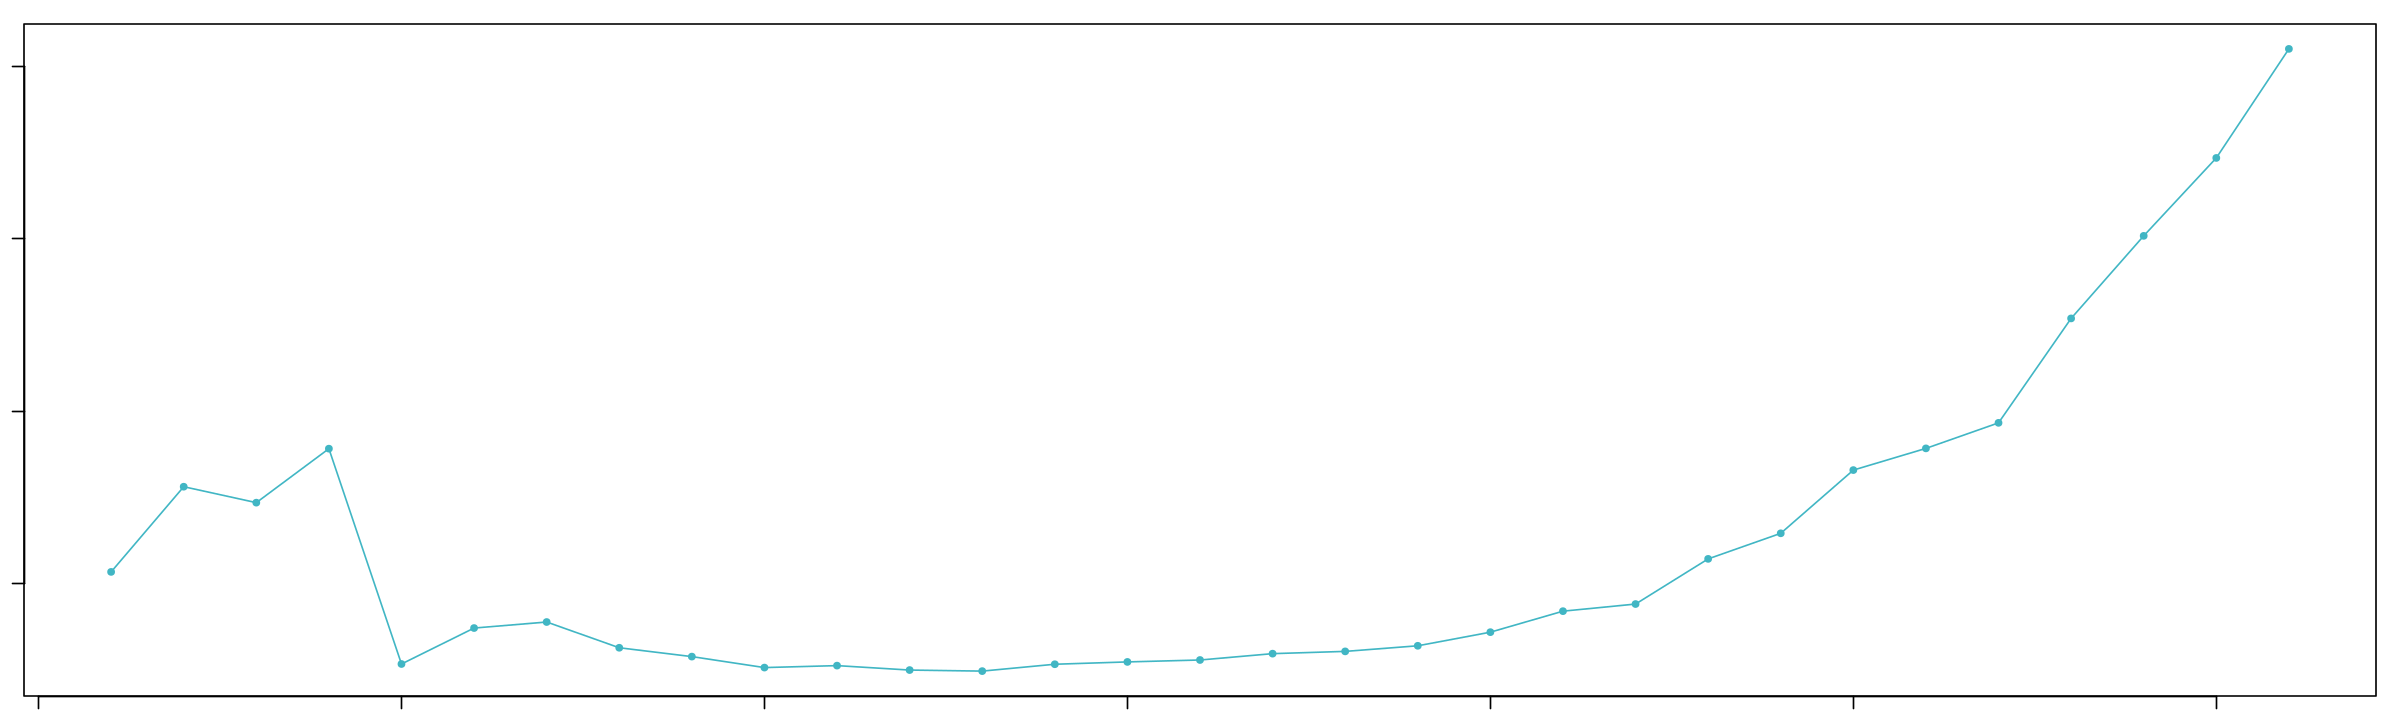

NULL


Using pK = 0.02...



[1] "Creating 2584 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


...

[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


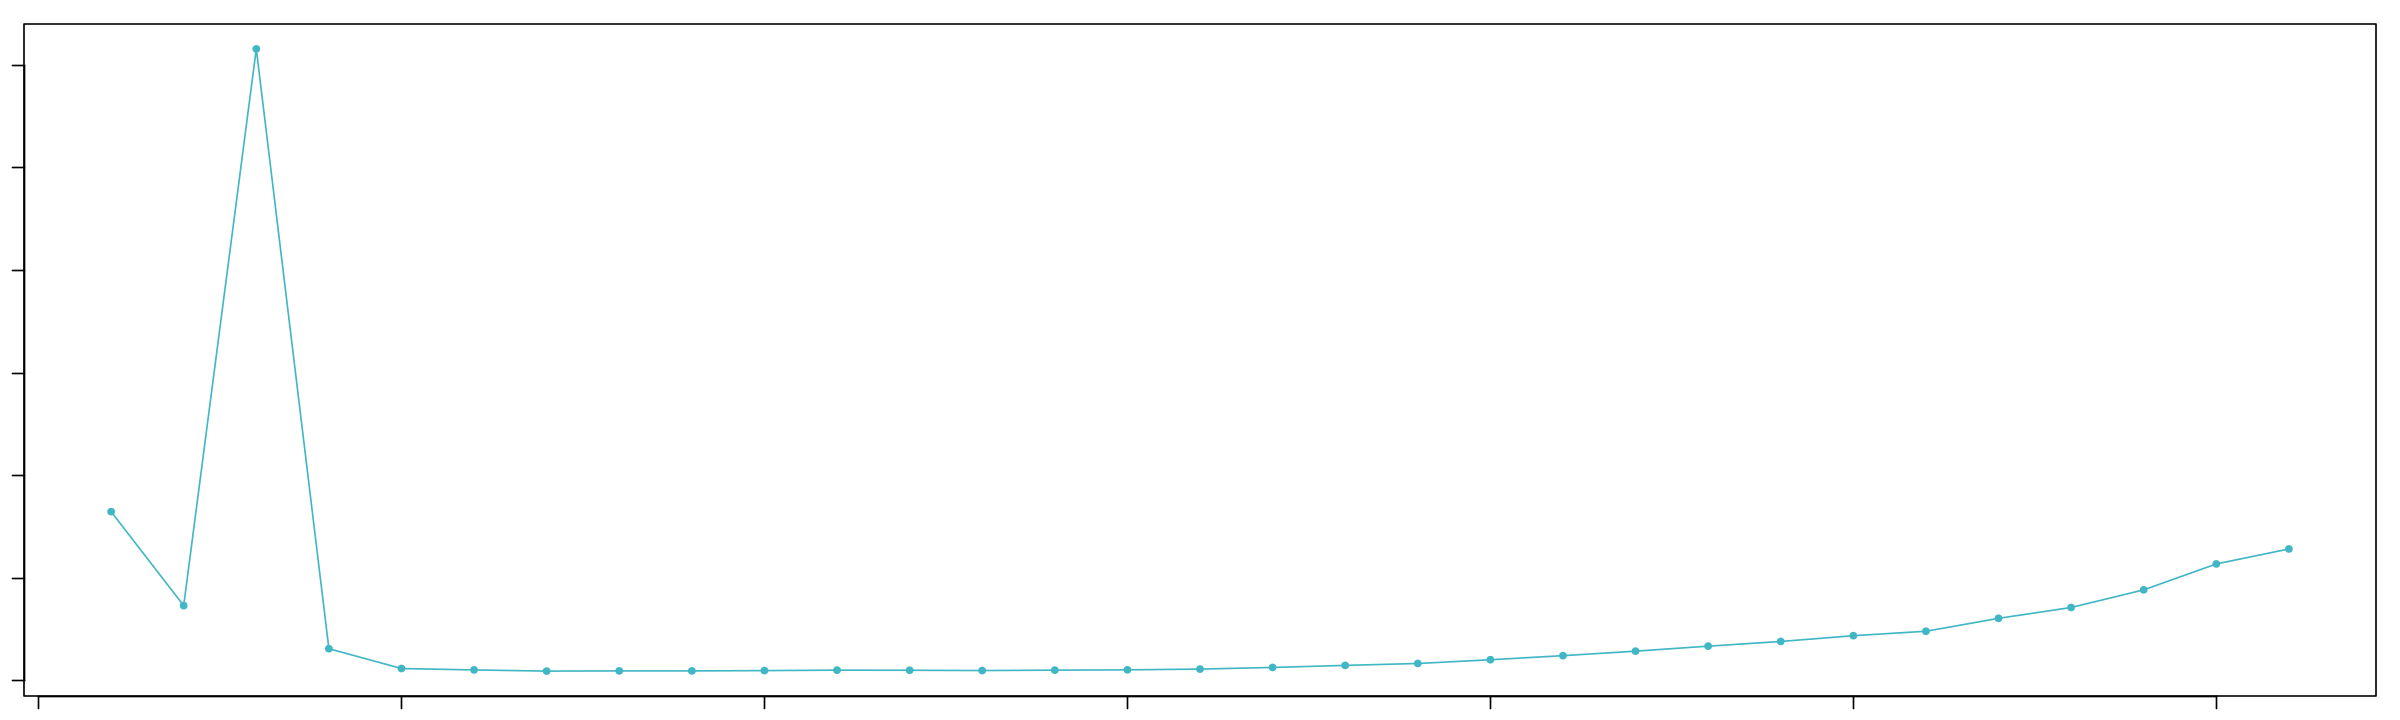

NULL


Using pK = 0.02...



[1] "Creating 2598 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


...

[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


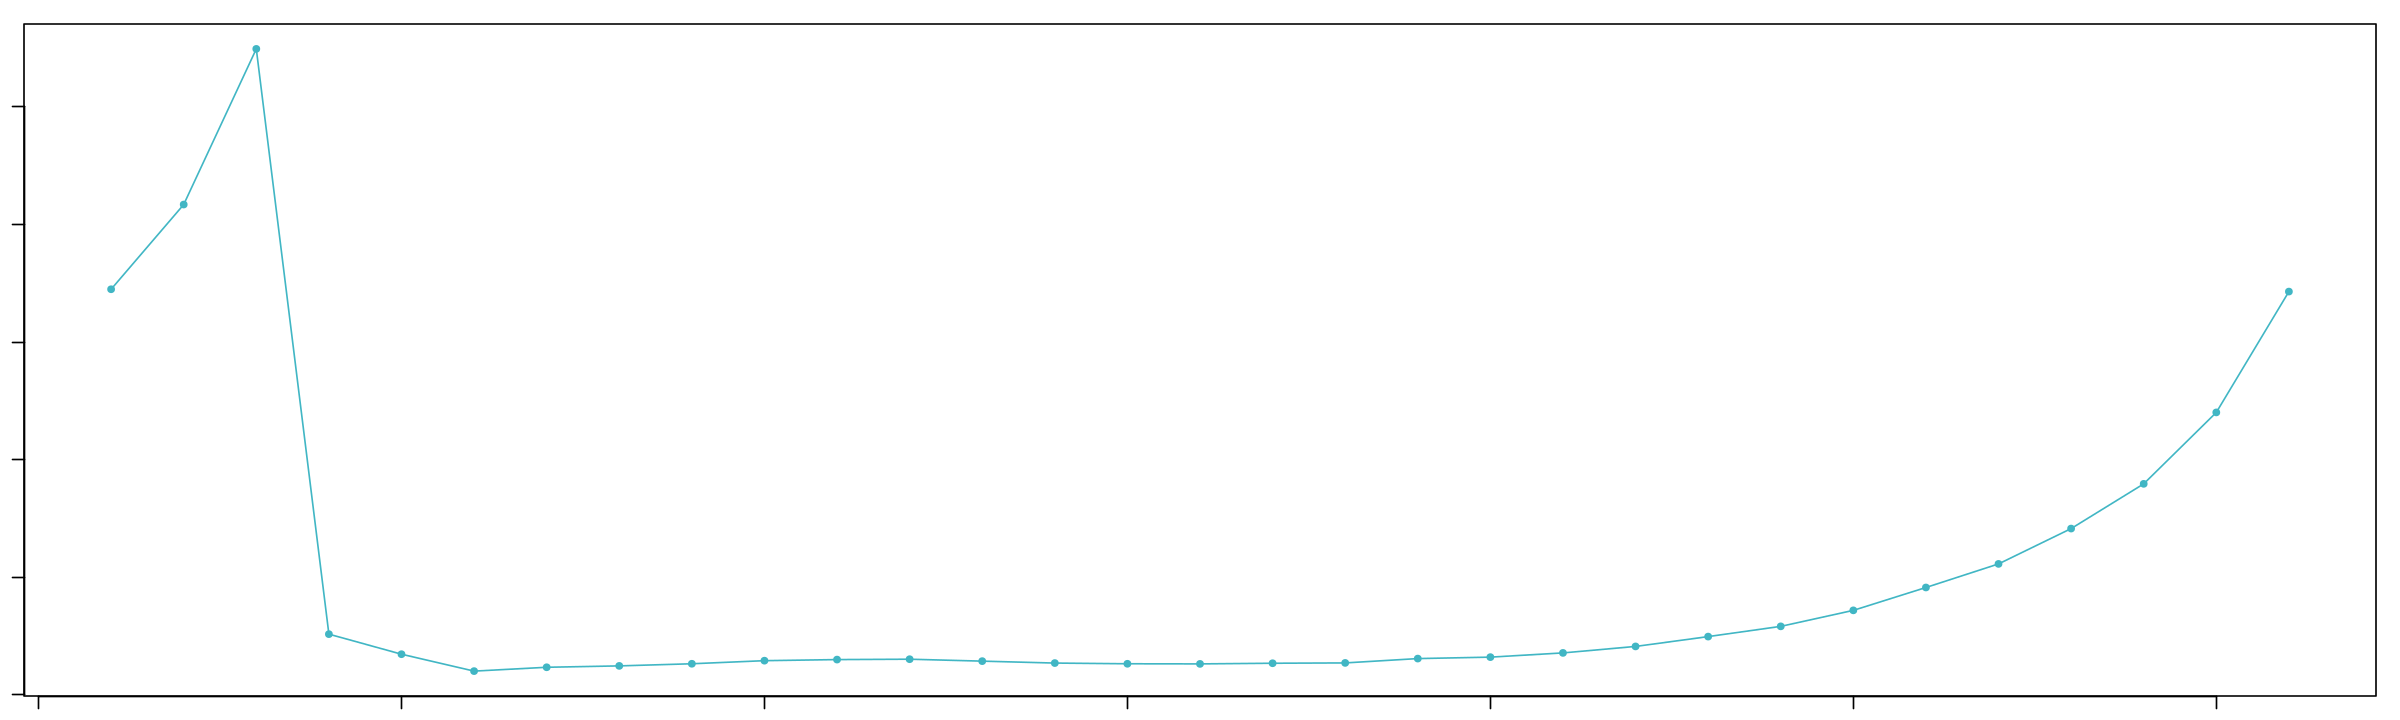

NULL


Using pK = 0.02...



[1] "Creating 2039 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


...

[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


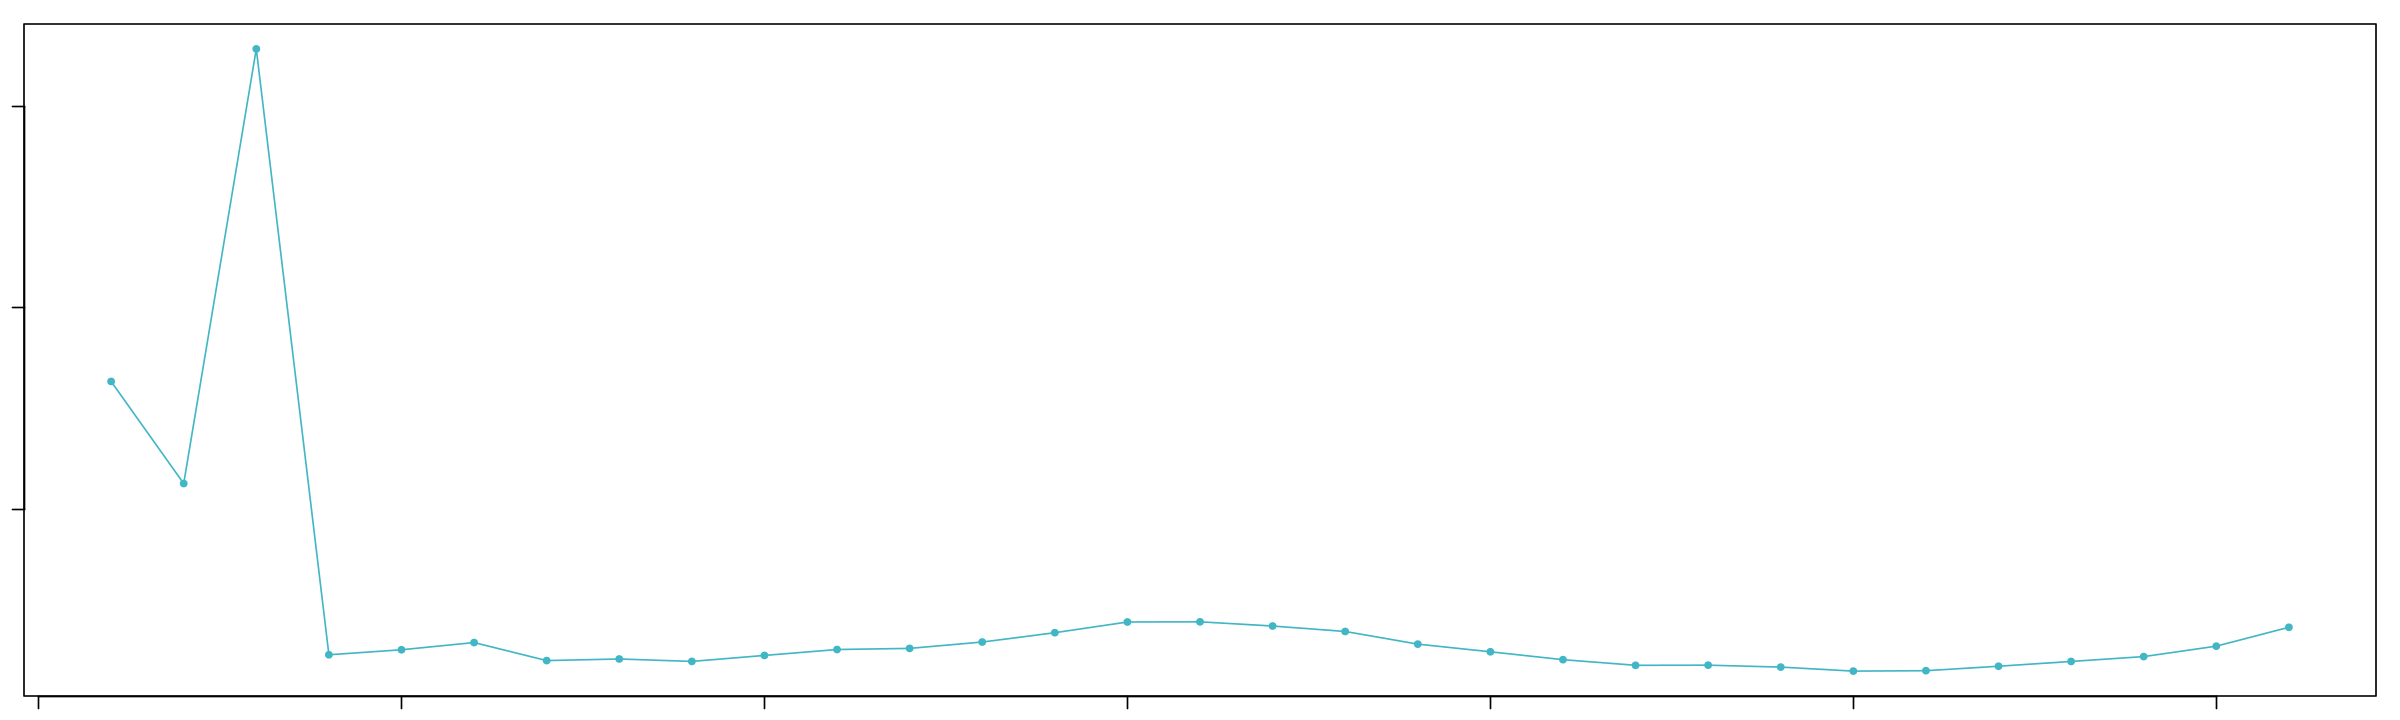

NULL


Using pK = 0.02...



[1] "Creating 2514 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


...

[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.001..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


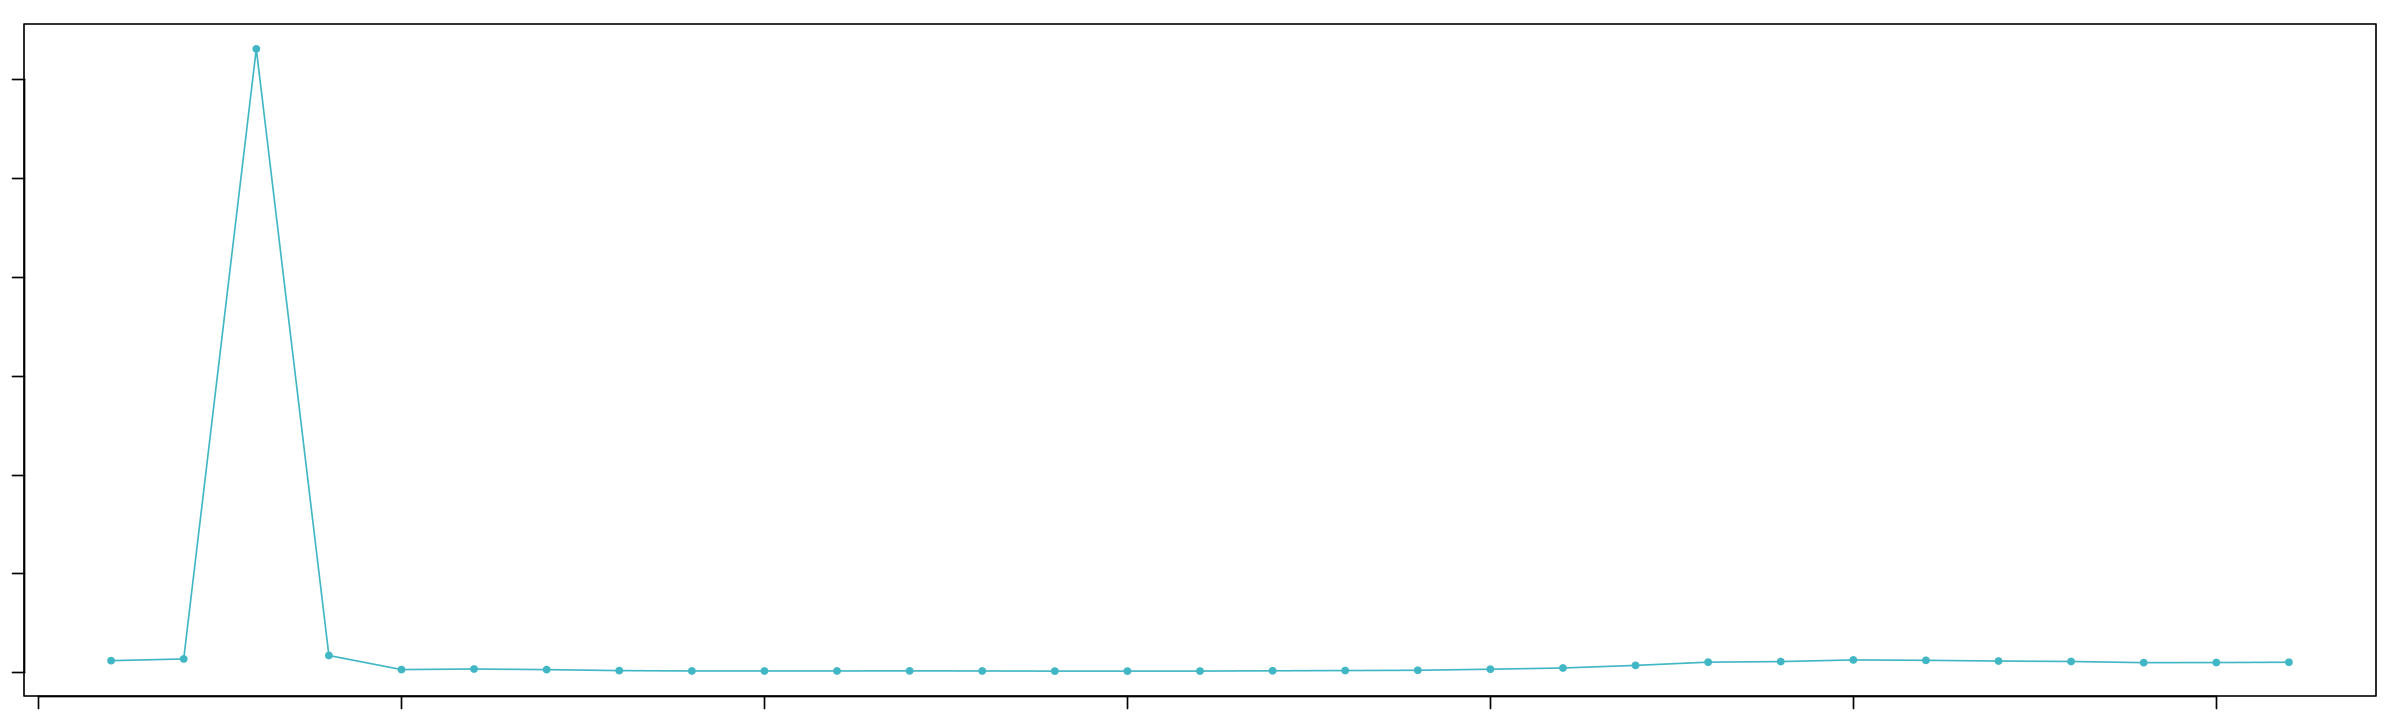

NULL


Using pK = 0.05...



[1] "Creating 4335 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


...

[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.001..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


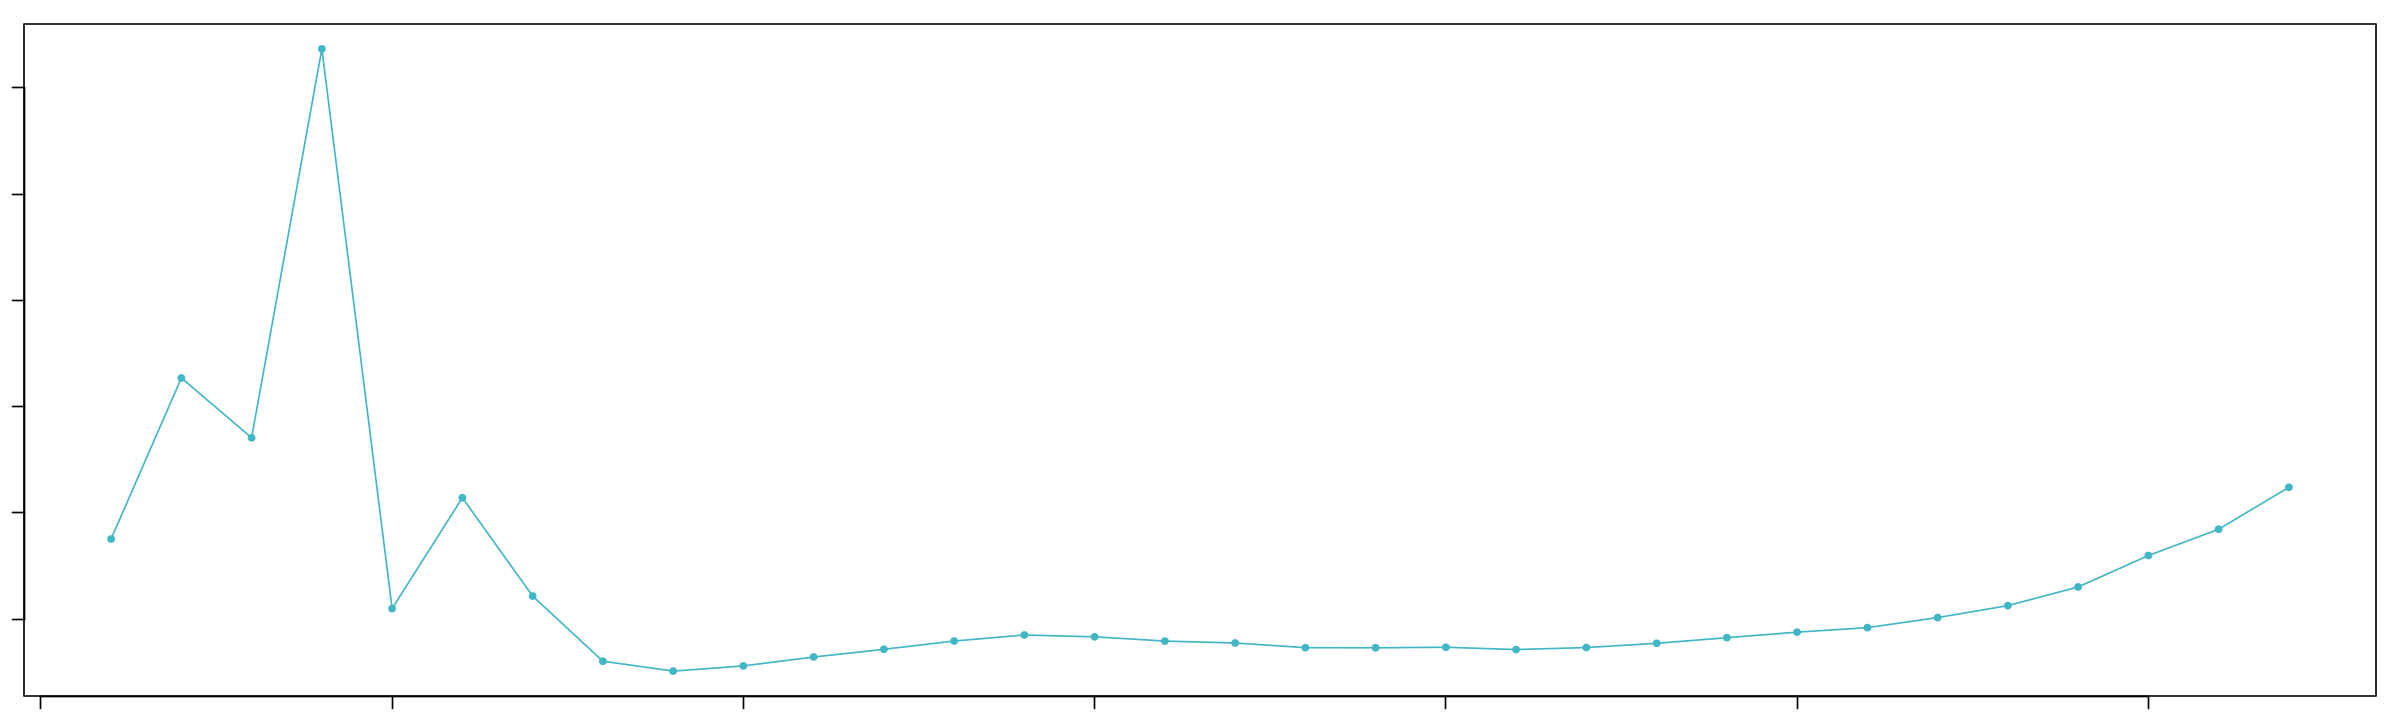

NULL


Using pK = 0.05...



[1] "Creating 4187 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


...

[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.001..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


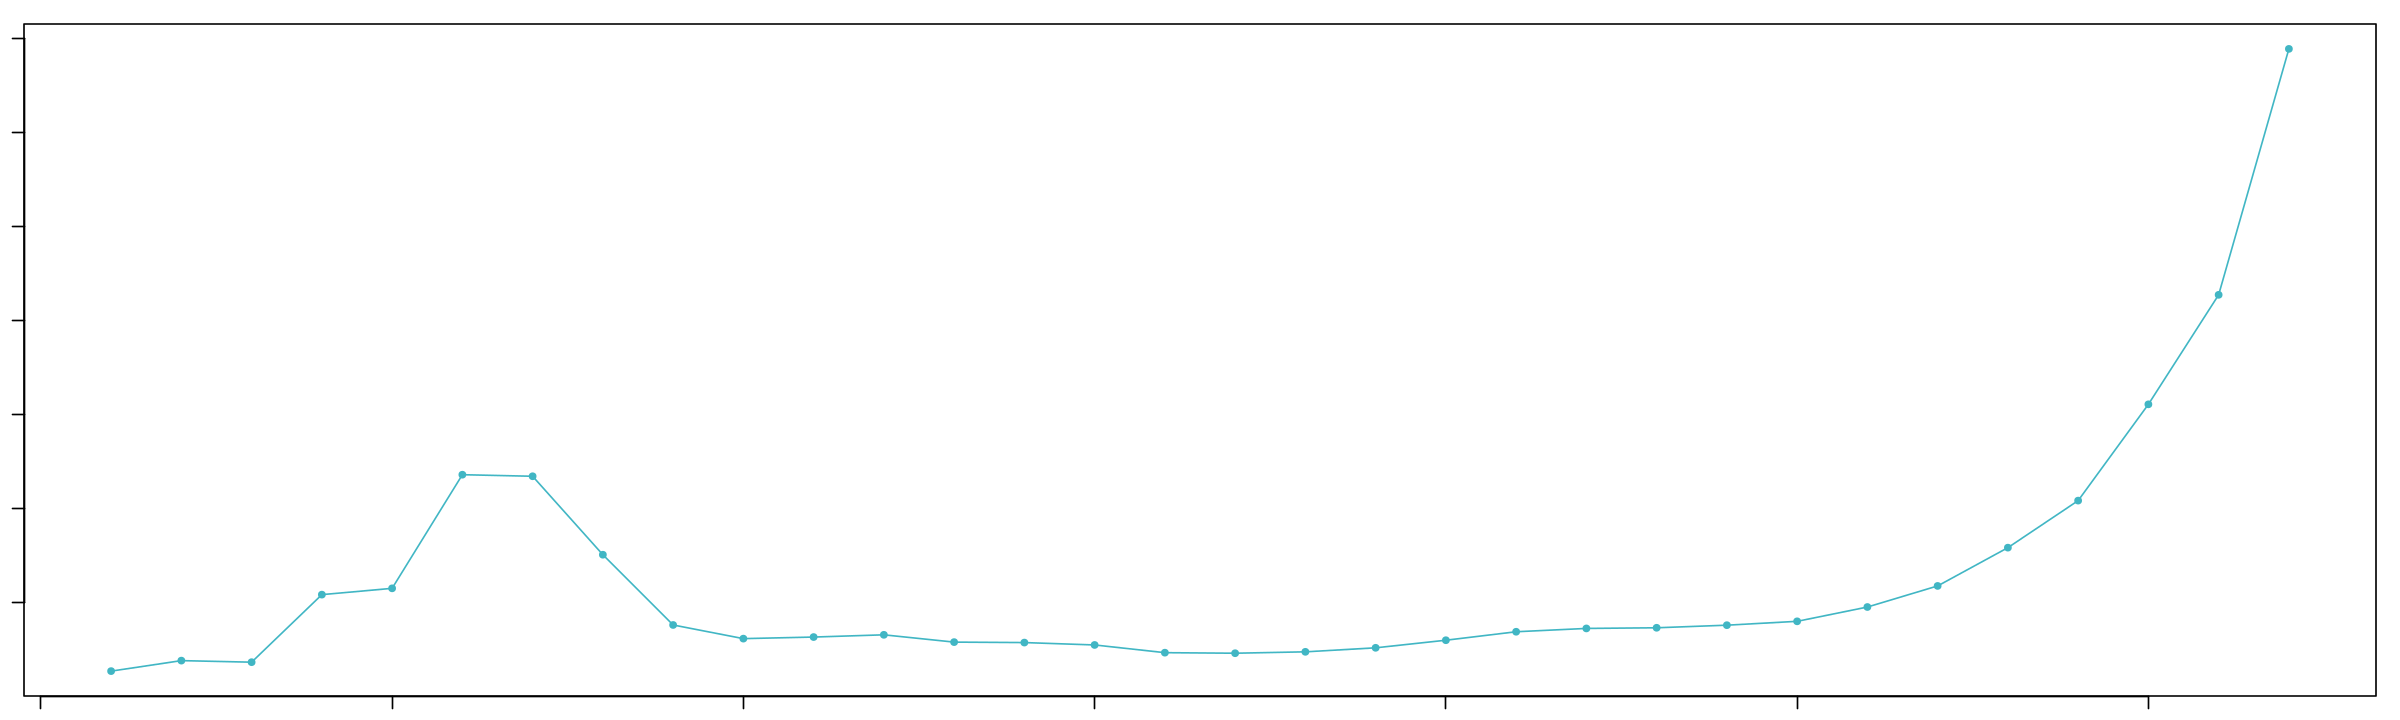

NULL


Using pK = 0.04...



[1] "Creating 4266 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


...

[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


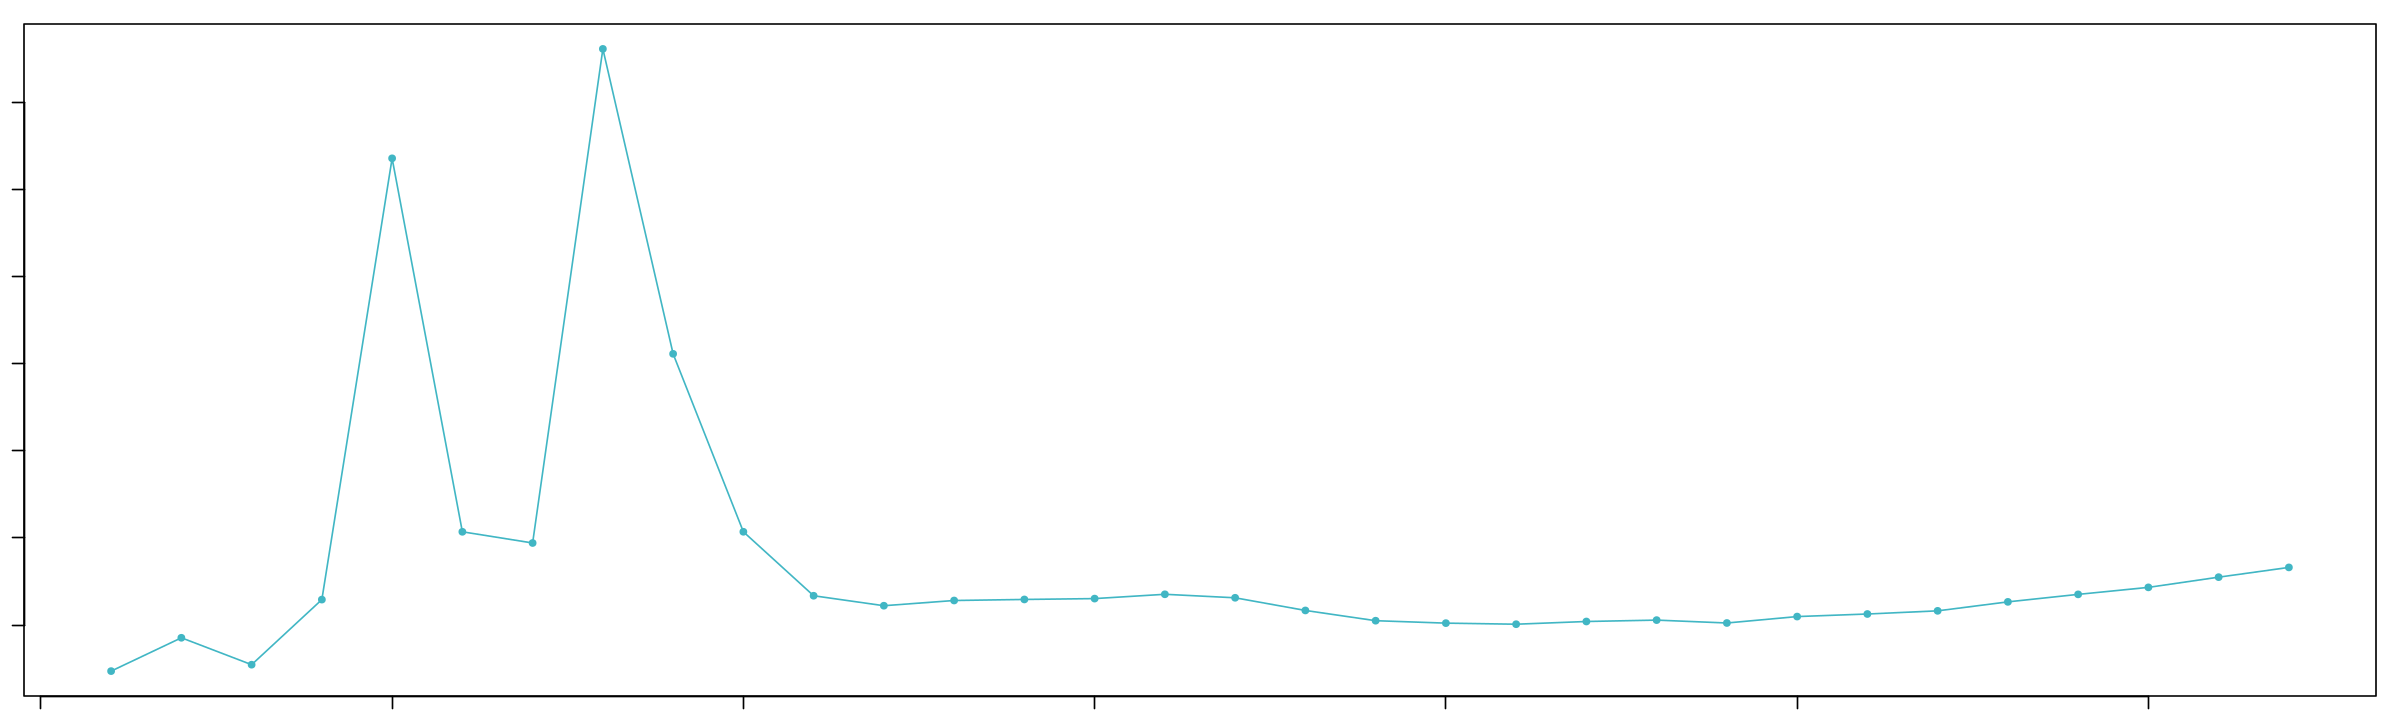

NULL


Using pK = 0.005...



[1] "Creating 2732 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


...

[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


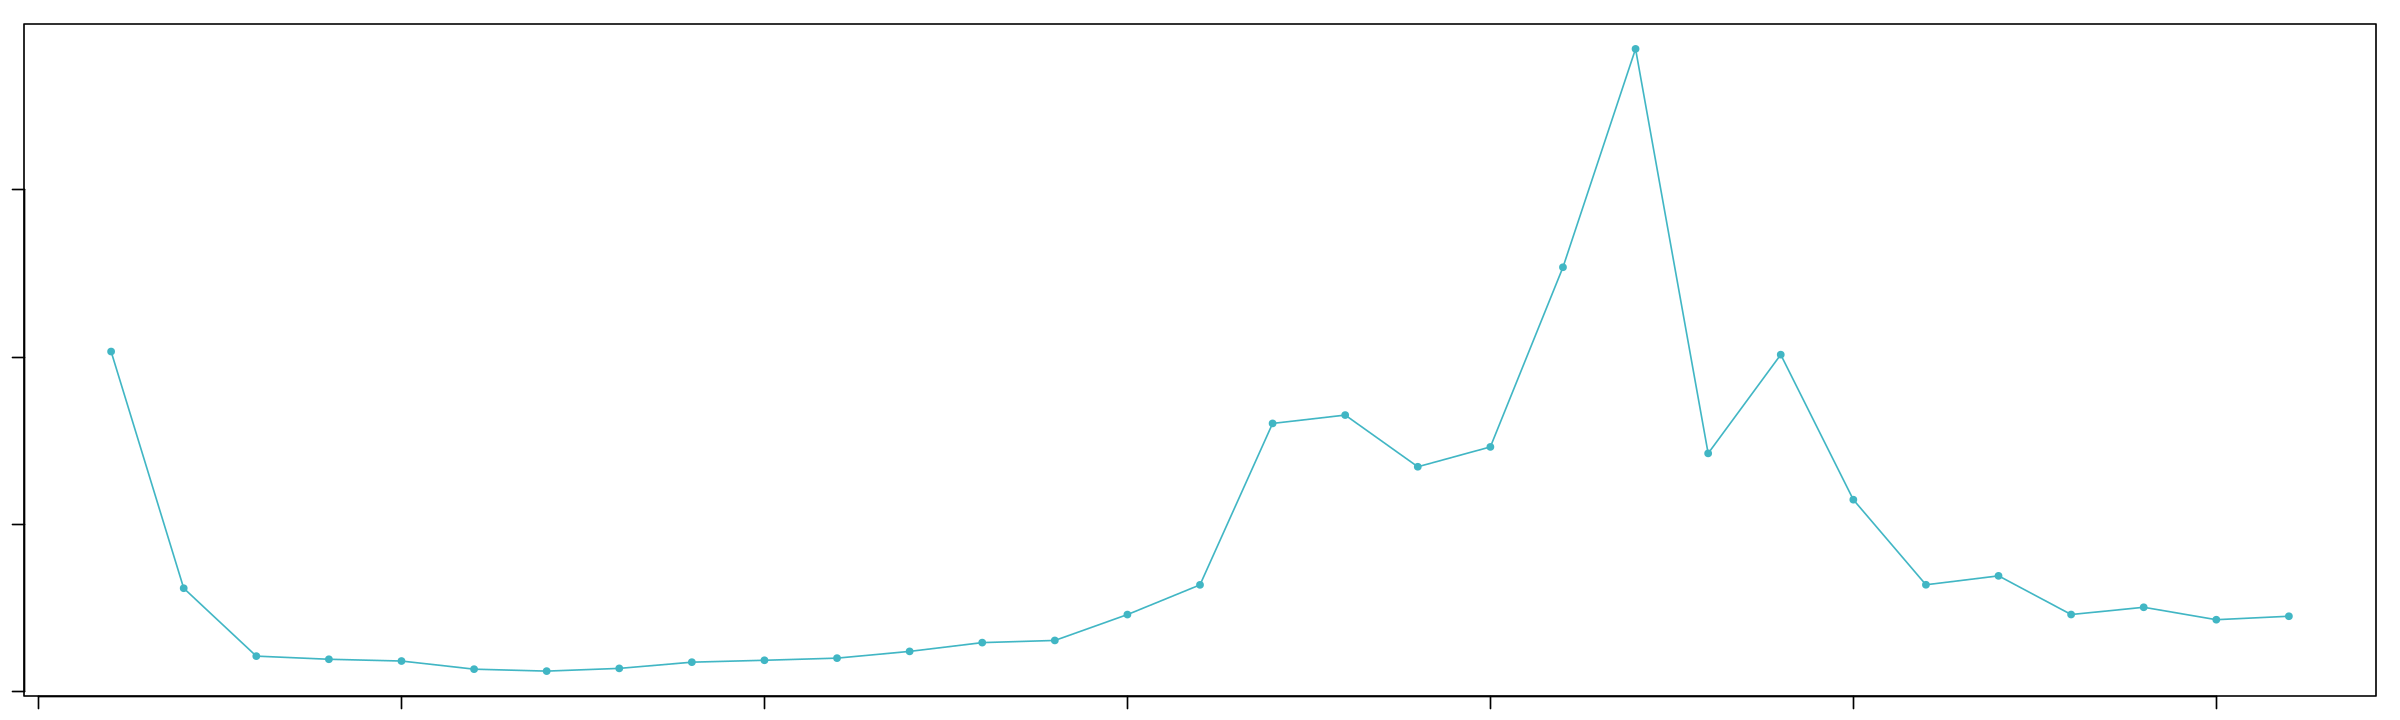

NULL


Using pK = 0.005...



[1] "Creating 2432 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


...

[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


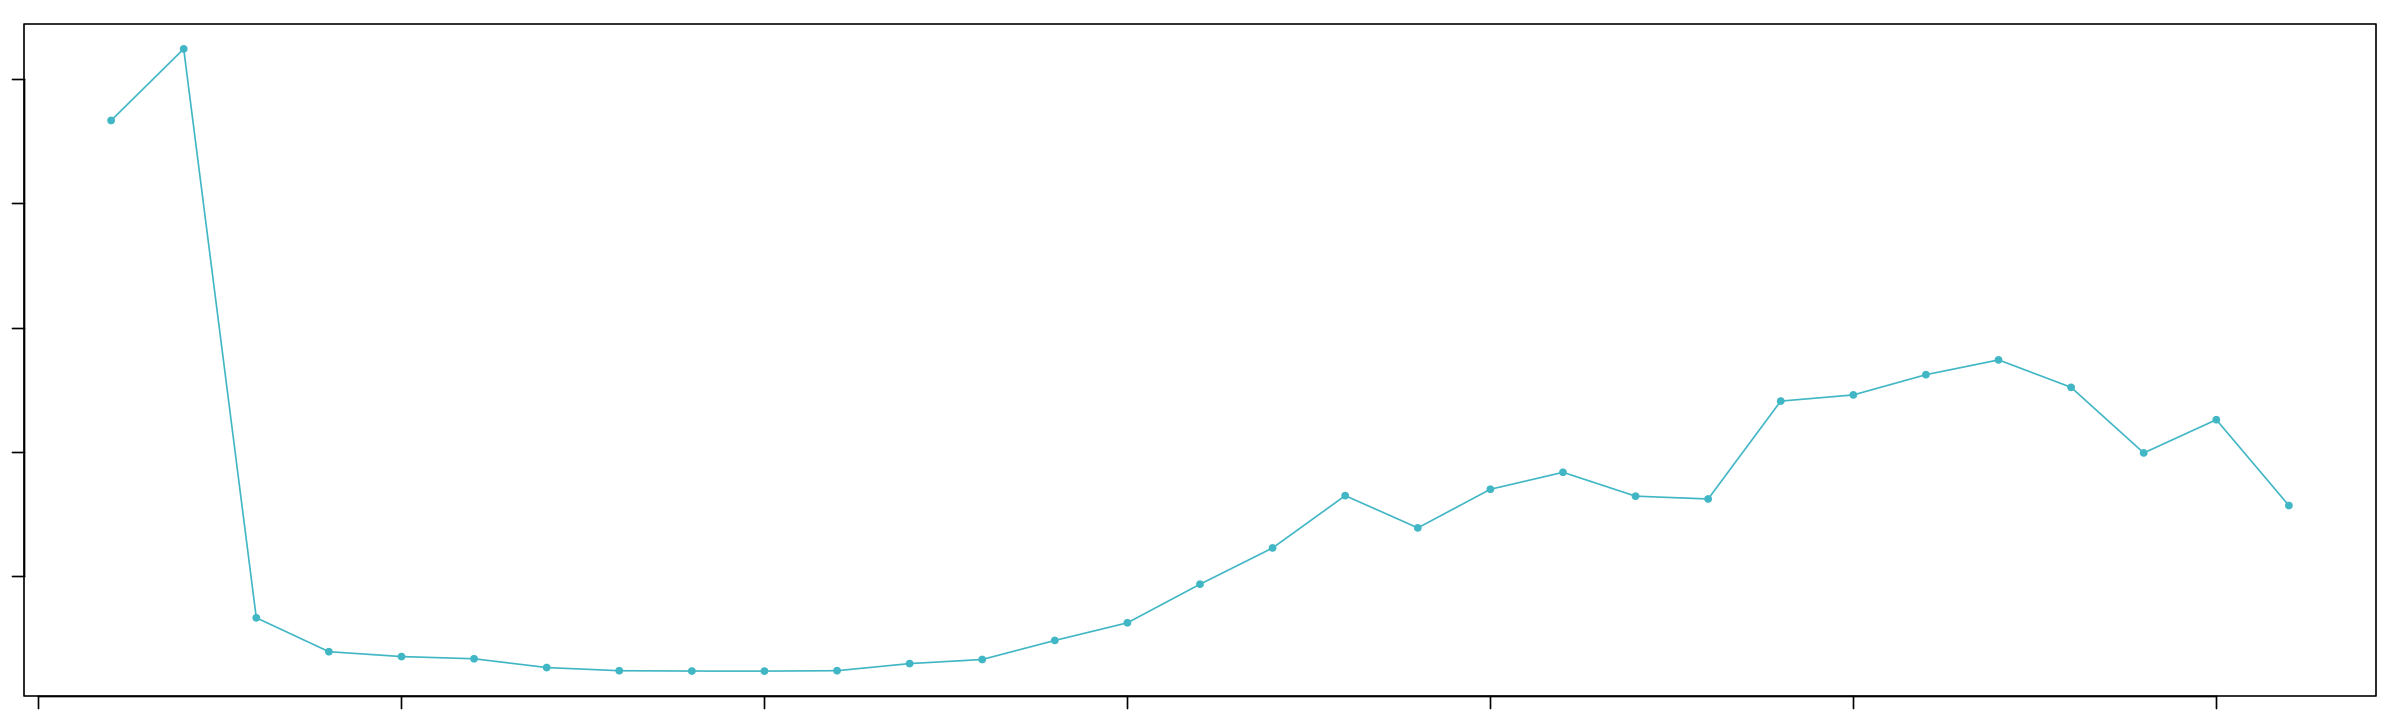

NULL


Using pK = 0.3...



[1] "Creating 2656 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


...

[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


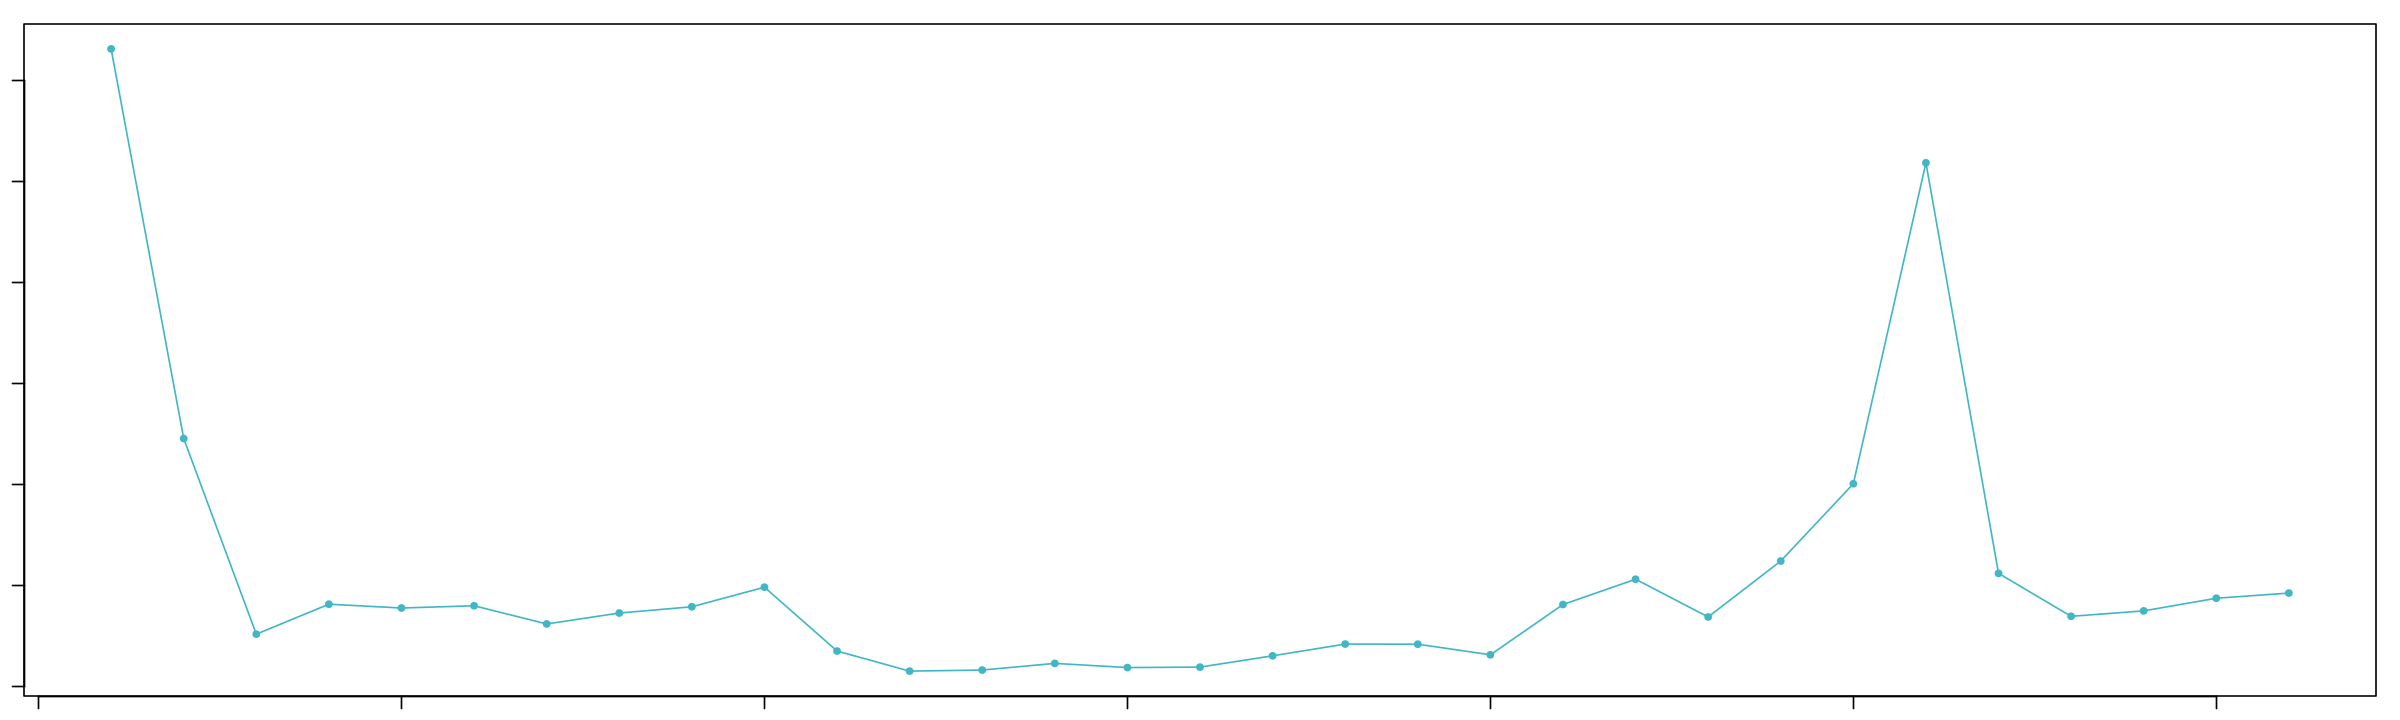

NULL


Using pK = 0.3...



[1] "Creating 2686 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


...

[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


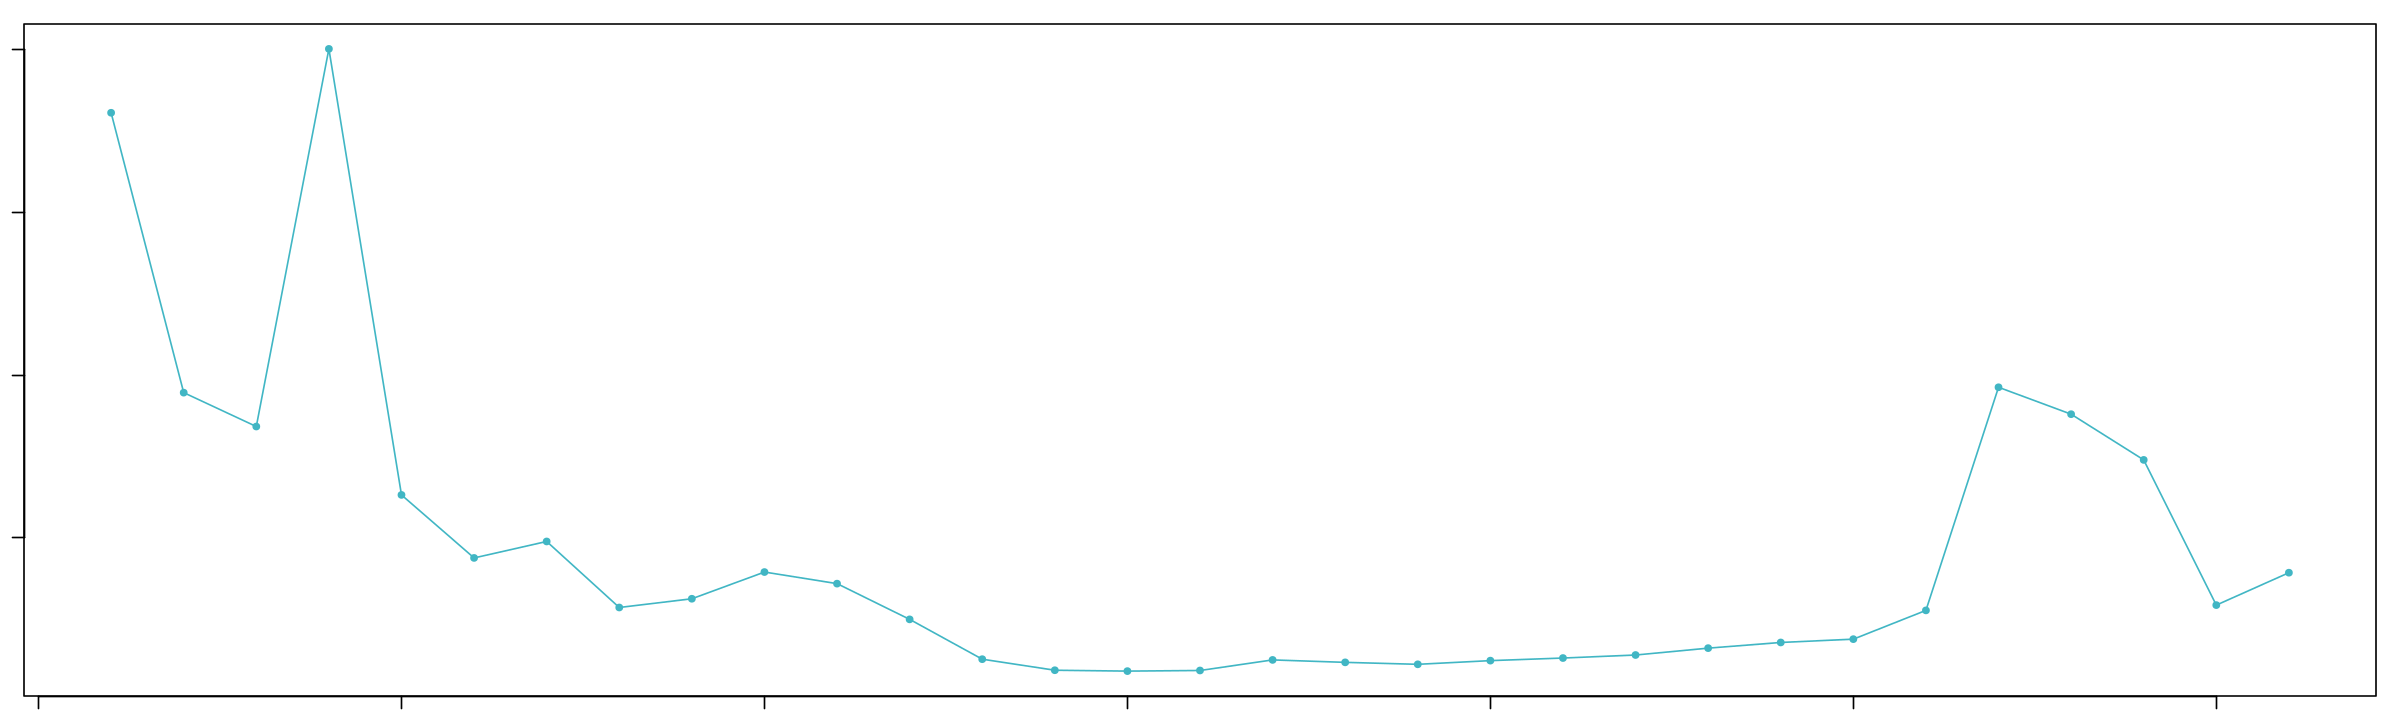

NULL


Using pK = 0.01...



[1] "Creating 2648 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


...

[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


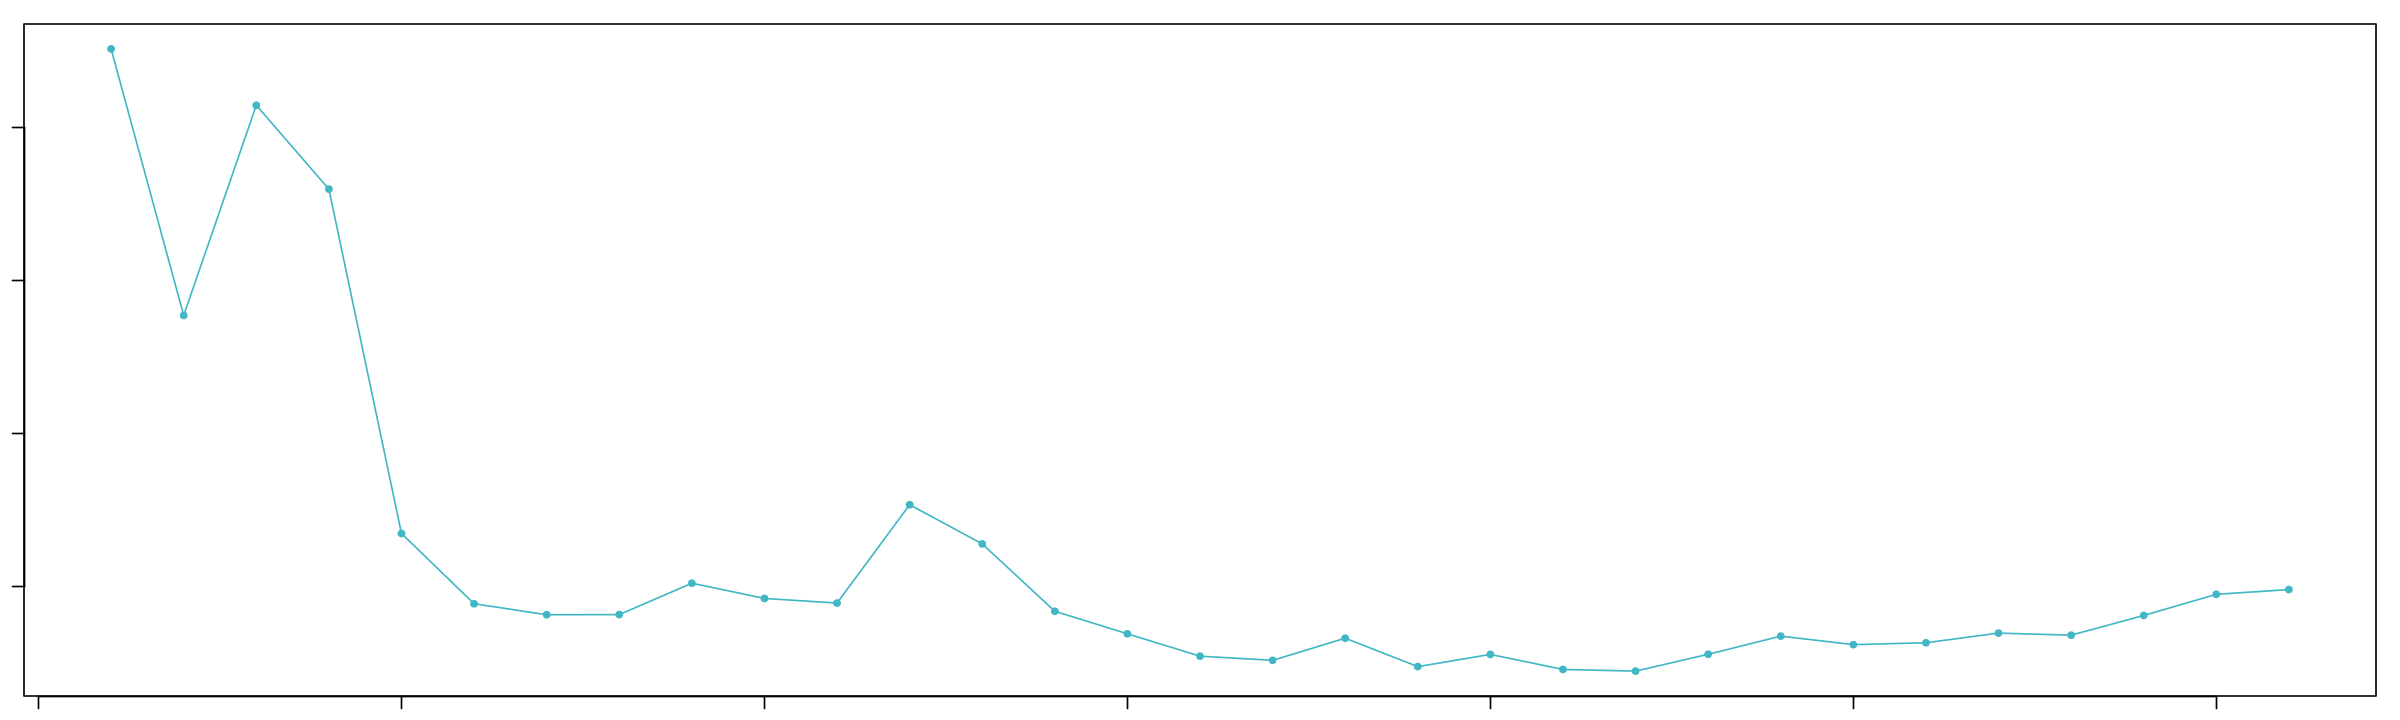

NULL


Using pK = 0.06...



[1] "Creating 2278 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


...

[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


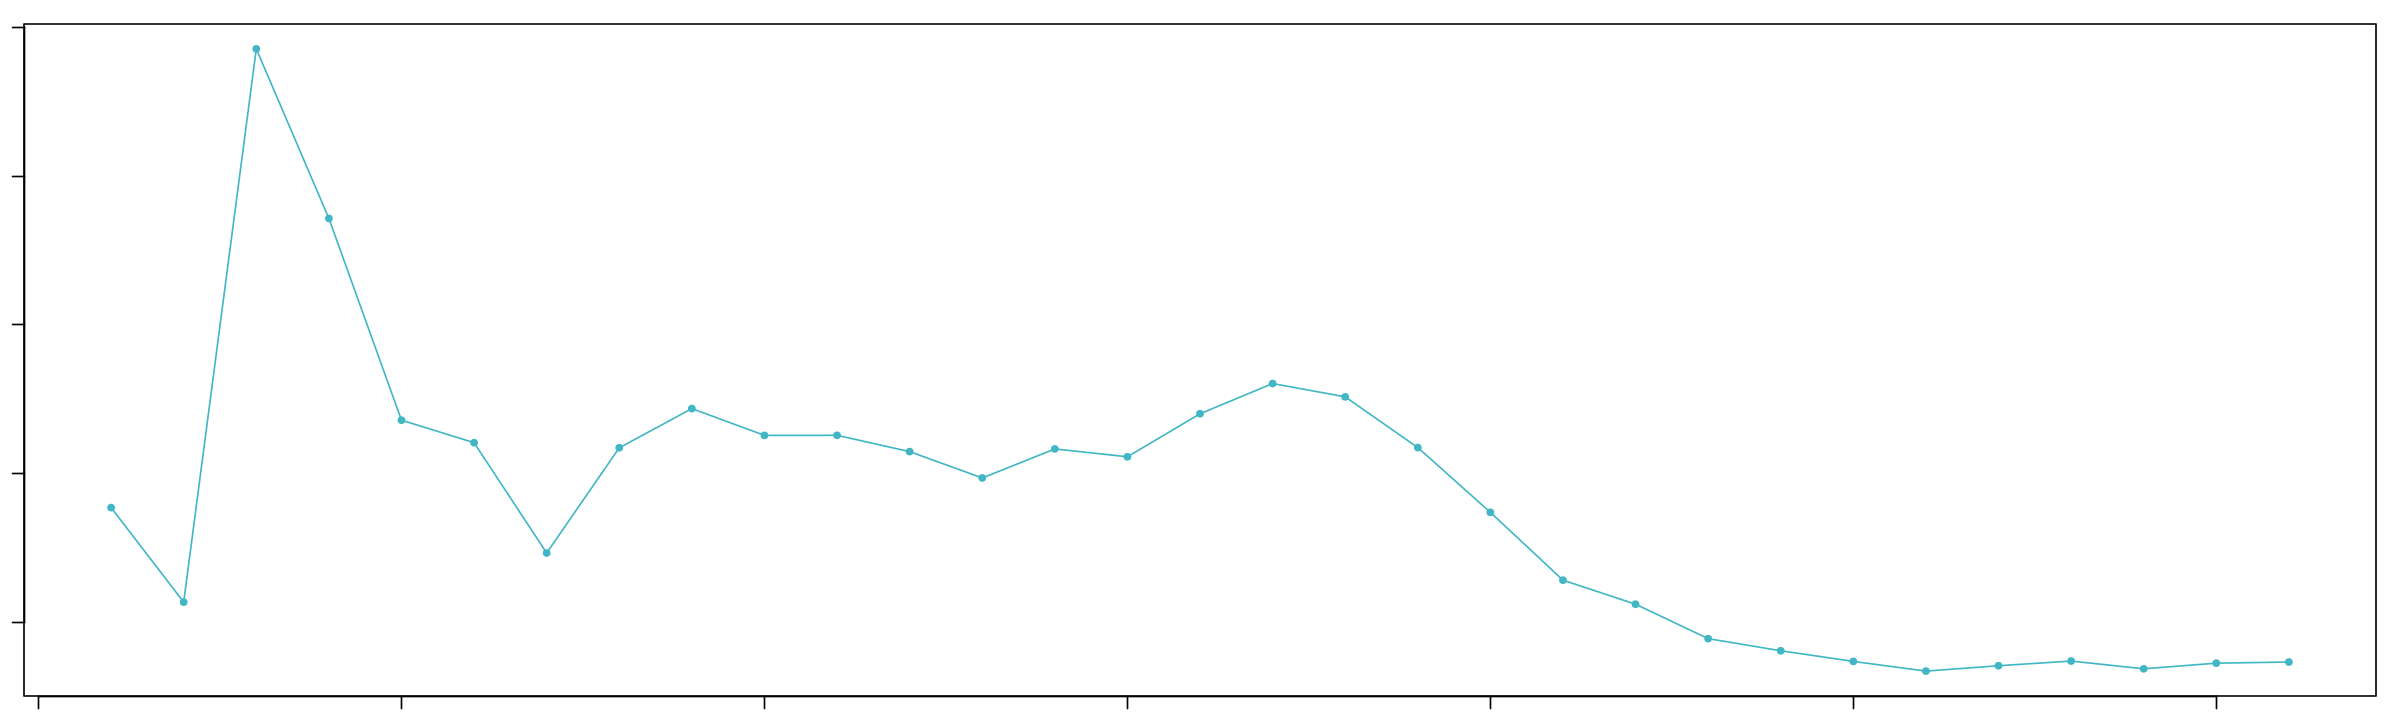

NULL


Using pK = 0.07...



[1] "Creating 2164 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


...

[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


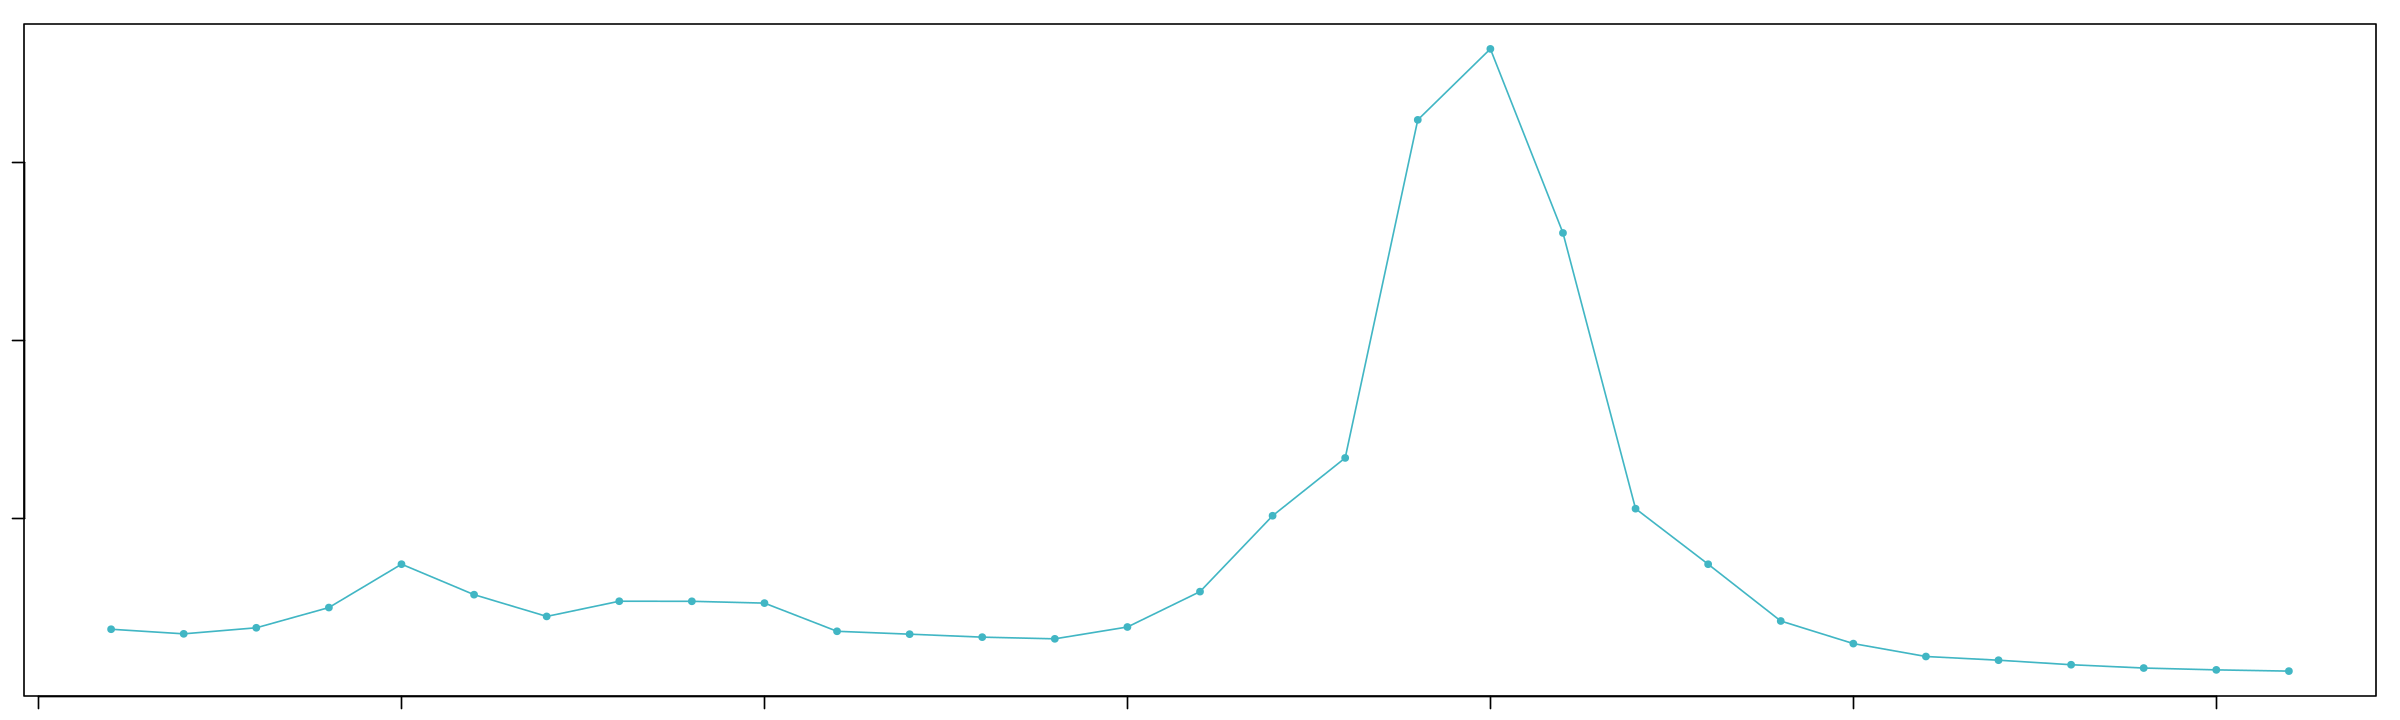

NULL


Using pK = 0.06...



[1] "Creating 2652 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


...

[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


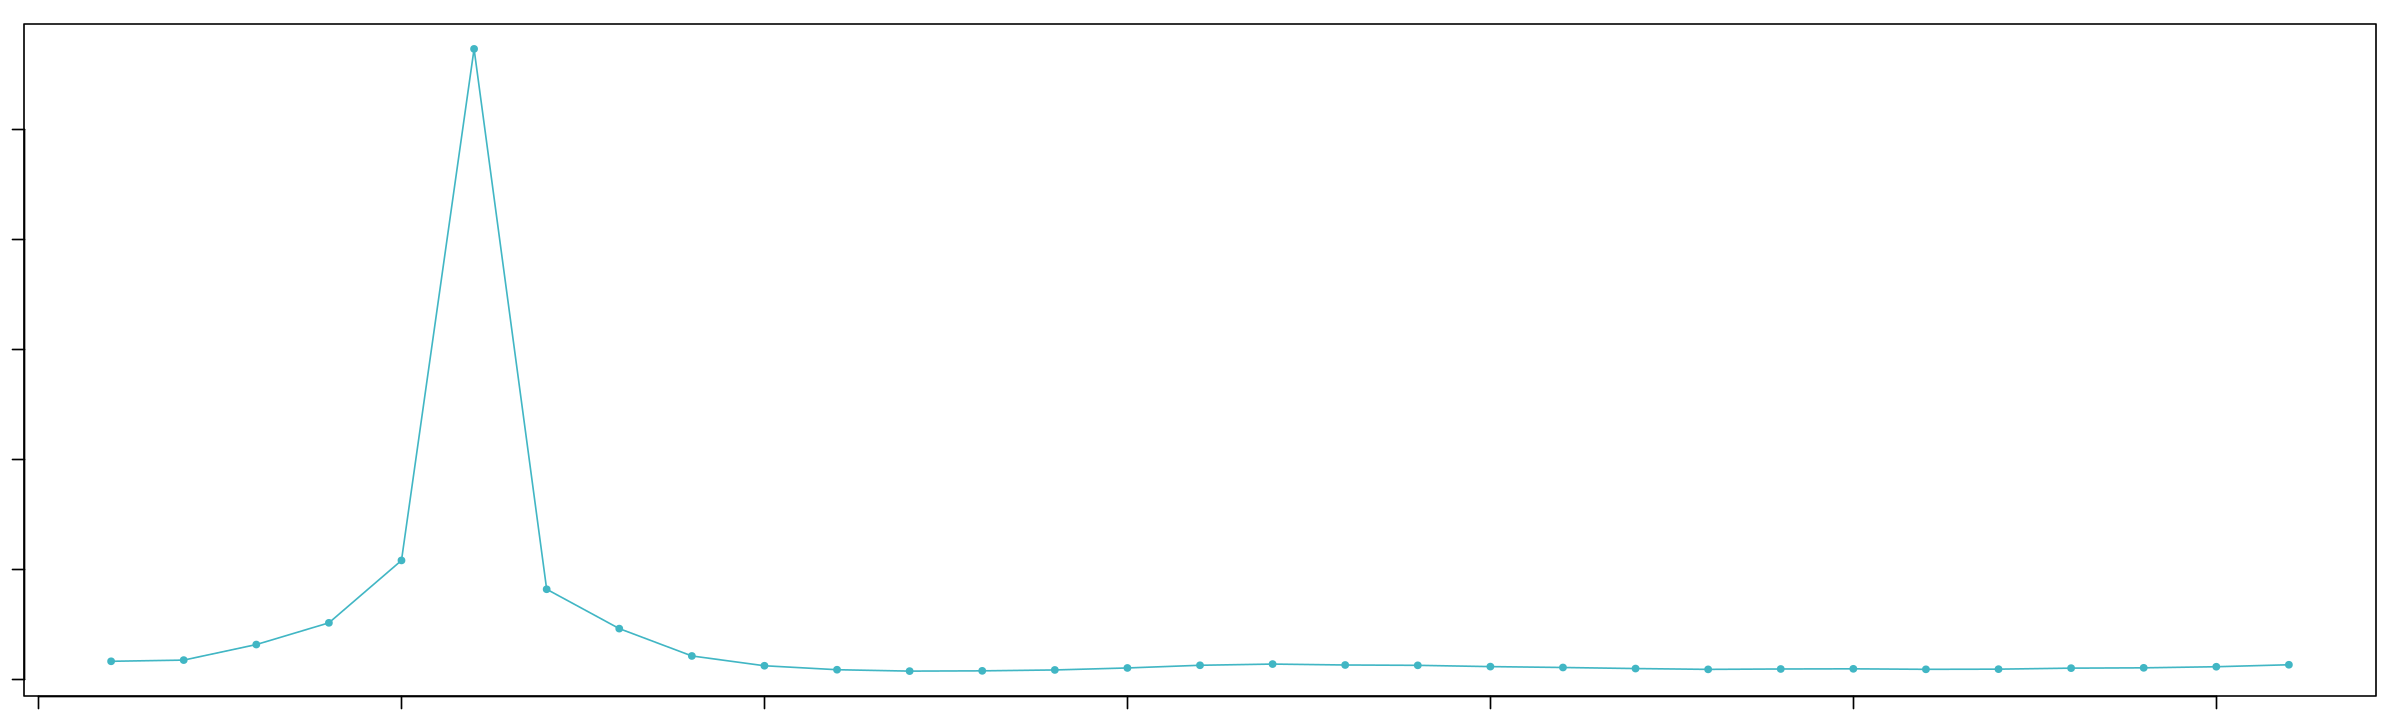

NULL


Using pK = 0.03...



[1] "Creating 2384 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


...

[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


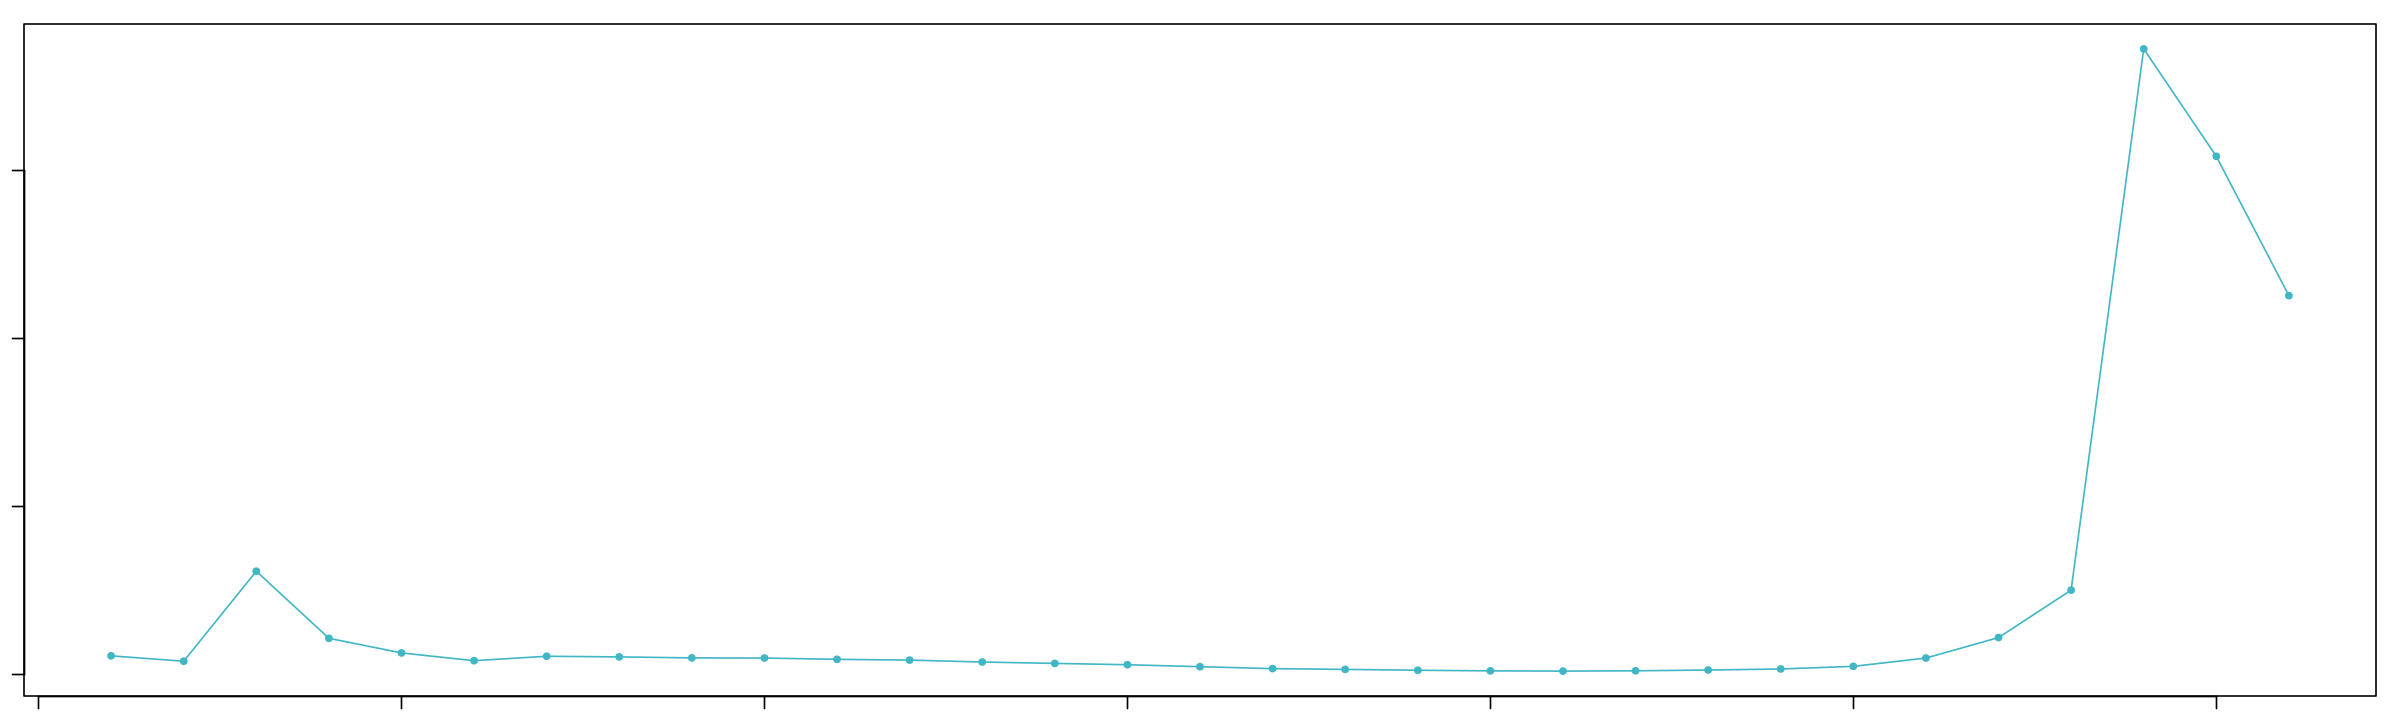

NULL


Using pK = 0.01...



[1] "Creating 2617 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


...

[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


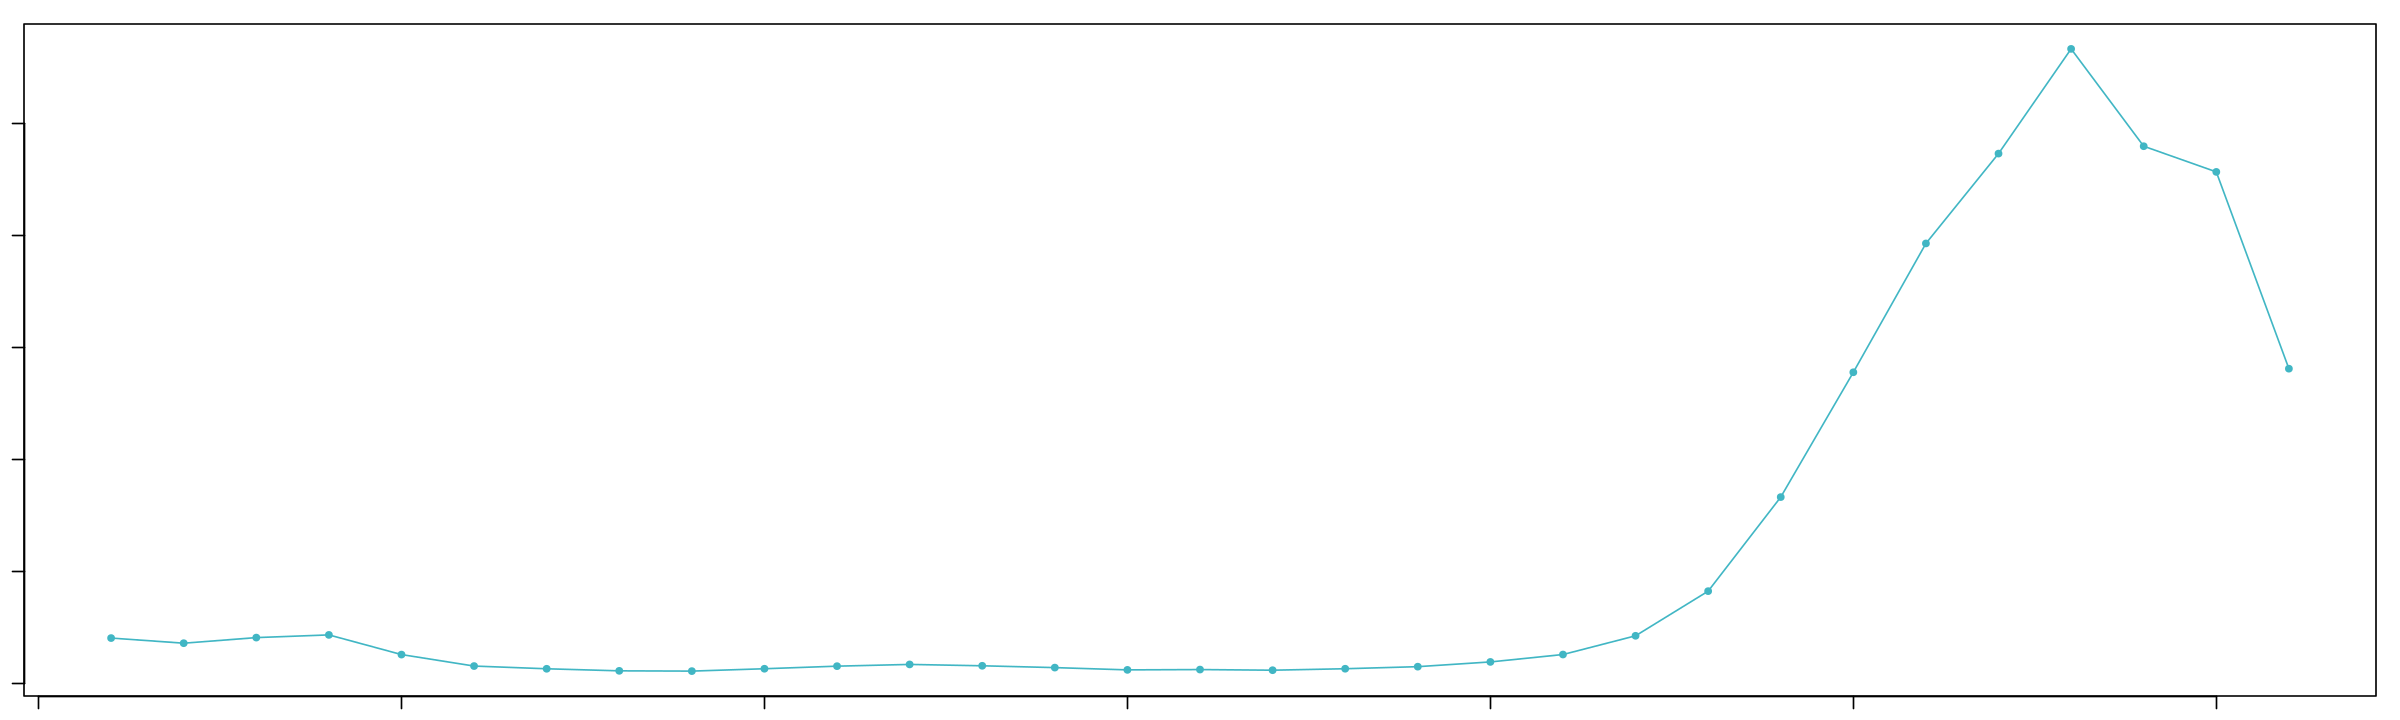

NULL


Using pK = 0.3...



[1] "Creating 2552 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Computing pANN..."
[1] "Classifying doublets.."


Using pANN = pANN_0.25_0.3_338...



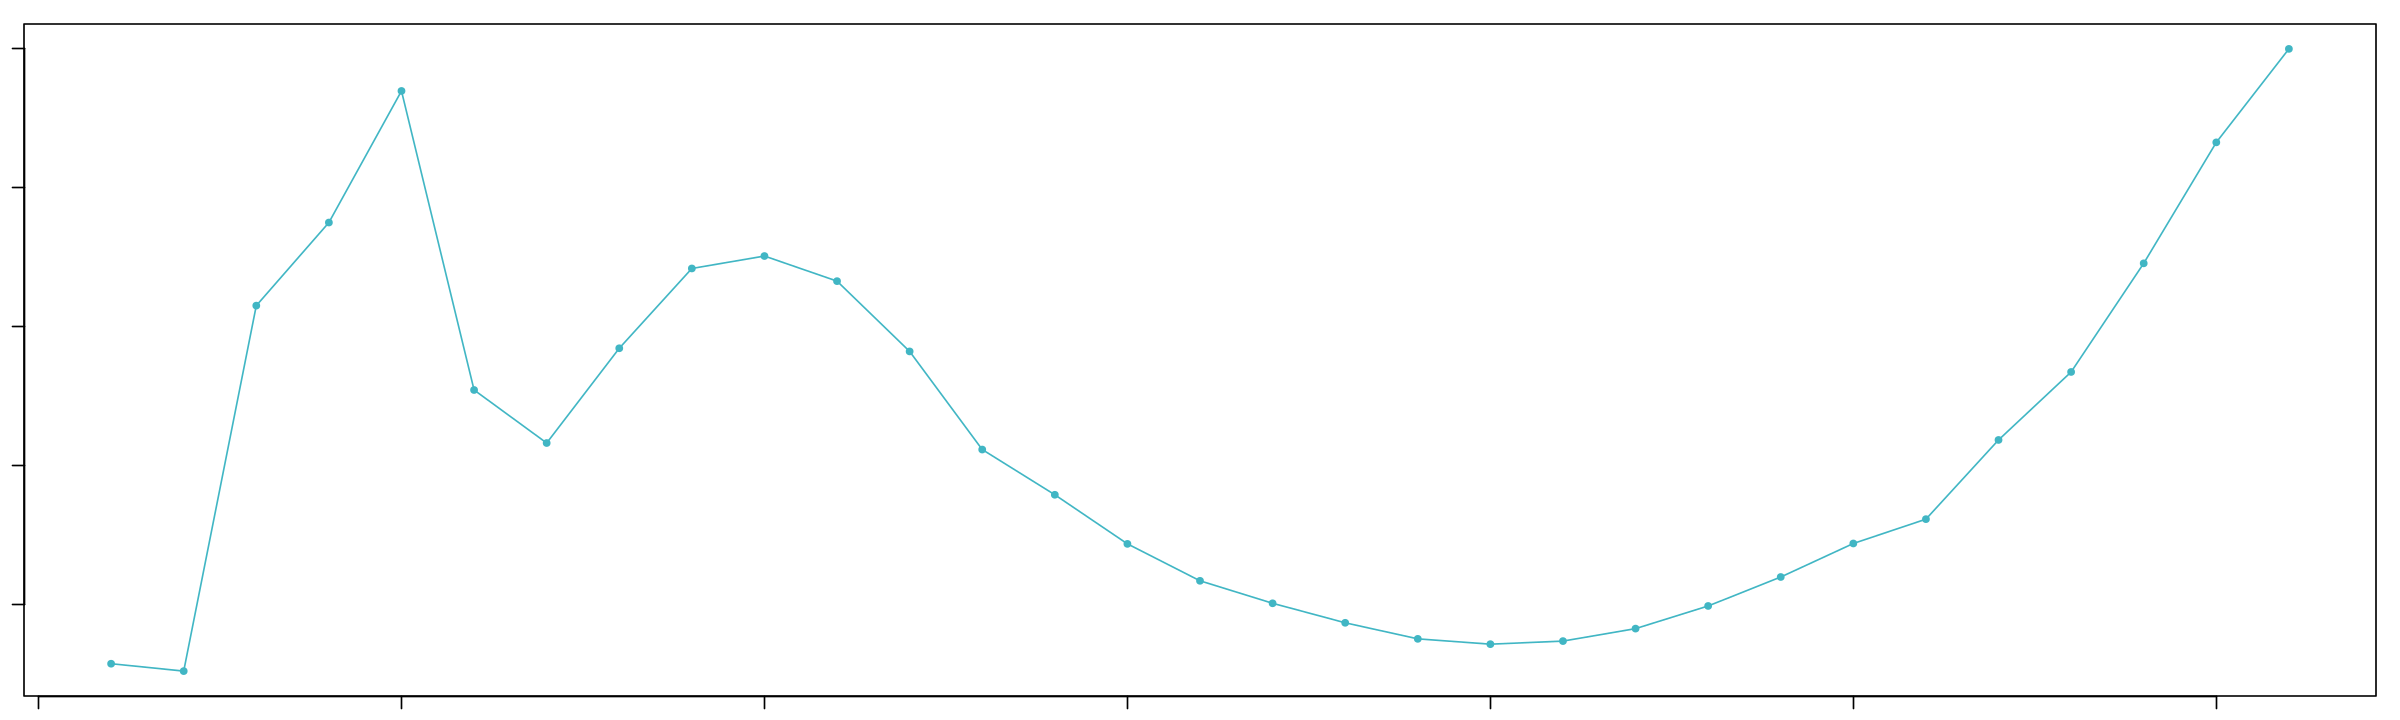

In [94]:
# outliers and doublets
for (i in 1:length(seurat.list)){
    # outliers
    seurat.list[[i]] <- subset(seurat.list[[i]], subset = nCount_RNA > 100)
    outlier <- is_outlier(seurat.list[[i]], "nCount_RNA", 4) | 
                is_outlier(seurat.list[[i]], "nFeature_RNA", 4) | 
                is_outlier(seurat.list[[i]], "percent.mt", 4) |
                is_outlier(seurat.list[[i]], "percent.ribo", 4)
    seurat.list[[i]]$outlier <- outlier
    # doublets
    # seurat.list[[i]] <- runscDblFinder(seurat.list[[i]], assay='RNA')
    seurat.list[[i]] <- Process_RNA(seurat.list[[i]])
    seurat.list[[i]] <- Find_doublet1(seurat.list[[i]],1:20)
}
saveRDS(seurat.list,'/data/bio_data/data/scCAT_seq/00_scCAT_data/Embryo/processed/RNA/embro_RNA_soupx_seulist.rds')

In [9]:
seurat.list <- readRDS('/data/bio_data/embryo/00_rawdata/RNA/embro_RNA_soupx_seulist.rds')

In [10]:
# merge seulist
seurat.obj <- merge(x = seurat.list[[1]], y = seurat.list[c(1:length(seurat.list))[-1]])
saveRDS(seurat.obj,'/data/bio_data/embryo/00_rawdata/RNA/embro_RNA_soupx_seuobj.rds')

---

In [2]:
embryo_rna <- readRDS('/data/bio_data/embryo/00_rawdata/RNA/embro_RNA_soupx_seuobj.rds')

In [3]:
embryo_rna

An object of class Seurat 
28425 features across 156203 samples within 1 assay 
Active assay: RNA (28425 features, 2000 variable features)
 57 layers present: counts.1, counts.2, counts.3, counts.4, counts.5, counts.6, counts.7, counts.8, counts.9, counts.10, counts.11, counts.12, counts.13, counts.14, counts.15, counts.16, counts.17, counts.18, counts.19, data.1, scale.data.1, data.2, scale.data.2, data.3, scale.data.3, data.4, scale.data.4, data.5, scale.data.5, data.6, scale.data.6, data.7, scale.data.7, data.8, scale.data.8, data.9, scale.data.9, data.10, scale.data.10, data.11, scale.data.11, data.12, scale.data.12, data.13, scale.data.13, data.14, scale.data.14, data.15, scale.data.15, data.16, scale.data.16, data.17, scale.data.17, data.18, scale.data.18, data.19, scale.data.19

In [5]:
# embryo_rna <- DietSeurat(embryo_rna, layers = c('counts','data'))
embryo_rna <- DietSeurat(embryo_rna, layers = 'counts')
embryo_rna <- JoinLayers(embryo_rna, layers = "counts")

In [10]:
embryo_rna

An object of class Seurat 
28425 features across 156203 samples within 1 assay 
Active assay: RNA (28425 features, 2000 variable features)
 1 layer present: counts

In [11]:
saveRDS(embryo_rna,'/data/bio_data/embryo/00_rawdata/RNA/embro_RNA_soupx_seuobj.rds')

In [17]:
# blacklist.genes=GetBlackListGenes(embryo_rna, MT=TRUE, Ribo=TRUE, Cellcycle=FALSE, Sex=FALSE)
embryo_rna$sample <- sub("^([^_]+_[^_]+)_.*", "\\1", colnames(embryo_rna))
embryo_rna$Sample <- embryo_rna$orig.ident

In [18]:
embryo_rna

An object of class Seurat 
28425 features across 156203 samples within 1 assay 
Active assay: RNA (28425 features, 2000 variable features)
 1 layer present: counts

Warning message:
"Default search for "data" layer in "RNA" assay yielded no results; utilizing "counts" layer instead."
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



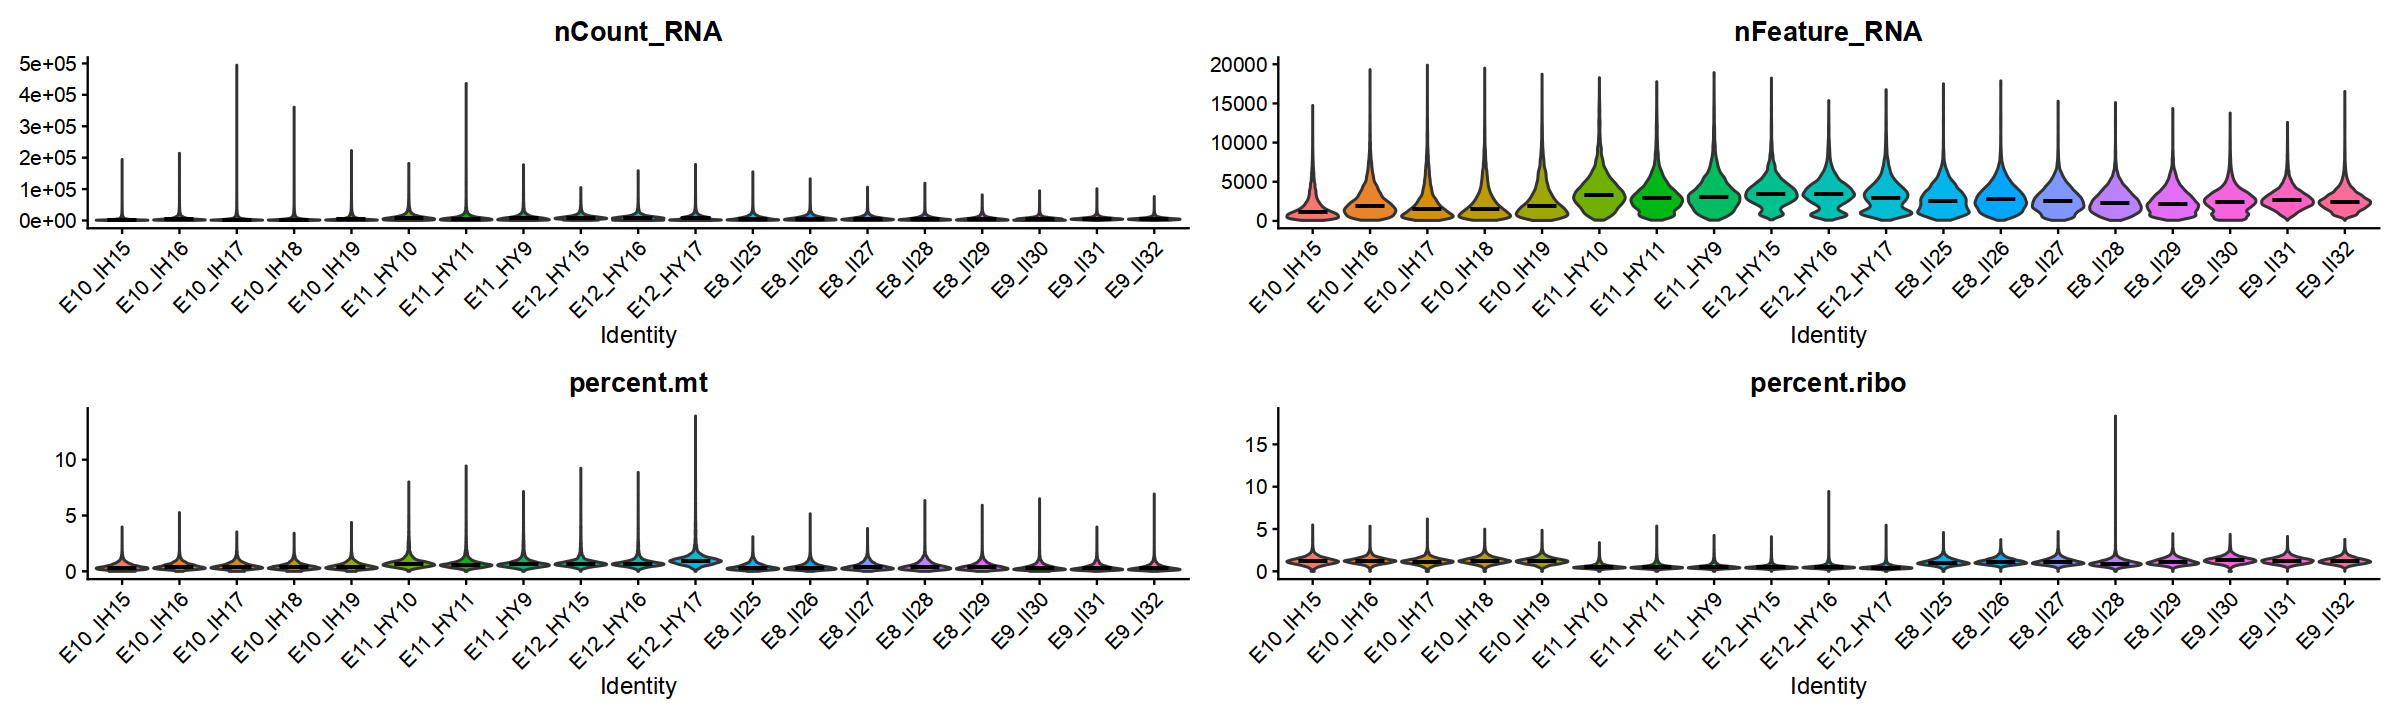

In [19]:
Plot_QC_RNA(embryo_rna, group='sample', width=20, height=6)

Warning message:
"Default search for "data" layer in "RNA" assay yielded no results; utilizing "counts" layer instead."
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



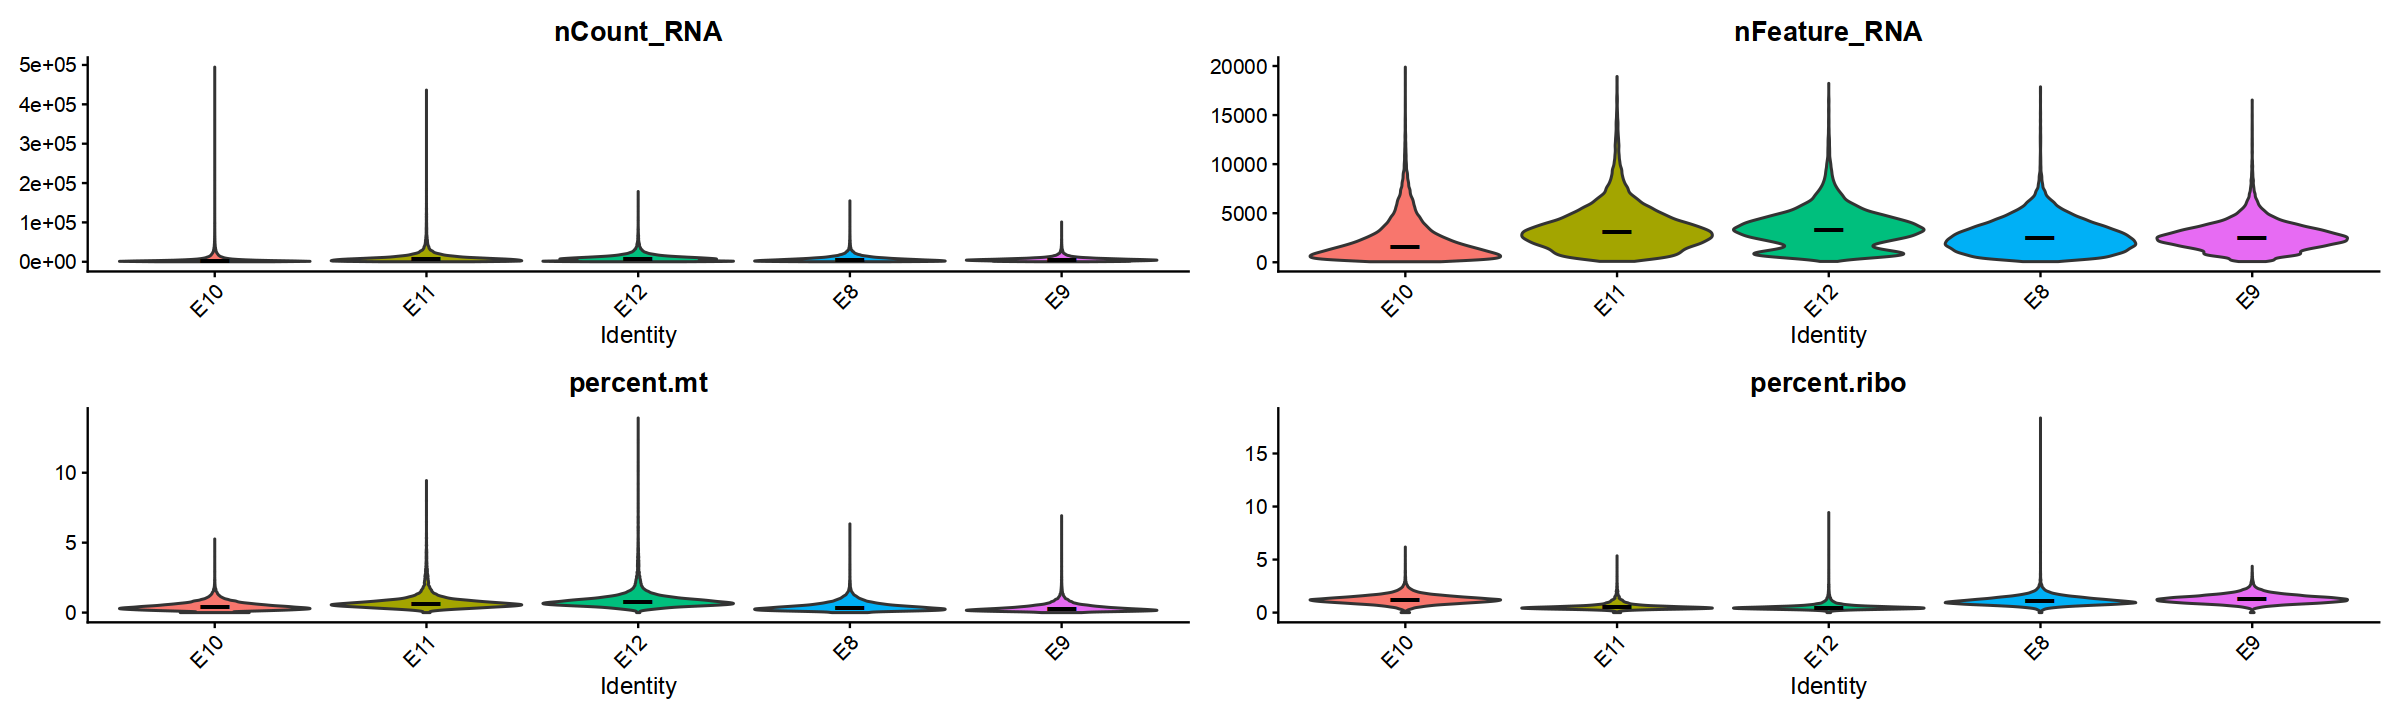

In [20]:
Plot_QC_RNA(embryo_rna, group='orig.ident', width=20, height=6)

Warning message:
"Default search for "data" layer in "RNA" assay yielded no results; utilizing "counts" layer instead."
Warning message:
"Default search for "data" layer in "RNA" assay yielded no results; utilizing "counts" layer instead."
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Warning message:
"Provided value for `pt.size` (0) will be ignored.
When setting plot_boxplot = TRUE, `pt.size` is automatically set to 0."
Warning message:
"Default search for "data" layer in "RNA" assay yielded no results; utilizing "counts" layer instead."
Warning message:
"Default search for "data" layer in "RNA" assay yielded no results; utilizing "counts" layer instead."
Warning message:
"Removed 1 row containing missing values or values outside the scale range (`geom_hline()`)."


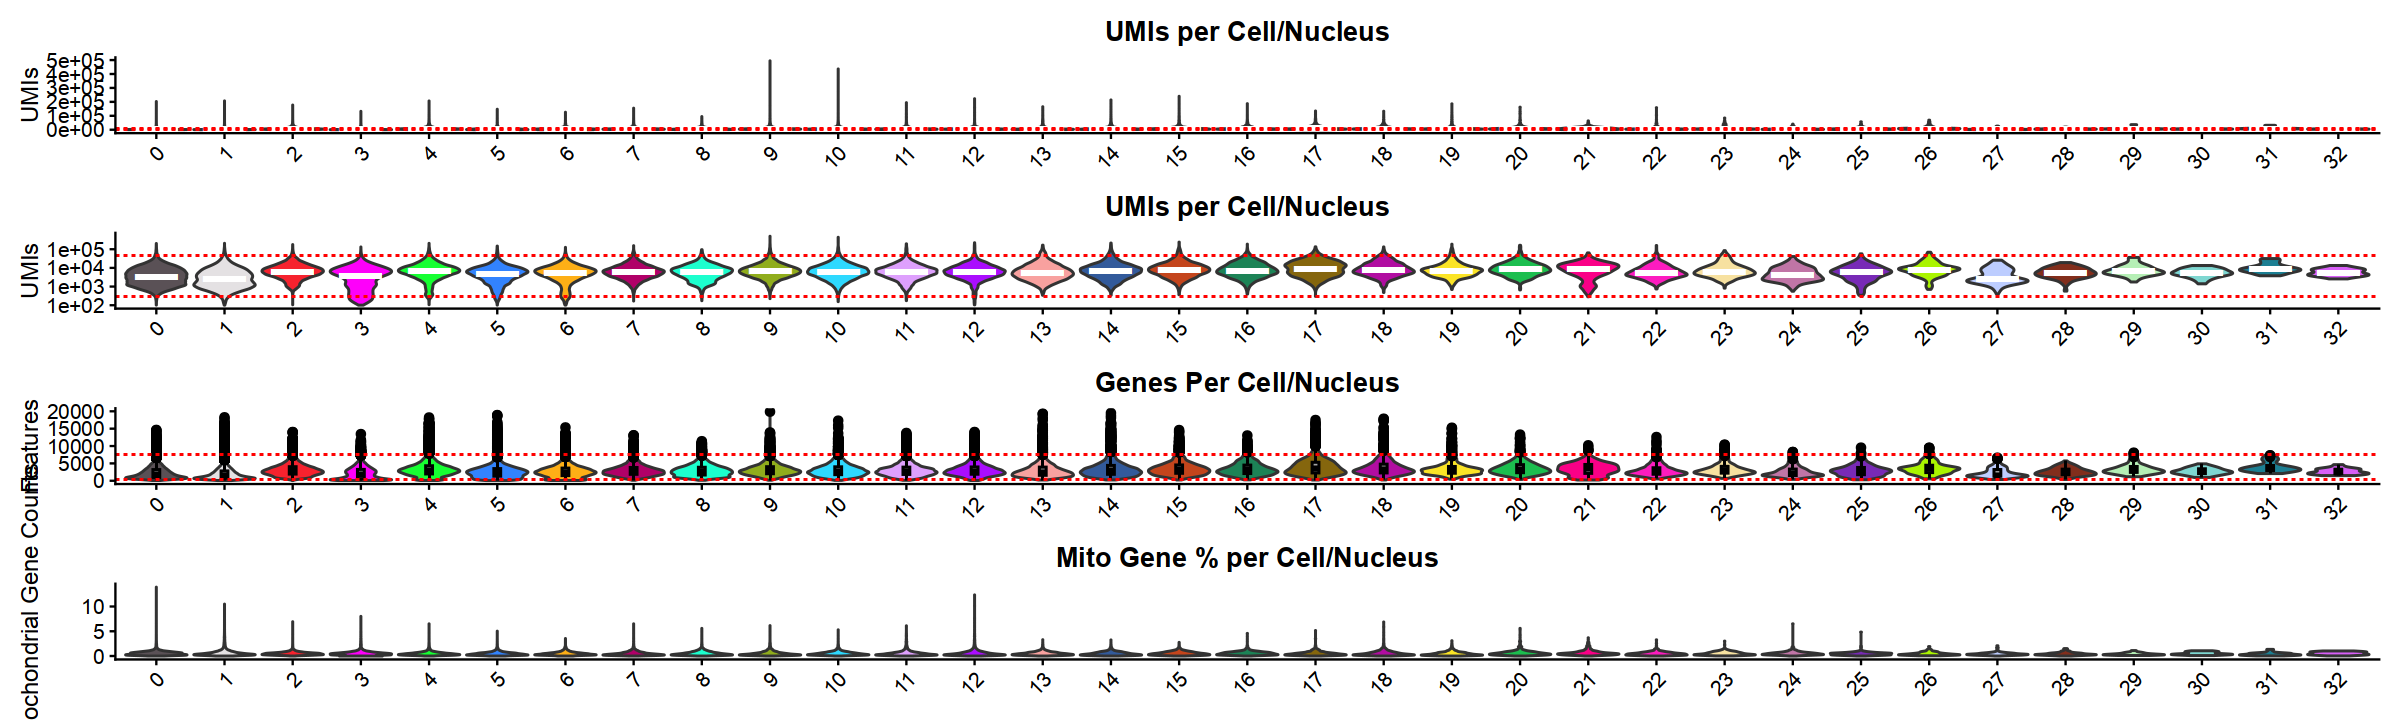

In [26]:
p1 <- QC_Plots_UMIs(seurat_object = embryo_rna, low_cutoff = 300, high_cutoff = 10000, pt.size = 0,plot_median = TRUE)
p2 <- QC_Plots_UMIs(seurat_object = embryo_rna, low_cutoff = 300, high_cutoff = 45000, pt.size = 0,y_axis_log = TRUE, plot_median = TRUE)
p3 <- QC_Plots_Genes(seurat_object = embryo_rna, low_cutoff = 300, high_cutoff = 7500, pt.size = 0,plot_boxplot = TRUE)
p4 <- QC_Plots_Mito(seurat_object = embryo_rna, high_cutoff = 20,pt.size = 0)
p1/p2/p3/p4

In [31]:
color <-c("#D5E0E8", "#C4D4DF", "#A3B5C5", "#F0F1F2", "#E0E3E5","#BDC3C7", "#EBD8C4", "#DEC1A6", "#C6A876", "#E1EBE9","#D3E2E0", "#C3D9D4", "#E5D6C9", "#DCC5B2", "#D4C4B7",
    "#D8D2D7", "#CFC5CC", "#B7AEB9", "#F5EED8", "#F1E6CC","#EFE5C7", "#C9D1C8", "#B7C2B5", "#A5B0A1", "#E2D5C8","#D6C6B0", "#CAB8A3", "#D8E3E4", "#B8CBD0", "#A9C0C2")

In [29]:
# Add stage of mouse embryonic development
embryo_rna@meta.data$stage <- sapply(strsplit(embryo_rna$sample,"_"), "[", 1)
# 调整stage排序
embryo_rna$stage <- factor(embryo_rna$stage,levels=c('E8','E9','E10','E11','E12'))
embryo_rna$log10_nCount_RNA <- log10(embryo_rna$nCount_RNA)
embryo_rna$log10_nFeature_RNA <- log10(embryo_rna$nFeature_RNA)

Warning message:
"Removed 3 rows containing non-finite outside the scale range (`stat_boxplot()`)."
Warning message:
"Removed 35 rows containing non-finite outside the scale range (`stat_boxplot()`)."
Warning message:
"Removed 4 rows containing non-finite outside the scale range (`stat_boxplot()`)."
Warning message:
"Removed 3 rows containing non-finite outside the scale range (`stat_boxplot()`)."
Warning message:
"Removed 35 rows containing non-finite outside the scale range (`stat_boxplot()`)."
Warning message:
"Removed 4 rows containing non-finite outside the scale range (`stat_boxplot()`)."


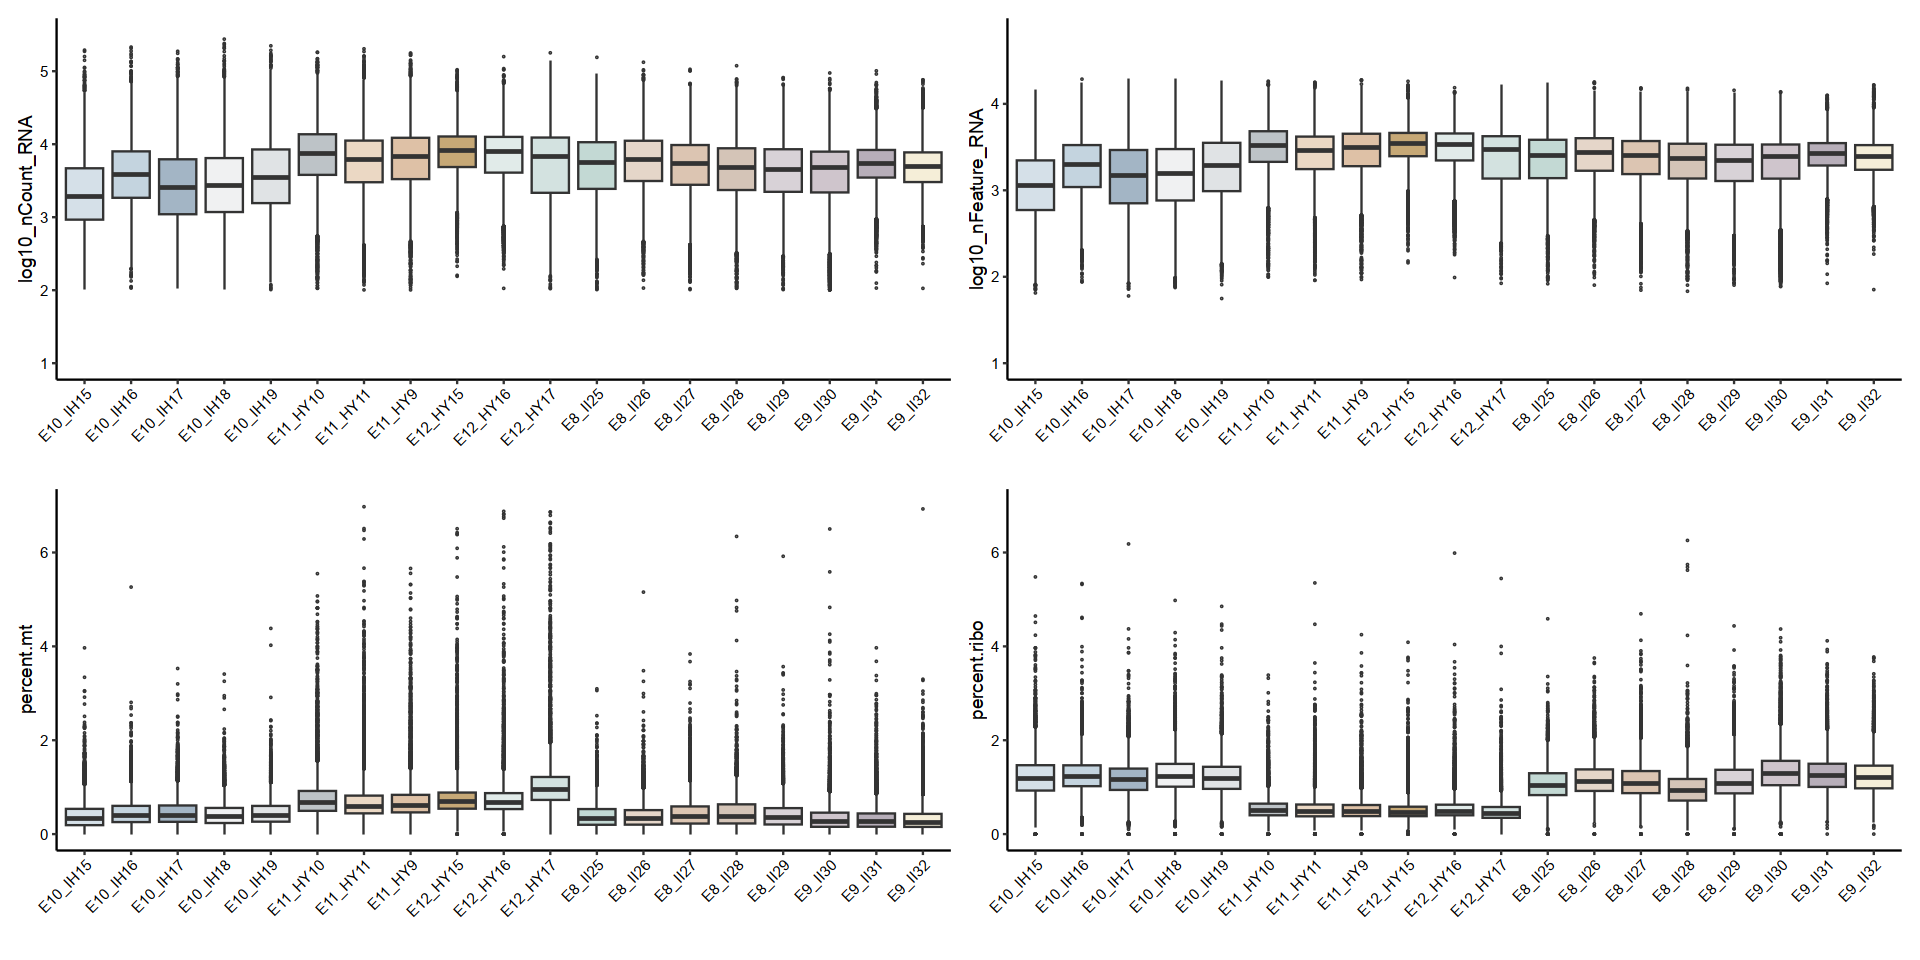

In [48]:
options(repr.plot.width = 16, repr.plot.height = 8)
p1 <- ggplot(embryo_rna@meta.data, aes_string(x = 'sample', y = 'log10_nCount_RNA', fill = 'sample')) +
            geom_boxplot(outlier.shape = 1, outlier.size = 0.01, width = 0.8) +  # 设置异常值点的形状和大小，以及箱线图的宽度
            scale_fill_manual(values = color) + theme(legend.position='none') + xlab('') + ylim(1, 5.5) +
            theme(panel.background = element_rect(fill = "white"), axis.text.x = element_text(angle = 45, hjust = 1),
            axis.line = element_line(colour = "black"), axis.text = element_text(colour = "black"), axis.title = element_text(colour = "black"))
p2 <- ggplot(embryo_rna@meta.data, aes_string(x = 'sample', y = 'log10_nFeature_RNA', fill = 'sample')) +
            geom_boxplot(outlier.shape = 1, outlier.size = 0.01, width = 0.8) +  # 设置异常值点的形状和大小，以及箱线图的宽度
            scale_fill_manual(values = color) + theme(legend.position='none') + xlab('') + ylim(1, 4.8) +
            theme(panel.background = element_rect(fill = "white"), axis.text.x = element_text(angle = 45, hjust = 1),
            axis.line = element_line(colour = "black"), axis.text = element_text(colour = "black"), axis.title = element_text(colour = "black"))
p3 <- ggplot(embryo_rna@meta.data, aes_string(x = 'sample', y = 'percent.mt', fill = 'sample')) + ylim(0, 7) +
            geom_boxplot(outlier.shape = 1, outlier.size = 0.01, width = 0.8) +  # 设置异常值点的形状和大小，以及箱线图的宽度
            scale_fill_manual(values = color) + theme(legend.position='none') + xlab('')  +
            theme(panel.background = element_rect(fill = "white"), axis.text.x = element_text(angle = 45, hjust = 1),
            axis.line = element_line(colour = "black"), axis.text = element_text(colour = "black"), axis.title = element_text(colour = "black"))
p4 <- ggplot(embryo_rna@meta.data, aes_string(x = 'sample', y = 'percent.ribo', fill = 'sample')) +
            geom_boxplot(outlier.shape = 1, outlier.size = 0.01, width = 0.8) +  # 设置异常值点的形状和大小，以及箱线图的宽度
            scale_fill_manual(values = color) + theme(legend.position='none') + xlab('')  + ylim(0, 7) +
            theme(panel.background = element_rect(fill = "white"), axis.text.x = element_text(angle = 45, hjust = 1),
            axis.line = element_line(colour = "black"), axis.text = element_text(colour = "black"), axis.title = element_text(colour = "black"))
(p1|p2)/(p3|p4)
ggsave("embryo/01_processed_data/RNA_QC_plot.pdf",(p1|p2)/(p3|p4),width=16,height=8)

### QC

In [13]:
embryo_rna <- subset(embryo_rna,
  subset = outlier == FALSE &
    doublet_info == 'Singlet' & # scDblFinder.class
    nCount_RNA > 300 &
    nCount_RNA < 100000 &
    nFeature_RNA < 7500)
saveRDS(embryo_rna,'/data/bio_data/data/scCAT_seq/00_scCAT_data/Embryo/processed/embro_RNA_soupx0_filtered2.rds')

In [14]:
embryo_rna

An object of class Seurat 
28425 features across 133813 samples within 1 assay 
Active assay: RNA (28425 features, 2000 variable features)
 3 layers present: scale.data, data, counts

Warning message:
"Default search for "data" layer in "RNA" assay yielded no results; utilizing "counts" layer instead."
Warning message:
"The `slot` argument of `FetchData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>."
Warning message:
"`PackageCheck()` was deprecated in SeuratObject 5.0.0.
ℹ Please use `rlang::check_installed()` instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>."
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since num

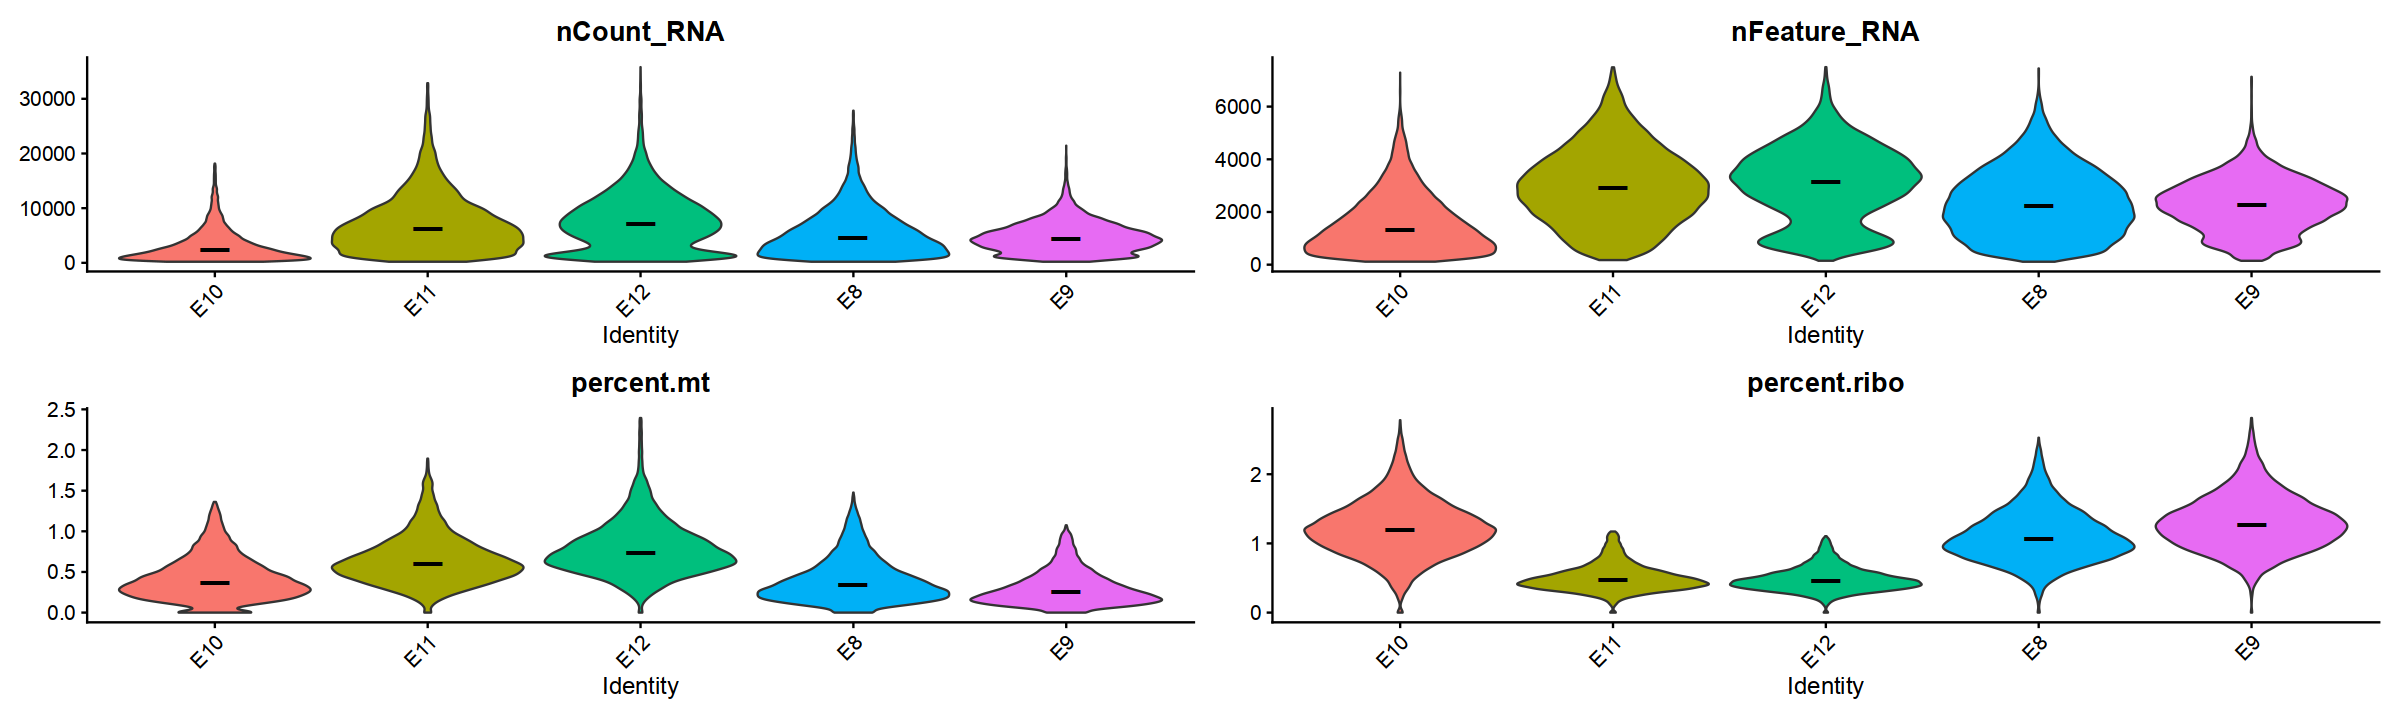

In [55]:
Plot_QC_RNA(embryo_rna, group='orig.ident', width=20, height=6)

### data process

In [12]:
embryo_rna <- readRDS('/data/bio_data/data/scCAT_seq/00_scCAT_data/Embryo/processed/RNA/embro_RNA_soupx_filtered.rds')

In [13]:
embryo_rna

An object of class Seurat 
28425 features across 124245 samples within 1 assay 
Active assay: RNA (28425 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 3 dimensional reductions calculated: pca, harmony, umap

In [15]:
embryo_rna <- Process_RNA(embryo_rna,nfeatures=3000,pc.nums=50, dims=1:50, pca.name = 'pca', umap.name= 'umap.rna', res = 0.5))
var_int <- "sample"
embryo_rna <- RunHarmony(embryo_rna, group.by.vars = var_int, assay.use="RNA", reduction.use = "pca", plot_convergence = FALSE)
red_use <- "harmony"
dims_use <- 1:50
nneigh <- 50
# embryo_rna <- RunUMAP(object = embryo_rna, reduction = red_use, dims = dims_use,n.neighbors = nneigh)
embryo_rna <- RunUMAP(object = embryo_rna, reduction = red_use, dims = dims_use,n.neighbors = nneigh,min.dist=0.2)
embryo_rna <- FindNeighbors(embryo_rna, verbose = T, reduction = red_use, dims = dims_use)
embryo_rna <- FindClusters(embryo_rna, verbose = T, algorithm = 1, resolution = c(0.3,0.5,0.8))

Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
"Different features in new layer data than already exists for scale.data"
PC_ 1 
Positive:  Prtg, Hspd1, Mest, Gja1, Col18a1, Gpc3, Slc2a1, Slc2a3, Apob, Slc16a1 
	   Ctsl, Gm28153, Afp, Fn1, A630012P03Rik, Emb, Tfrc, Ttn, Hapln1, Arl6ip1 
	   Podxl, Rbpms, Igf2, Peg10, Myh6, Hbb-bh1, Lrp2, Dsp, Greb1, Cubn 
Negative:  Map2, Akap6, Ctnna2, Nrxn3, Pcdh9, Nrxn1, Tmem178b, Dcx, Ccser1, Fam155a 
	   Mapk10, Xkr4, Cadm2, Myt1l, Gm26871, Dcc, Nav3, Magi2, Cadps, Thsd7a 
	   Gria2, Unc79, Bcl11a, Enox1, Dclk1, Hecw1, Rbfox1, Scn3a, Nlgn1, Sorbs2 
PC_ 2 
Positive:  Dcc, Mir124-2hg, Miat, Elavl3, Srrm4, Myt1, C130071C03Rik, Dcx, Map2, Srgap3 
	   Mir124a-1hg, Pantr1, Stmn2, Akap6, Ptprn2, Rmst, Nrcam, Elavl4, Unc79, Nfasc 
	   Rims2, Soga3, Srrm4os, Nell2, Apba2, Nova2, Cadps, Fmn2, Tmem178b, Gm26871 
Negative:  Airn, Fbn2, Gpc3, Dlc1, Igf2, Ghr, Fn1, Rbpms, Tpm1, Cald1 
	 

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 133813
Number of edges: 5093375

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9358
Number of communities: 33
Elapsed time: 59 seconds


7 singletons identified. 26 final clusters.



Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



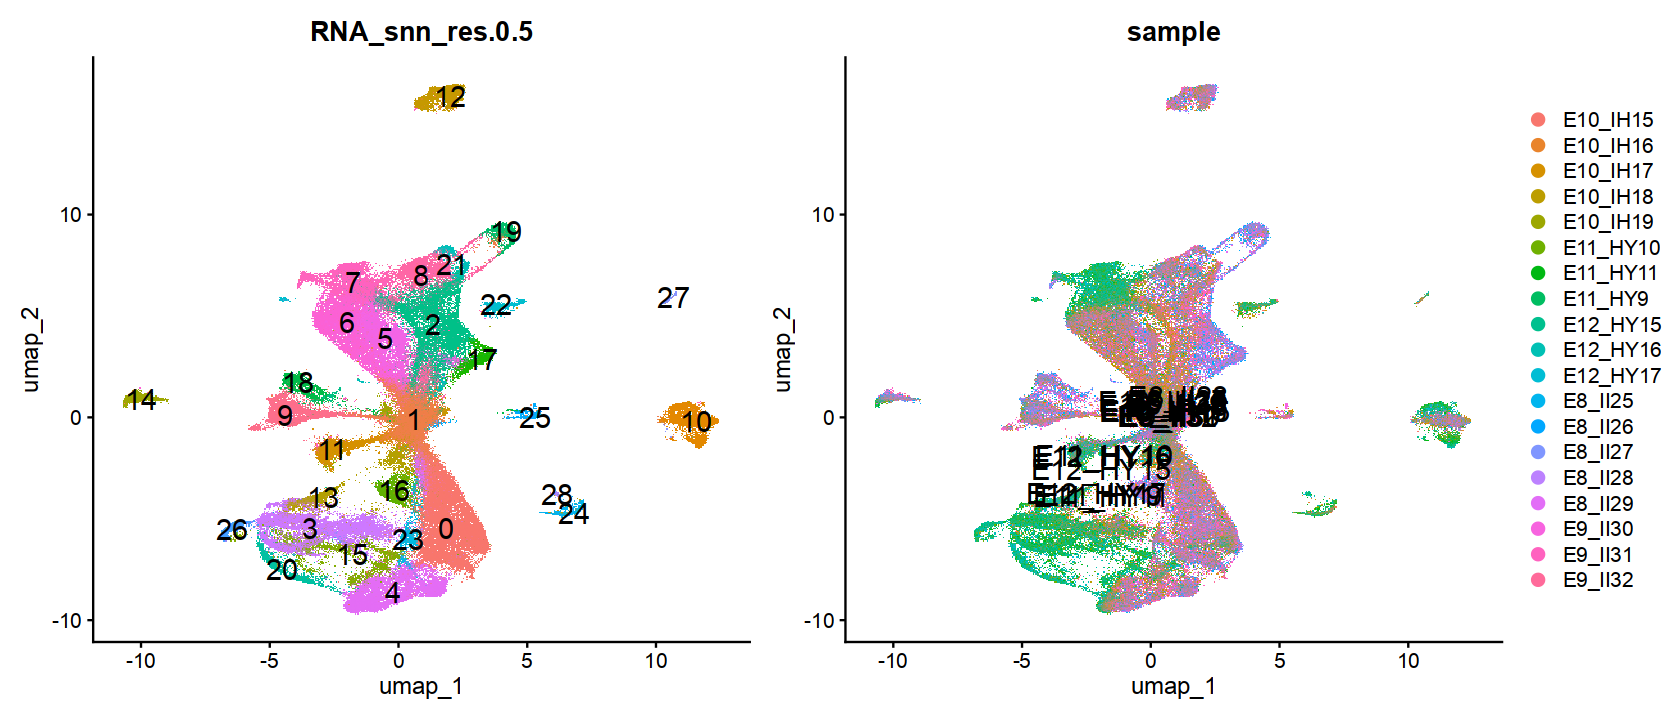

In [14]:
options(repr.plot.width=14, repr.plot.height=6)
p1 <- DimPlot(embryo_rna, label = TRUE, group.by = 'RNA_snn_res.0.5',label.size = 6) + NoLegend()
p2 <- DimPlot(embryo_rna, label = TRUE, group.by = 'sample',label.size = 6) 
p1 | p2

In [18]:
# 1. 提取 metadata 并计算中位数
cluster_qc_medians <- embryo_rna@meta.data %>%
  group_by(RNA_snn_res.0.5) %>% # 或者是你注释后的 "cell_type"
  summarise(
    median_nCount = median(nCount_RNA),
    median_nFeature = median(nFeature_RNA),
    cell_count = n() # 顺便看看每个 cluster 有多少个细胞
  )
cluster_qc_medians

RNA_snn_res.0.5,median_nCount,median_nFeature,cell_count
<fct>,<dbl>,<dbl>,<int>
0,4143.5,2161.0,16374
1,7334.0,3244.0,13899
10,5201.0,2490.0,4105
11,3258.5,1788.5,3868
12,4985.0,2389.0,3787
13,5631.5,2715.5,3110
14,1376.0,1003.0,3057
15,5002.5,3091.5,2728
16,5537.5,2612.5,2358


In [17]:
table(embryo_rna$sample,embryo_rna$RNA_snn_res.0.5)

          
              0    1   10   11   12   13   14   15   16   17   18   19    2
  E10_IH15  848  502   29  174  238  110  196   73   49   41   40   70 1095
  E10_IH16  871  652   42  159  159  115  104   74   42   47   56   73  668
  E10_IH17  878  613   40  199  158  125  155   58   51   41   47   86  752
  E10_IH18  893  674   34  185  218  149  133   65   60   54   59   89  733
  E10_IH19  852  719   47  153  185  146  115   60   70   37   64   74  613
  E11_HY10  207 1015    0  291   39   81  180  348    8    6  199  204  227
  E11_HY11  252 1137    5  369   49   98  266  324   12    2  194  191  360
  E11_HY9   213 1063    0  317   30   87  235  292    9    4  176  157  249
  E12_HY15  195 1392    0  198   39   77  189  219    9   11  244  146  230
  E12_HY16  213 1382    1  223   33   86  348  280   12    6  238  132  486
  E12_HY17  173 1222    1  252   35   62  992  341   10   12  212   99  447
  E8_II25   725  162  356  113  184  186    5   46  195  194    0    0  523
 

In [78]:
deg <- FindAllMarkers(
  object = embryo_rna,group.by='RNA_snn_res.0.5',
  min.pct = 0.1,           # 至少在10%的细胞中表达
  logfc.threshold = 0.25,  # LogFC阈值
  only.pos = FALSE         # 保留上调和下调基因
)
write.table(deg, "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/embryo_soupx0_cluster.csv",quote = FALSE)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 10

Calculating cluster 11

Calculating cluster 12

Calculating cluster 13

Calculating cluster 14

Calculating cluster 15

Calculating cluster 16

Calculating cluster 17

Calculating cluster 18

Calculating cluster 19

Calculating cluster 2

Calculating cluster 20

Calculating cluster 21

Calculating cluster 22

Calculating cluster 23

Calculating cluster 24

Calculating cluster 25

Calculating cluster 26

Calculating cluster 27

Calculating cluster 28

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8

Calculating cluster 9



In [82]:
deg[deg$cluster==1,]

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
Glg1,0,-0.3134794,0.279,0.791,0,1,Glg1
Tnrc6b,0,-0.4143697,0.302,0.799,0,1,Tnrc6b
Pum1,0,-0.3136183,0.310,0.807,0,1,Pum1
Nipbl,0,-0.3113034,0.305,0.799,0,1,Nipbl
Psme4,0,-0.2998816,0.263,0.755,0,1,Psme4
Rbm39,0,-0.3074589,0.302,0.792,0,1,Rbm39
Strn3,0,-0.3783549,0.268,0.758,0,1,Strn3
Ptbp2,0,-0.2914709,0.289,0.777,0,1,Ptbp2
Gpatch8,0,-0.3946269,0.210,0.698,0,1,Gpatch8


In [19]:
embryo_rna_data <- embryo_rna[,!embryo_rna$RNA_snn_res.0.5 == 2]

In [24]:
embryo_rna_data

An object of class Seurat 
28425 features across 121764 samples within 1 assay 
Active assay: RNA (28425 features, 3000 variable features)
 3 layers present: scale.data, data, counts
 3 dimensional reductions calculated: pca, harmony, umap

In [21]:
embryo_rna_data <- Process_RNA(embryo_rna_data,nfeatures=3000,pc.nums=50, dims=1:50, pca.name = 'pca', umap.name= 'umap.rna', res = 0.5)
var_int <- "sample"
embryo_rna_data <- RunHarmony(embryo_rna_data, group.by.vars = var_int, assay.use="RNA", reduction.use = "pca", plot_convergence = FALSE)
red_use <- "harmony"
dims_use <- 1:50
nneigh <- 50
embryo_rna_data <- RunUMAP(object = embryo_rna_data, reduction = red_use, dims = dims_use,n.neighbors = nneigh) # ,min.dist=0.25
embryo_rna_data <- FindNeighbors(embryo_rna_data, verbose = T, reduction = red_use, dims = dims_use)
embryo_rna_data <- FindClusters(embryo_rna_data, verbose = T, algorithm = 1, resolution = c(0.3,0.5,0.8,1.0))
# saveRDS(embryo_rna_data,'scCAT_seq/00_scCAT_data/Embryo/processed/embro_RNA_soupx_doubletfinder_filtered.rds')

Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
"Different features in new layer data than already exists for scale.data"
PC_ 1 
Positive:  Prtg, Hspd1, Mest, Gja1, Gpc3, Col18a1, Slc2a1, Slc16a1, Slc2a3, Ctsl 
	   Gm28153, Apob, Fn1, Afp, A630012P03Rik, Emb, Tfrc, Rbpms, Arl6ip1, Igf2 
	   Podxl, Ttn, Hapln1, Peg10, Greb1, Lrp2, Dsp, Hbb-bh1, Myh6, Lef1 
Negative:  Map2, Akap6, Ctnna2, Nrxn1, Nrxn3, Pcdh9, Tmem178b, Dcx, Ccser1, Fam155a 
	   Mapk10, Myt1l, Xkr4, Cadm2, Gm26871, Nav3, Dcc, Cadps, Magi2, Unc79 
	   Thsd7a, Gria2, Rbfox1, Hecw1, Enox1, Bcl11a, Scn3a, Dclk1, Nlgn1, Sorbs2 
PC_ 2 
Positive:  Airn, Fbn2, Dlc1, Gpc3, Ghr, Cald1, Samd4, Tpm1, Mbnl2, Igf2 
	   Prkg1, Bnc2, Hmcn1, Creb3l2, Peg3, Fndc3b, Col3a1, Rbms3, Lamb1, Colec12 
	   Fn1, Slit3, Rbpms, Arhgap6, Nhsl2, Pdzrn3, Ahnak, Col4a1, Cacna1c, Col1a2 
Negative:  Mir124-2hg, Dcc, Miat, Srrm4, Elavl3, Srgap3, Ptprn2, C130071C03Rik, Nrcam, Pantr1 

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 121764
Number of edges: 4886236

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9550
Number of communities: 19
Elapsed time: 47 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 121764
Number of edges: 4886236

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9417
Number of communities: 27
Elapsed time: 51 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 121764
Number of edges: 4886236

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9273
Number of communities: 32
Elapsed time: 50 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 121764
Number of edges: 4886236

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9201
Number of communities: 38
Elapsed time: 46 seconds


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



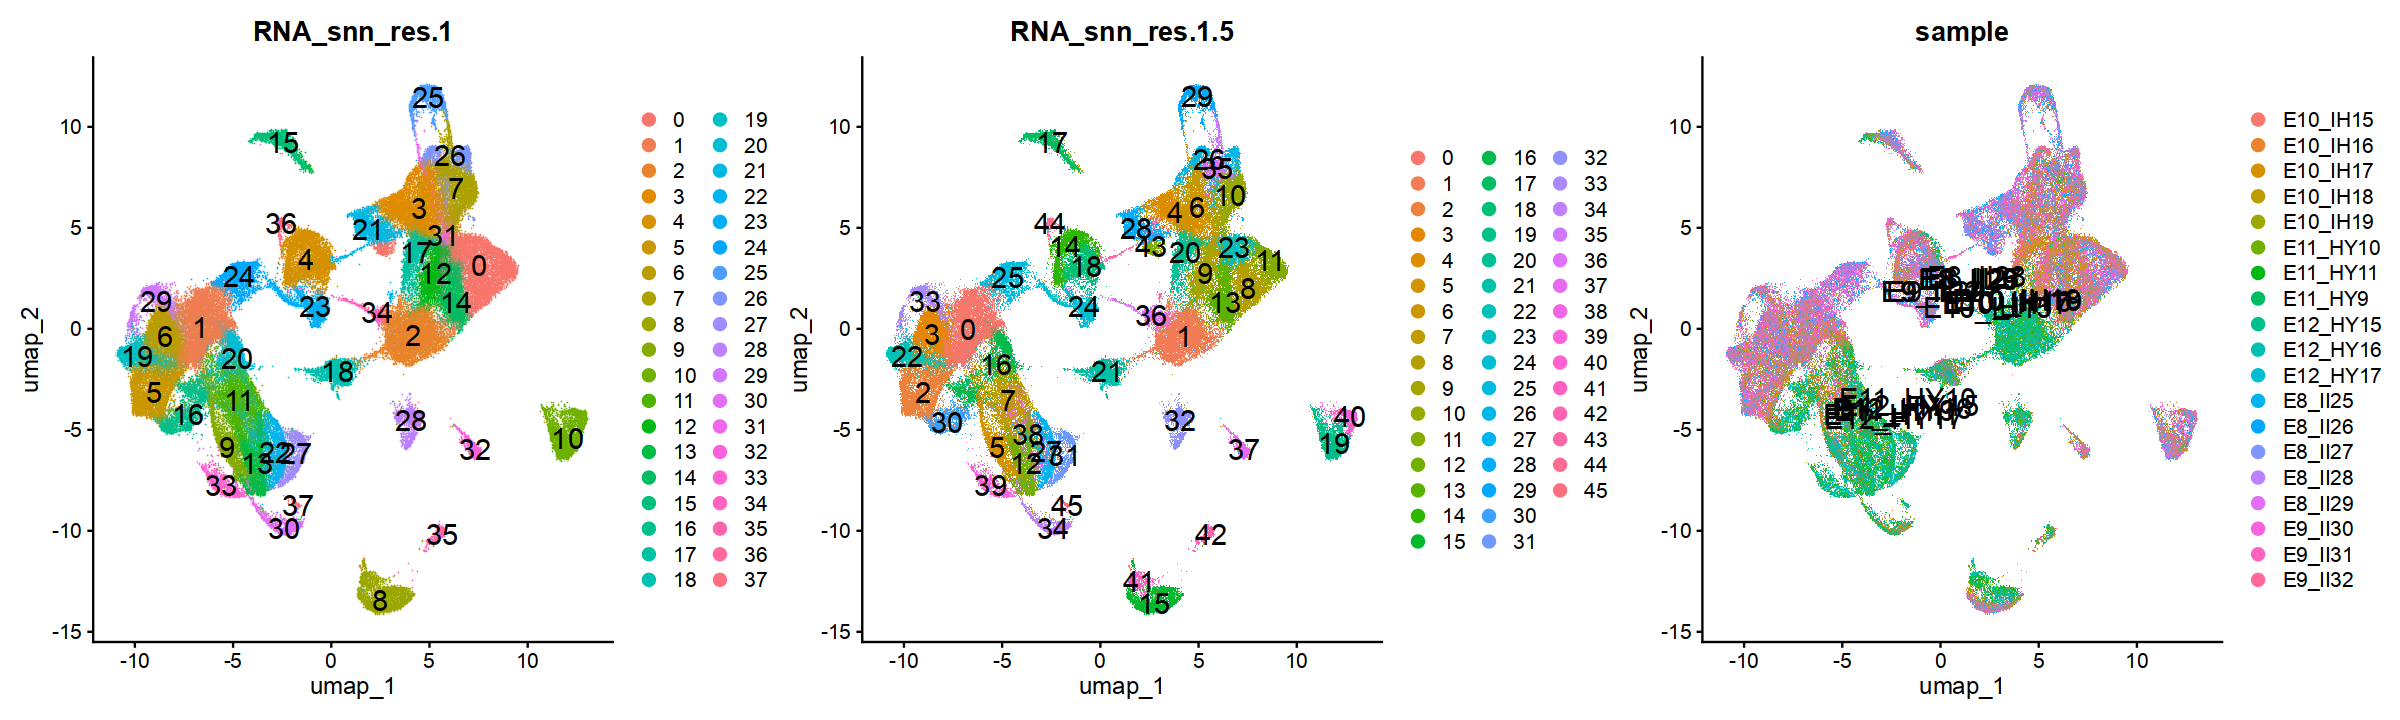

In [6]:
options(repr.plot.width=20, repr.plot.height=6)
p1 <- DimPlot(embryo_rna_data, label = TRUE, group.by = 'RNA_snn_res.1',,pt.size=1.3,label.size = 6) #+ NoLegend()
p2 <- DimPlot(embryo_rna_data, label = TRUE, group.by = 'RNA_snn_res.1.5',label.size = 6) #+ NoLegend()
p3 <- DimPlot(embryo_rna_data, label = TRUE, group.by = 'sample',label.size = 6) #+ NoLegend()
p1|p2|p3

In [5]:
runSoupX_NoDroplets <- function(matrix_path=NULL, expression_matrix=NULL){
  # loading data
  if (!is.null(matrix_path)){
    toc = Seurat::Read10X(matrix_path, gene.column = 1)
  }
  else{toc=expression_matrix}
  #
  scNoDrops = SoupChannel(toc, toc, calcSoupProfile = FALSE)
  # Calculate soup profile
  soupProf = data.frame(row.names = rownames(toc), est = rowSums(toc)/sum(toc), counts = rowSums(toc))
  scNoDrops = setSoupProfile(scNoDrops, soupProf)
  # get clusters info
  obj <- CreateSeuratObject(counts = toc)
  obj <- Process_RNA(obj)
  soupx_groups = Idents(obj)
  # Set cluster information in SoupChannel
  scNoDrops = setClusters(scNoDrops, soupx_groups)
  # Estimate contamination fraction
  scNoDrops  = autoEstCont(scNoDrops, doPlot=FALSE)
  # Infer corrected table of counts and rount to integer
  out = adjustCounts(scNoDrops, roundToInt = TRUE)
  return (out)
}
# export 10X format matrix of single-cell data
ExportData_10X_format <- function(data=NULL, out_dir=NULL, assay='RNA', if_compress=TRUE){
  #
  if (is.null(data)){stop('please supply the data')}
  #
  if(assay=='ATAC'){
    if (!dir.exists(out_dir)) {dir.create(out_dir)}
    writeLines(colnames(data), paste0(out_dir,'/barcodes.tsv'))
    writeLines(rownames(data), paste0(out_dir,'/peaks.bed'))
    Matrix::writeMM(data, file=paste0(out_dir,'/matrix.mtx'))
    if (if_compress){
        R.utils::gzip(paste0(out_dir,'/barcodes.tsv'))
        R.utils::gzip(paste0(out_dir,'/peaks.bed'))
        R.utils::gzip(paste0(out_dir,'/matrix.mtx'))
    }
  }
  #
  if(assay=='RNA'){
    if (!dir.exists(out_dir)) {dir.create(out_dir)}
    writeLines(colnames(data), paste0(out_dir,'/barcodes.tsv'))
    writeLines(rownames(data), paste0(out_dir,'/features.tsv'))
    Matrix::writeMM(data, file=paste0(out_dir,'/matrix.mtx'))
    if (if_compress){
        R.utils::gzip(paste0(out_dir,'/barcodes.tsv'))
        R.utils::gzip(paste0(out_dir,'/features.tsv'))
        R.utils::gzip(paste0(out_dir,'/matrix.mtx'))
    }
  }
  #
  print('Success to output data')
}

In [6]:
# RNA matrix
data_path='scCAT_seq/00_scCAT_data/Embryo/'
sample_names=c('E8_II25_web_0', 'E8_II26_web_0', 'E8_II27_web_0', 'E8_II28_web_0', 'E8_II29_web_0', 'E9_II30_web_0', 'E9_II31_web_0', 'E9_II32_web_0', 'E10_IH15_web_0','E10_IH16_web_0','E10_IH17_web_0','E10_IH18_web_0','E10_IH19_web_0','E11_HY9_web_0','E11_HY10_web_0','E11_HY11_web_0','E12_HY15_web_0','E12_HY16_web_0','E12_HY17_web_0')
names=c('E8_II25', 'E8_II26', 'E8_II27', 'E8_II28', 'E8_II29', 'E9_II30', 'E9_II31', 'E9_II32', 'E10_IH15','E10_IH16','E10_IH17','E10_IH18','E10_IH19','E11_HY9','E11_HY10','E11_HY11','E12_HY15','E12_HY16','E12_HY17')
#
counts_files=c()
for (i in 1:length(sample_names)){
    counts_files=c(counts_files, paste0(data_path, sample_names[i],'/RNA/FilterMatrix/'))
}
for (i in counts_files){print (i); print (dir.exists(i))}

[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II25_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II26_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II27_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II28_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II29_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E9_II30_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E9_II31_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E9_II32_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH15_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH16_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH17_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH18_web_0/RNA/FilterMatrix/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH19_web_0/RNA/Filte

In [24]:
output_path='scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/'
# add matrix path
matrix_paths <- c()
out_paths <- c()
# output data
for (i in 1:length(counts_files)){
    out <- runSoupX_NoDroplets(matrix_path=counts_files[i])
    #if(!dir.exists(output_paths[i])){dir.create(output_paths[i])}
    out_paths[i]=c(paste0(output_path, names[i]))
    ExportData_10X_format(out,out_dir=out_paths[i], assay='RNA')
}

Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

PC_ 1 
Positive:  Ryr2, Ctnna3, Slc8a1, Cacnb2, Erbb4, Pakap, Ccdc141, Cacna1c, Gm13938, Nebl 
	   Obscn, Cacna1d, Gm10801, Ank3, Ttn, Lpp, Mybpc3, Myo18b, Myocd, Gm10800 
	   Myom1, Arhgap6, Filip1, Slco3a1, Myh6, Trim55, Palld, Esrrg, Sphkap, Sorbs2 
Negative:  Mir142hg, Gypa, Ermap, Gm26771, Rhag, Kel, Slc4a1, Acp5, Ptn, Hoxb5os 
	   Gm14226, Gm45889, Hoxc4, Hbb-bh2, Slc30a10, Hbb-y, Slc25a37, Hoxaas3, Snca, Spta1 
	   Mmp10, Etos1, Gm35883, Fam170a, Gm47128, Selenok-ps1, B930036N10Rik, Gm33091, Prr19, Gm17193 
PC_ 2 
Positive:  Gm13938, Myh6, Ttn, Nexn, Mybpc3, Ankrd1, Trim55, Tnnt2, Ryr2, Myocd 
	   Slc8a1, Ccdc141, Acta2, Actc1, Myom1, 5430431A17Rik, Popdc2, Myh7, Ldb3, Xirp1 
	   Myl4, Tbx20, Sphkap, Mylk3, 4930512H18Rik, Arhgap6, Gm31251, Erbb4, Nebl, Actn2 
Negative:  Adgrv1, Lsamp, Ptprn2, Sox2ot, Dcc, Gm10801, Adgrb3, Fgf14, Csmd1, Rfx4 
	   Lrp1b, Ptn, Gm10800, Nrg3, As

[1] "Success to output data"


Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

PC_ 1 
Positive:  Ryr2, Slc8a1, Erbb4, Ttn, Gm13938, Ccdc141, 5430431A17Rik, Mybpc3, Tnnt2, Myom1 
	   Pakap, Nexn, Myocd, Arhgap6, Ctnna3, Ankrd1, Nebl, Myh6, Cacna1d, Myh7 
	   Myl4, Trim55, Ldb3, Cacna1c, Sphkap, Acta2, Actc1, Filip1, Actn2, 4930512H18Rik 
Negative:  Ptn, Gm26771, Mir142hg, Slc4a1, Gypa, Snca, Hoxb5os, Kel, Ermap, Rhag 
	   Hoxc4, Hoxaas3, Spta1, Acp5, Fgf15, Dll1, Ptprz1, Nrcam, Slc25a37, Csf2rb 
	   Frrs1, Pax3, Hba-x, Hbb-bh1, Sfrp1, Abcb10, Gm14226, Gm45889, Pcdh19, Hoxc5 
PC_ 2 
Positive:  Gm10801, Gm10800, Dpp10, Ptprn2, Cntnap2, Csmd1, Lsamp, Dlg2, Chl1, Anks1b 
	   Dab1, Pcdh15, Fstl5, Mgat4c, Asic2, Alk, Csmd2, Ptprt, Gabrg3, Skint5 
	   Malrd1, Magi2, Grm7, Cntnap5c, Grm1, Arhgap15, Cntn5, Cntn4, Cntnap5a, Lingo2 
Negative:  Ttn, Nexn, Tnnt2, Mybpc3, Acta2, Ccdc141, Ankrd1, Trim55, Xirp1, Gm31251 
	   Myh6, Actc1, Myl4, Slc8a1, Popdc2, 5430431A17Rik, M

[1] "Success to output data"


Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

PC_ 1 
Positive:  Ryr2, Myom1, Ccdc141, Tnnt2, Slc8a1, Gm13938, Nexn, Erbb4, Trim55, Myocd 
	   Ttn, Pakap, Ctnna3, Ldb3, Mybpc3, 5430431A17Rik, Acta2, Arhgap6, Myh6, Nebl 
	   Actc1, Myo18b, Sphkap, Tbx20, Myh7, Ankrd1, Cacna1d, Popdc2, Myl4, Jph2 
Negative:  Ptn, Gm26771, Slc4a1, Mir142hg, Gypa, Spta1, Hoxb5os, Ermap, Hoxd3, Kel 
	   Rhag, Snca, Slc30a10, Dll1, Hoxc4, Acp5, Hoxaas3, Nrcam, Hoxa9, Ptprz1 
	   Hbb-y, Sfrp1, Pax6, Hbb-bh1, Gm14226, Epha5, 5430401H09Rik, Hba-x, Pax3, Slc25a37 
PC_ 2 
Positive:  Ttn, Tnnt2, Nexn, Myh6, Mybpc3, Ankrd1, Trim55, Acta2, Popdc2, Ldb3 
	   Tnnc1, Actc1, Myh7, Sh3bgr, Myom1, Myl4, Ccdc141, Xirp1, Myl7, Gm31251 
	   Myocd, 5430431A17Rik, Slc8a1, Tbx20, Tagln, Gm13938, Sphkap, Rbm24, Actn2, Ryr2 
Negative:  Gm10801, Gm10800, Csmd1, Abca13, Dlg2, Dab1, Chl1, Lrp1b, Cntnap2, Pcdh15 
	   Lingo2, Dpp10, Dlgap2, Adgrl3, Cntn5, Kcnma1, Alk, Anks1b, 

...

[1] "Success to output data"


Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

PC_ 1 
Positive:  Erc2, Rbfox1, Dlg2, Tnik, Kcnma1, Dpp6, Grid1, Sema6d, Nrg3, Dscam 
	   Dlgap1, Anks1b, Sptbn1, Nav3, Nrxn1, Fam155a, Kcnb2, Cacna1e, Asic2, Atp8a2 
	   Lsamp, Csmd2, Myt1l, Fry, Cntnap2, Cacna1c, Prkce, Dlgap2, Pde4d, Lingo2 
Negative:  Slc4a1, Kel, Hba-a1, Hba-a2, Spta1, Epb42, Ermap, Acp5, Xk, Pkhd1l1 
	   Hbb-bt, Car2, Hba-x, Rhag, Hbb-bh1, Blvrb, Tent5c, Slc25a37, Zc3hav1, Tmcc2 
	   Fech, 5430401H09Rik, Nudt4, Slc39a8, Slc22a4, Gypa, Snca, Hbb-bs, Hbb-y, Mir142hg 
PC_ 2 
Positive:  Airn, Gpc3, Dlc1, Col3a1, Cald1, Pdzrn3, Fn1, Ddr2, Hmcn1, Ghr 
	   Col1a2, Tpm1, Ror1, Hmga2, Col4a2, Col5a2, Samd4, Gulp1, Col4a1, Lama4 
	   Arhgap28, Wwtr1, Dab2, Cped1, Bnc2, Ltbp1, Lamb1, Igf2, Dnm3os, Slit3 
Negative:  Akap6, Cadps, Scn3a, Myt1l, Dcc, Xkr4, Nrxn1, Tmem178b, Stmn2, Gpm6a 
	   Gria2, Fam155a, Mapk10, Gabrb3, Grik2, Gm26871, Rmst, Syt1, Nrxn3, Hecw1 
	   Snhg1

[1] "Success to output data"


Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

PC_ 1 
Positive:  Kcnma1, Dlg2, Ctnna3, Atp8a2, Dpp6, Tnik, Macrod2, Chl1, Agbl1, Erc2 
	   Cntnap2, Anks1b, Sema6d, Ptprt, Grid1, Lingo2, Sdk1, Dysf, Csmd2, Nrxn1 
	   Dlgap1, Dscam, Gm10801, Csmd1, Prkn, Cacna1a, Fry, Dlgap2, Nrg3, Cdh13 
Negative:  Kel, Slc4a1, Hba-a1, Hba-a2, Spta1, Epb42, Ermap, Car2, Pkhd1l1, Tent5c 
	   Slc25a37, Hba-x, Hbb-bh1, Rhag, Acp5, Hbb-bt, Nudt4, Blvrb, Hbb-y, Tmcc2 
	   5430401H09Rik, Snca, Gypa, Hbb-bs, Slc22a4, Hemgn, Neat1, Fth1, Mir142hg, Slc16a10 
PC_ 2 
Positive:  Airn, Col3a1, Fn1, Dlc1, Hmcn1, Col1a2, Col4a1, Ror1, Tpm1, Ghr 
	   Samd4, Igf2, Hmga2, Col4a2, Lama4, Col5a2, Arhgap28, Dab2, Ltbp1, Cped1 
	   Bnc2, Colec12, Sparc, Col1a1, Lama2, Prrx1, Egfr, Col12a1, Palld, Col26a1 
Negative:  Cadps, Myt1l, Xkr4, Scn3a, Dcc, Fam155a, Nrxn1, Tmem178b, Grik2, Gria2 
	   Gabrb3, Gm26871, Hecw1, Stmn2, Nrxn3, Syt1, Rmst, Ppfia2, Ccser1, Elavl2 
	  

[1] "Success to output data"


In [7]:
# soupx1 matrix
counts_files_soupx=c()
for (i in 1:length(sample_names)){
    counts_files_soupx=c(counts_files_soupx, paste0('scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/', names[i]))
}
for (i in counts_files_soupx){print (i); print (dir.exists(i))}

[1] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E8_II25"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E8_II26"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E8_II27"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E8_II28"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E8_II29"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E9_II30"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E9_II31"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E9_II32"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E10_IH15"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E10_IH16"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E10_IH17"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E10_IH18"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E10_IH19"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embr

In [8]:
counts_files_soupx

[1] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E8_II25" 
 [2] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E8_II26" 
 [3] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E8_II27" 
 [4] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E8_II28" 
 [5] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E8_II29" 
 [6] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E9_II30" 
 [7] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E9_II31" 
 [8] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E9_II32" 
 [9] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E10_IH15"
[10] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E10_IH16"
[11] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E10_IH17"
[12] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E10_IH18"
[13] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E10_IH19"
[14] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E11_HY9" 
[15] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E11_HY10"
[16] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E11_HY11"
[17] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E12_HY15"
[18] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E12_HY16"
[19] "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/soupX/E12_HY17"

In [9]:
# 批量读入
seurat.list <- c()
for (i in 1:length(counts_files_soupx)){
    seurat.obj=Create_scRNA_object(data.dir=counts_files_soupx[i])
    meta=seurat.obj@meta.data[, c('nCount_RNA', 'nFeature_RNA')]
    colnames(meta)=c('nCounts', 'nFeatures')
    seurat.list[[i]] <- seurat.obj
    }
# saveRDS(seurat.list,'/data/bio_data/zhangzhongjin/data/scCAT_seq/00_scCAT_data/Embryo/processed/embro_RNA_seulist.rds')

In [10]:
# get overlap genes
genes=Overlap_Seurat_Genes(seurat.list)
length(genes)
# extract genes of each seurat object
seurat.list <- lapply(X = seurat.list, FUN = function(x) {x <- x[genes, ]})

[1] 28425

In [11]:
# add qc meta
seurat.list <- lapply(X = seurat.list, FUN = function(x) {
    # 1. 执行质控计算
    x <- QC_RNA(proj = x, genome = "mm10")
    x <- Add_Mito_Ribo(x, species = "mouse")
    x <- Add_Cell_Complexity(x)
    return(x) 
})

Warning message in PercentageFeatureSet(proj, pattern = "^mt-", features = features):
"Both `features` and `pattern` were provided; `pattern` will be ignored."
Adding Percent Mitochondrial genes for mouse using gene symbol pattern: "^mt-".
Adding Percent Ribosomal genes for mouse using gene symbol pattern: "^Rp[sl]".
Adding Percent Mito+Ribo by adding Mito & Ribo percentages.
Warning message in PercentageFeatureSet(proj, pattern = "^mt-", features = features):
"Both `features` and `pattern` were provided; `pattern` will be ignored."
Adding Percent Mitochondrial genes for mouse using gene symbol pattern: "^mt-".
Adding Percent Ribosomal genes for mouse using gene symbol pattern: "^Rp[sl]".
Adding Percent Mito+Ribo by adding Mito & Ribo percentages.
Warning message in PercentageFeatureSet(proj, pattern = "^mt-", features = features):
"Both `features` and `pattern` were provided; `pattern` will be ignored."
Adding Percent Mitochondrial genes for mouse using gene symbol pattern: "^mt-".
Ad

In [12]:
# outliers and doublets
for (i in 1:length(seurat.list)){
    # outliers
    seurat.list[[i]] <- subset(seurat.list[[i]], subset = nCount_RNA > 100)
    outlier <- is_outlier(seurat.list[[i]], "nCount_RNA", 4) | 
                is_outlier(seurat.list[[i]], "nFeature_RNA", 4) | 
                is_outlier(seurat.list[[i]], "percent.mt", 4) |
                is_outlier(seurat.list[[i]], "percent.ribo", 4)
    seurat.list[[i]]$outlier <- outlier
    # doublets
    seurat.list[[i]] <- runscDblFinder(seurat.list[[i]], assay='RNA')
}

Warning message:
"The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead."
Warning message in .checkSCE(sce):
"Some cells in `sce` have an extremely low read counts; note that these could trigger errors and might best be filtered out"
Aggregating features...

Clustering cells...

Warning message in (function (A, nv = 5, nu = nv, maxit = 1000, work = nv + 7, reorth = TRUE, :
"You're computing too large a percentage of total singular values, use a standard svd instead."
10 clusters

Creating ~4184 artificial doublets...

Dimensional reduction

Evaluating kNN...

Training model...

iter=0, 433 cells excluded from training.

iter=1, 446 cells excluded from training.

iter=2, 446 cells excluded from training.

Threshold found:0.686

461 (8.8%) doublets called

Warning message in .checkSCE(sce):
"Some cells in `sce` have an extremely low read counts; note that these could trigger errors and might best be filtered out"
Aggrega

In [13]:
# merge seulist
seurat.obj <- merge(x = seurat.list[[1]], y = seurat.list[c(1:length(seurat.list))[-1]])
saveRDS(seurat.obj,'/data/bio_data/zhangzhongjin/data/scCAT_seq/00_scCAT_data/Embryo/processed/RNA/embro_RNA_soupx1_seuobj.rds')

In [26]:
seurat.obj

An object of class Seurat 
28425 features across 156051 samples within 1 assay 
Active assay: RNA (28425 features, 0 variable features)
 19 layers present: counts.1, counts.2, counts.3, counts.4, counts.5, counts.6, counts.7, counts.8, counts.9, counts.10, counts.11, counts.12, counts.13, counts.14, counts.15, counts.16, counts.17, counts.18, counts.19

In [27]:
embryo_rna <- JoinLayers(seurat.obj)

In [28]:
blacklist.genes=GetBlackListGenes(embryo_rna, MT=TRUE, Ribo=TRUE, Cellcycle=FALSE, Sex=FALSE)

  2135 genes were dropped because they have exons located on both strands
  of the same reference sequence or on more than one reference sequence,
  so cannot be represented by a single genomic range.
  Use 'single.strand.genes.only=FALSE' to get all the genes in a
  GRangesList object, or use suppressMessages() to suppress this message.

'select()' returned 1:1 mapping between keys and columns



In [29]:
embryo_rna$sample <- sub("^([^_]+_[^_]+)_.*", "\\1", colnames(embryo_rna))
embryo_rna$Sample <- embryo_rna$orig.ident

In [31]:
embryo_rna

An object of class Seurat 
28425 features across 156051 samples within 1 assay 
Active assay: RNA (28425 features, 0 variable features)
 1 layer present: counts

Warning message:
"Default search for "data" layer in "RNA" assay yielded no results; utilizing "counts" layer instead."
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



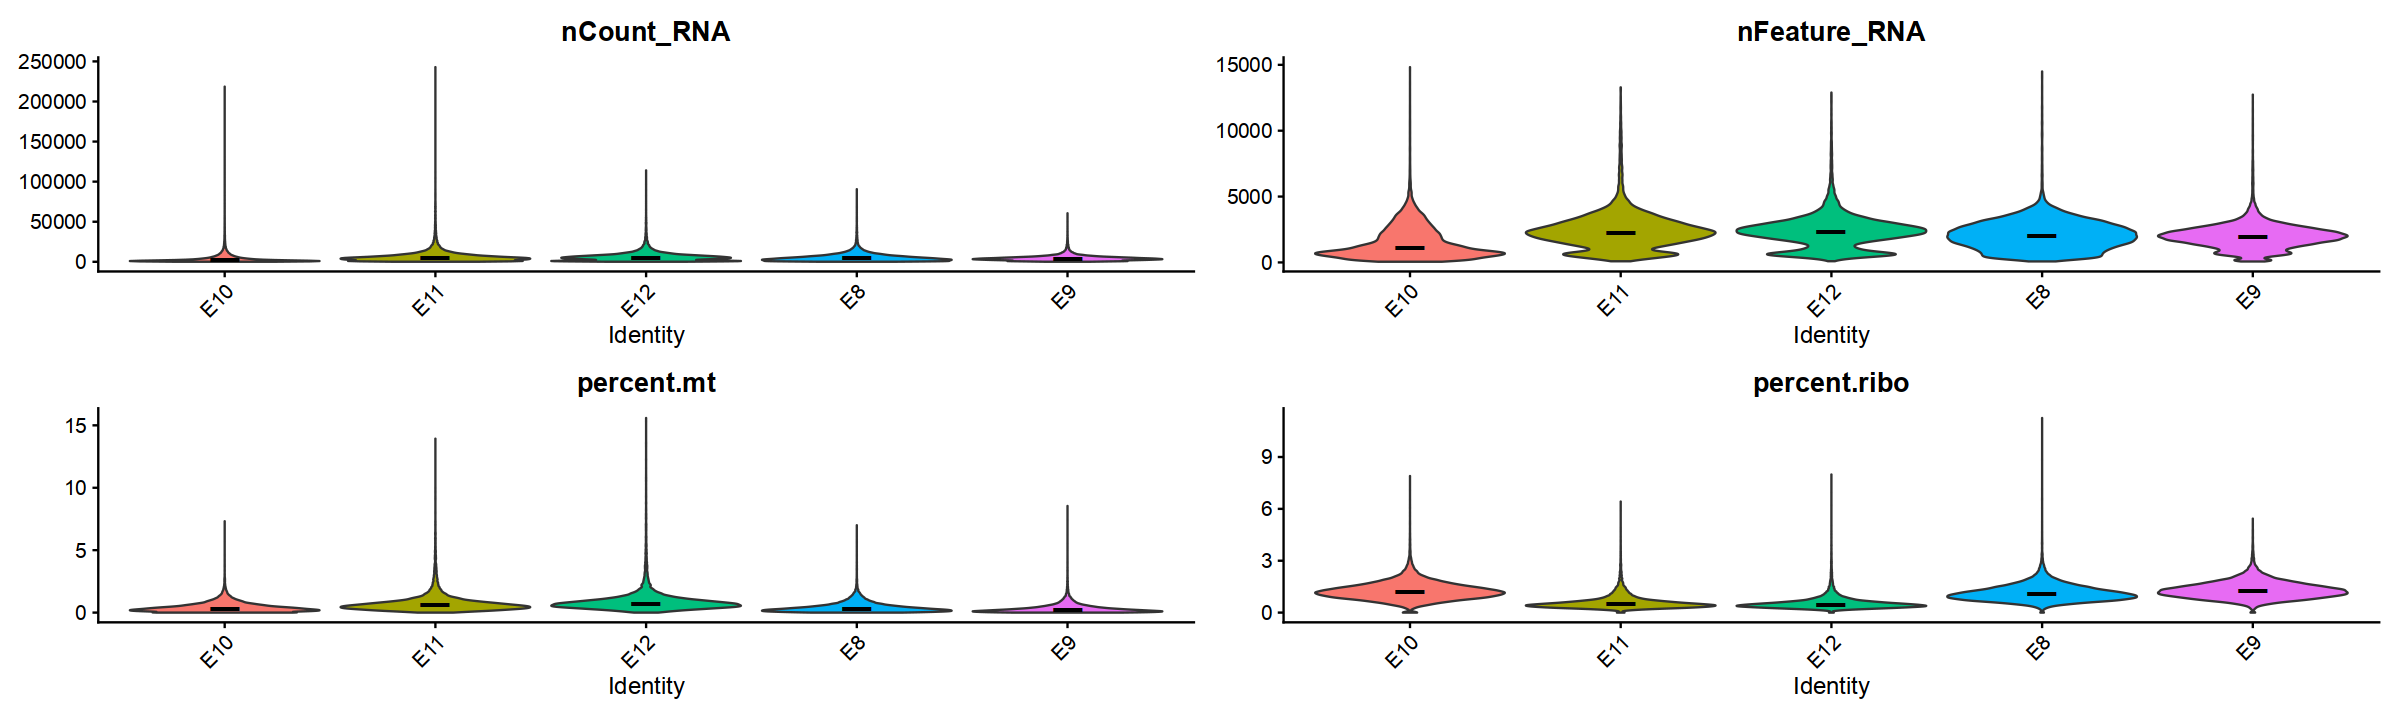

In [33]:
Plot_QC_RNA(seurat.obj, group='orig.ident', width=20, height=6)

In [35]:
embryo_rna <- subset(embryo_rna,
  subset = outlier == FALSE &
    scDblFinder.class == 'singlet' &
    nCount_RNA > 300 &
    nCount_RNA < 100000 &
    nFeature_RNA < 7500)

In [37]:
embryo_rna <- Process_RNA(embryo_rna,nfeatures=3000,pc.nums=50, dims=1:50, pca.name = 'pca', umap.name= 'umap.rna', res = c(0.3,0.5,0.8))
var_int <- "sample"
embryo_rna <- RunHarmony(embryo_rna, group.by.vars = var_int, assay.use="RNA", reduction.use = "pca", plot_convergence = FALSE)
red_use <- "harmony"
dims_use <- 1:50
nneigh <- 50
# embryo_rna <- RunUMAP(object = embryo_rna, reduction = red_use, dims = dims_use,n.neighbors = nneigh)
embryo_rna <- RunUMAP(object = embryo_rna, reduction = red_use, dims = dims_use,n.neighbors = nneigh,min.dist=0.2)
embryo_rna <- FindNeighbors(embryo_rna, verbose = T, reduction = red_use, dims = dims_use)
embryo_rna <- FindClusters(embryo_rna, verbose = T, algorithm = 1, resolution = 0.5)

Transposing data matrix

Initializing state using k-means centroids initialization

Warning message:
"Quick-TRANSfer stage steps exceeded maximum (= 6143700)"
Harmony 1/10

Harmony 2/10

Harmony 3/10

Harmony 4/10

Harmony 5/10

Harmony converged after 5 iterations

Warning message:
"The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session"
10:33:29 UMAP embedding parameters a = 0.9922 b = 1.112

10:33:29 Read 122874 rows and found 50 numeric columns

10:33:29 Using Annoy for neighbor search, n_neighbors = 50

10:33:29 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 122874
Number of edges: 4712013

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9414
Number of communities: 38
Elapsed time: 49 seconds


10 singletons identified. 28 final clusters.



In [42]:
embryo_rna

An object of class Seurat 
28425 features across 122874 samples within 1 assay 
Active assay: RNA (28425 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 3 dimensional reductions calculated: pca, harmony, umap

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



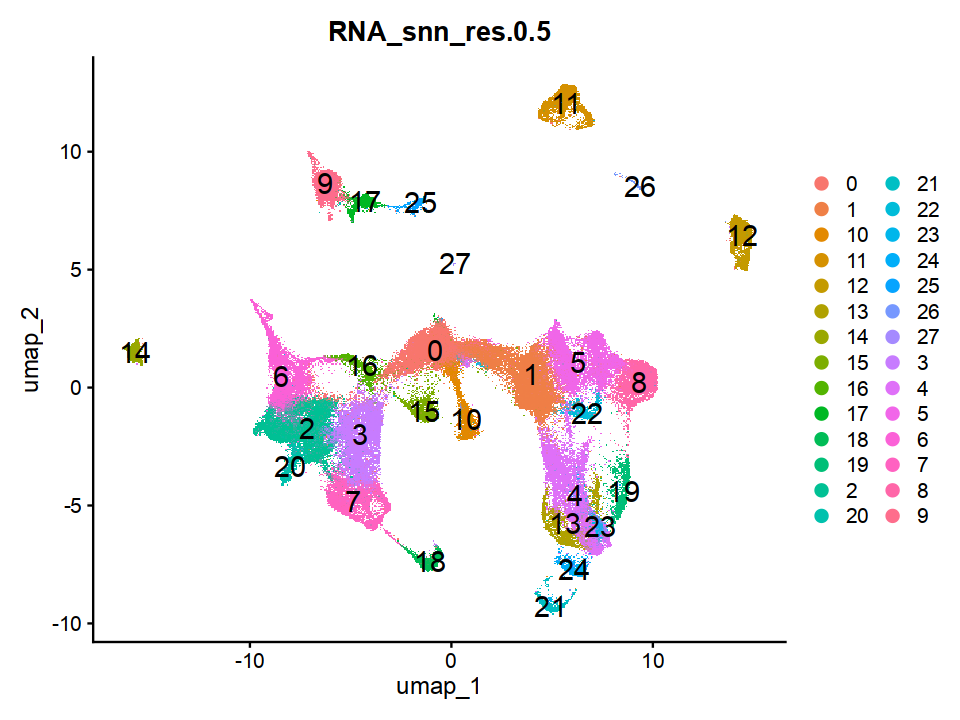

In [51]:
options(repr.plot.width=8, repr.plot.height=6)
DimPlot(embryo_rna, label = TRUE, group.by = 'RNA_snn_res.0.5',label.size = 6) #+ NoLegend()

In [52]:
saveRDS(embryo_rna,'/data/bio_data/zhangzhongjin/data/scCAT_seq/00_scCAT_data/Embryo/processed/RNA/embro_RNA_soupx1_filtered.rds')

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



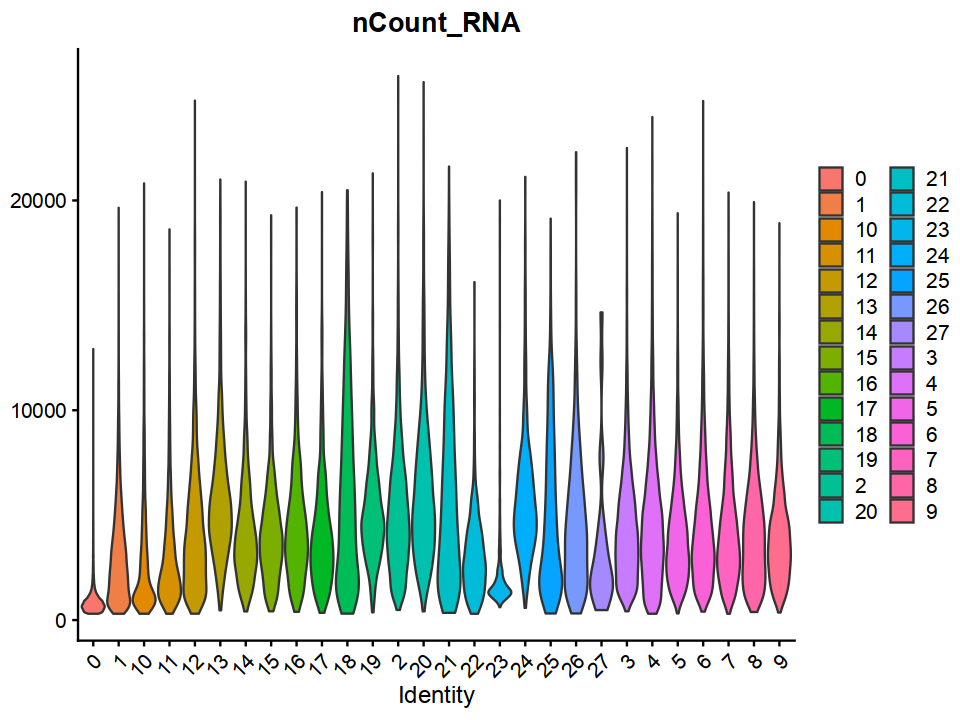

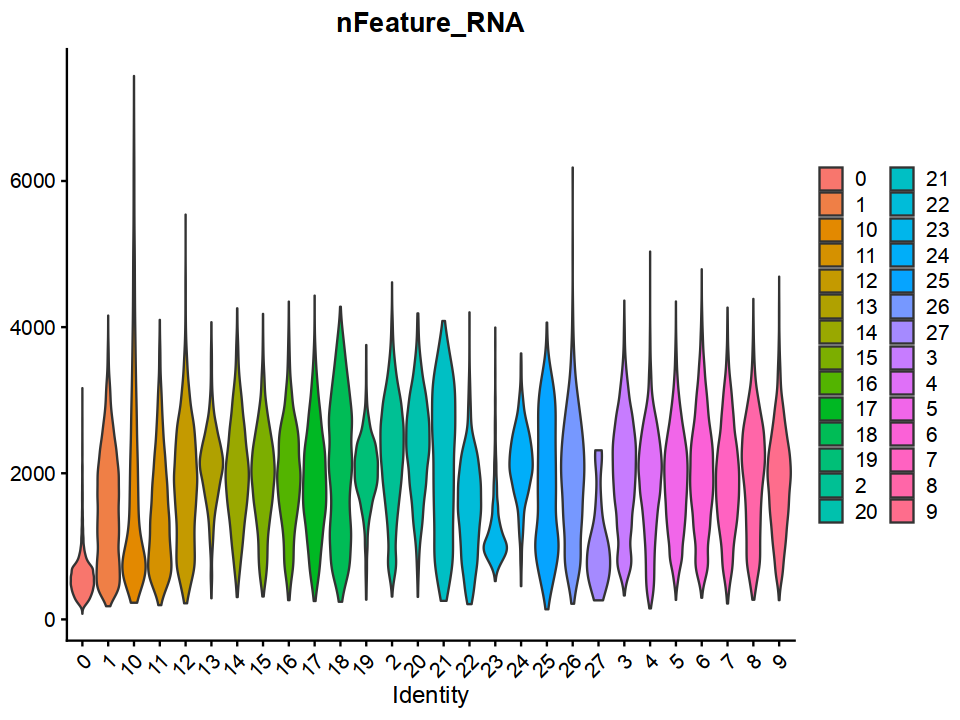

[[1]]

[[2]]

[[3]]

[[4]]


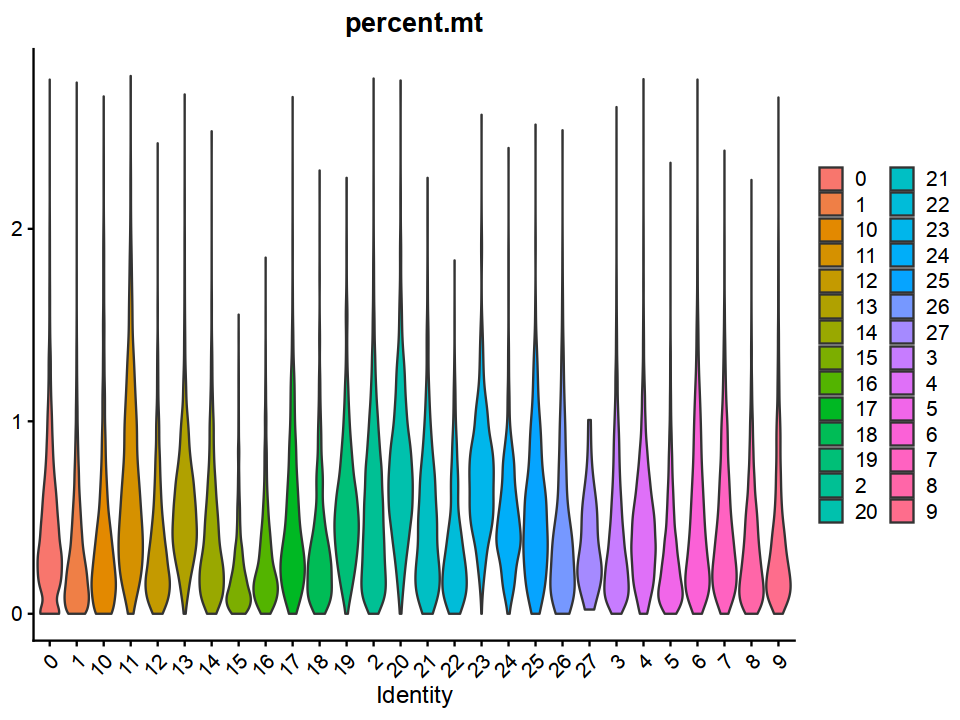

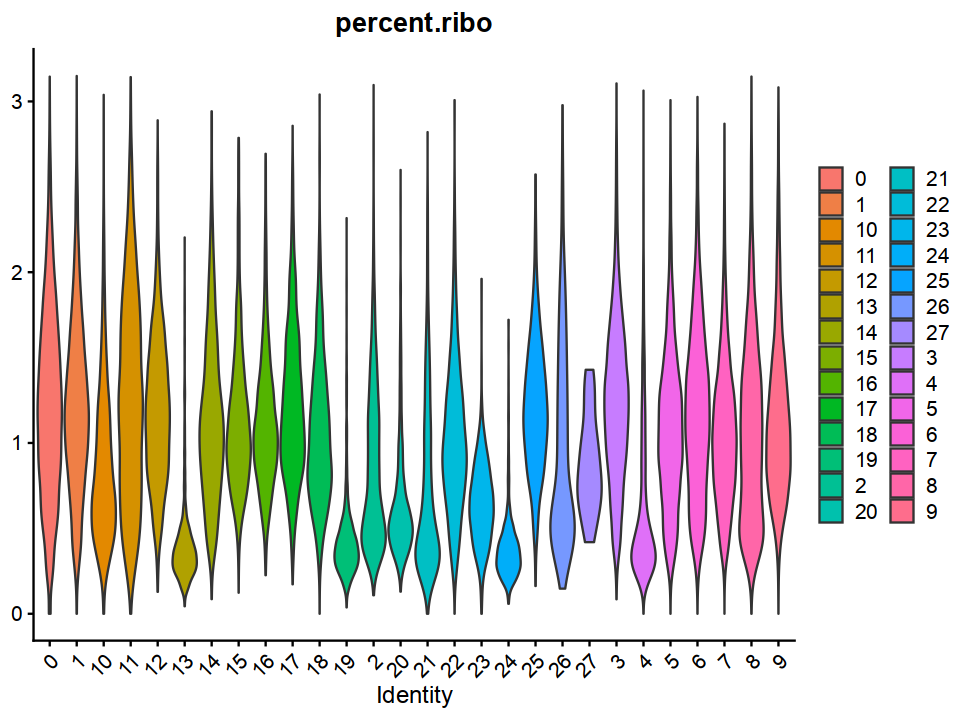

In [45]:
VlnPlot(object = embryo_rna,features = c('nCount_RNA','nFeature_RNA','percent.mt','percent.ribo'),
              ncol = 2, pt.size = 0,group.by = 'RNA_snn_res.0.5', combine = FALSE) 

In [47]:
table(embryo_rna$sample,embryo_rna$RNA_snn_res.0.5)

          
              0    1   10   11   12   13   14   15   16   17   18   19    2
  E10_IH15 1064  775  147  176  315   25   70   16   16   42   58   16  449
  E10_IH16  706  760   83  178  143   34   76   22   23   41   34   21  595
  E10_IH17  996  772   59  179  127   29   71   16   23   47   39   10  491
  E10_IH18 1039  767   86  167  172   27   84   20   21   39   42    8  567
  E10_IH19  828  650   77  165  164   28  107   27   26   64   38    8  617
  E11_HY10  334  187  416  285   27  246   62    0    3    8   10  134  750
  E11_HY11  510  260  366  368   35  472   58    6    2   14    5  209  804
  E11_HY9   386  209  280  324   22  394   62    2    0   10   11  200  781
  E12_HY15  351  193  209  190   34  334   41    4    4   17   18  314  987
  E12_HY16  701  276  341  213   16  353   30    4    3   16   11  339  949
  E12_HY17  559  182  484  247   30  302   25    1    0   13   25  336  822
  E8_II25   562  570   62  111  170    0  145  172  169  183  168    0  231
 

In [48]:
deg <- FindAllMarkers(
  object = embryo_rna,group.by='RNA_snn_res.0.5',
  min.pct = 0.1,           # 至少在10%的细胞中表达
  logfc.threshold = 0.25,  # LogFC阈值
  only.pos = FALSE         # 保留上调和下调基因
)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 10

Calculating cluster 11

Calculating cluster 12

Calculating cluster 13

Calculating cluster 14

Calculating cluster 15

Calculating cluster 16

Calculating cluster 17

Calculating cluster 18

Calculating cluster 19

Calculating cluster 2

Calculating cluster 20

Calculating cluster 21

Calculating cluster 22

Calculating cluster 23

Calculating cluster 24

Calculating cluster 25

Calculating cluster 26

Calculating cluster 27

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8

Calculating cluster 9



In [76]:
write.table(deg, "scCAT_seq/00_scCAT_data/Embryo/processed/RNA/embryo_soupx1_cluster.csv",quote = FALSE)

In [49]:
deg[deg$avg_log2FC > 0,]

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
Hnrnpk,0,0.2914880,0.255,0.540,0,0,Hnrnpk
Hnrnpa1,0,0.3577175,0.308,0.593,0,0,Hnrnpa1
Cdk8,0,0.3618583,0.269,0.542,0,0,Cdk8
Gm26917,0,0.4788838,0.347,0.617,0,0,Gm26917
Calm2,0,0.3543259,0.253,0.508,0,0,Calm2
Rps3a1,0,0.3873379,0.284,0.534,0,0,Rps3a1
Bzw1,0,0.3349025,0.210,0.455,0,0,Bzw1
Rpl6,0,0.3016665,0.221,0.466,0,0,Rpl6
Actg1,0,0.3245198,0.248,0.491,0,0,Actg1


In [50]:
deg %>% group_by(cluster) %>% slice_max(order_by = avg_log2FC, n = 10, with_ties = FALSE)
write.table(deg %>% group_by(cluster) %>% slice_max(order_by = avg_log2FC, n = 5, with_ties = FALSE), "embryo_cluster_top5.csv",quote = FALSE)

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
3.123371e-217,0.6907866,0.209,0.330,8.878182e-213,0,Hes1
9.366718e-180,0.6863978,0.048,0.106,2.662490e-175,0,Synpo
5.266975e-226,0.6392716,0.069,0.150,1.497138e-221,0,Adgra2
0.000000e+00,0.5825032,0.144,0.296,0.000000e+00,0,Rbm8a
3.149766e-150,0.5501455,0.048,0.104,8.953209e-146,0,Pebp4
1.034046e-228,0.5387003,0.055,0.128,2.939276e-224,0,4933431K23Rik
3.334758e-295,0.5384596,0.077,0.171,9.479050e-291,0,H19
2.018850e-192,0.5231457,0.051,0.125,5.738581e-188,0,Magoh
0.000000e+00,0.5162659,0.999,0.999,0.000000e+00,0,AY036118


In [4]:
embryo_rna <- readRDS('/data/bio_data/zhangzhongjin/data/scCAT_seq/00_scCAT_data/Embryo/processed/RNA/embro_RNA_soupx1_filtered.rds')

In [5]:
embryo_rna_data <- embryo_rna[,!embryo_rna$RNA_snn_res.0.5 == 0]

In [9]:
embryo_rna_data@meta.data

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,percent.ribo,percent_mito,percent_ribo,percent_mito_ribo,log10GenesPerUMI,outlier,scDblFinder.class,scDblFinder.score,sample,Sample,RNA_snn_res.0.5,seurat_clusters
,<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<chr>,<dbl>,<chr>,<chr>,<fct>,<fct>
E8_II25_BC5283_N01,E8,312,200,0.0000000,0.3205128,0.0000000,0.3205128,0.3205128,0.9225691,FALSE,singlet,0.04807692,E8_II25,E8,1,1
E8_II25_BC5282_N02,E8,2949,1729,0.5425568,0.7121058,0.5425568,0.7121058,1.2546626,0.9331696,FALSE,singlet,0.39511676,E8_II25,E8,14,14
E8_II25_BC5277_N02,E8,1884,1002,0.2653928,2.2823779,0.2653928,2.2823779,2.5477707,0.9162729,FALSE,singlet,0.36387785,E8_II25,E8,11,11
E8_II25_BC5267_N01,E8,1916,1121,0.2609603,0.5219207,0.2609603,0.5219207,0.7828810,0.9290793,FALSE,singlet,0.29605934,E8_II25,E8,18,18
E8_II25_BC5265_N01,E8,2305,1420,0.2603037,0.9978308,0.2603037,0.9978308,1.2581345,0.9374359,FALSE,singlet,0.31819368,E8_II25,E8,14,14
E8_II25_BC5264_N01,E8,1136,687,0.2640845,0.7042254,0.2640845,0.7042254,0.9683099,0.9285124,FALSE,singlet,0.26158759,E8_II25,E8,7,7
E8_II25_BC5253_N01,E8,1211,809,0.1651528,1.3212221,0.1651528,1.3212221,1.4863749,0.9431763,FALSE,singlet,0.32696881,E8_II25,E8,10,10
E8_II25_BC5249_N01,E8,1171,798,0.3415884,1.3663535,0.3415884,1.3663535,1.7079419,0.9457224,FALSE,singlet,0.27304471,E8_II25,E8,1,1
E8_II25_BC5245_N01,E8,1247,838,0.0000000,0.8821171,0.0000000,0.8821171,0.8821171,0.9442410,FALSE,singlet,0.36919855,E8_II25,E8,6,6


In [11]:
blacklist.genes=GetBlackListGenes(embryo_rna_data, MT=TRUE, Ribo=TRUE, Cellcycle=FALSE, Sex=FALSE)

  2135 genes were dropped because they have exons located on both strands
  of the same reference sequence or on more than one reference sequence,
  so cannot be represented by a single genomic range.
  Use 'single.strand.genes.only=FALSE' to get all the genes in a
  GRangesList object, or use suppressMessages() to suppress this message.

'select()' returned 1:1 mapping between keys and columns



In [12]:
embryo_rna_data <- Process_RNA(embryo_rna_data,nfeatures=3000,pc.nums=50, dims=1:50, pca.name = 'pca', umap.name= 'umap.rna', res = c(0.3,0.5,0.8))
var_int <- "sample"
embryo_rna_data <- RunHarmony(embryo_rna_data, group.by.vars = var_int, assay.use="RNA", reduction.use = "pca", plot_convergence = FALSE)
red_use <- "harmony"
dims_use <- 1:50
nneigh <- 50
embryo_rna_data <- RunUMAP(object = embryo_rna_data, reduction = red_use, dims = dims_use,n.neighbors = nneigh)
embryo_rna_data <- FindNeighbors(embryo_rna_data, verbose = T, reduction = red_use, dims = dims_use)
embryo_rna_data <- FindClusters(embryo_rna_data, verbose = T, algorithm = 1, resolution = 0.5)

Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
"Different features in new layer data than already exists for scale.data"
PC_ 1 
Positive:  Map2, Akap6, Dcx, Ctnna2, Cadps, Unc79, Tmem178b, Myt1l, Scn3a, Xkr4 
	   Nrxn1, Mapk10, Fam155a, Gm26871, Gria2, Elavl3, Dcc, Hecw1, Myt1, Rims2 
	   Stmn2, Sorbs2, Celf4, Ppfia2, Pak7, Gpm6a, Nol4, Phactr1, Rab3c, Thsd7a 
Negative:  Gpc3, Airn, Fn1, Fbn2, Igf2r, Igf2, Prtg, Mki67, Mest, Serpinh1 
	   Lamb1, Col4a1, Rbpms, A630012P03Rik, Colec12, Gja1, Col18a1, Pdgfra, Col3a1, Col4a2 
	   Rbms1, Nid2, Tpm1, Dlc1, Nhsl2, Pdzrn3, Cgnl1, Gm28153, Slc16a1, Hmcn1 
PC_ 2 
Positive:  Adgrv1, Slc4a1, Rfx4, Tfrc, Sox2ot, Spta1, Ildr2, Kel, Slc25a21, Fgf14 
	   Gypa, Dcc, Pax6, Rhag, Prtg, Ermap, Mki67, Slc25a37, Acp5, Hbb-bh1 
	   Car2, Snca, Hemgn, Plch1, Gm32061, Hba-x, Pkhd1l1, Mir142hg, Ptprn2, Epb42 
Negative:  Rbms3, Mbnl2, Dlc1, Lpp, Bnc2, Airn, Col3a1, Ddr2, Cald1, Cacna1c 


Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 109215
Number of edges: 4396399

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9459
Number of communities: 29
Elapsed time: 45 seconds


1 singletons identified. 28 final clusters.



Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



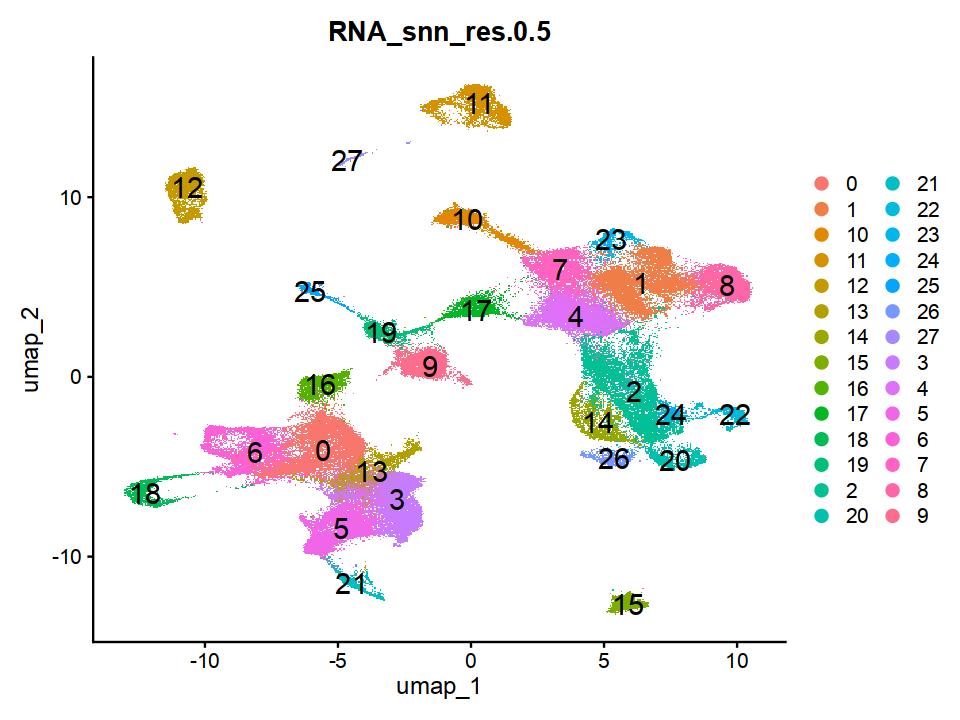

In [13]:
options(repr.plot.width=8, repr.plot.height=6)
DimPlot(embryo_rna_data, label = TRUE, group.by = 'RNA_snn_res.0.5',label.size = 6) #+ NoLegend()

Warning message:
"The `slot` argument of `FetchData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>."
Warning message:
"`PackageCheck()` was deprecated in SeuratObject 5.0.0.
ℹ Please use `rlang::check_installed()` instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>."
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



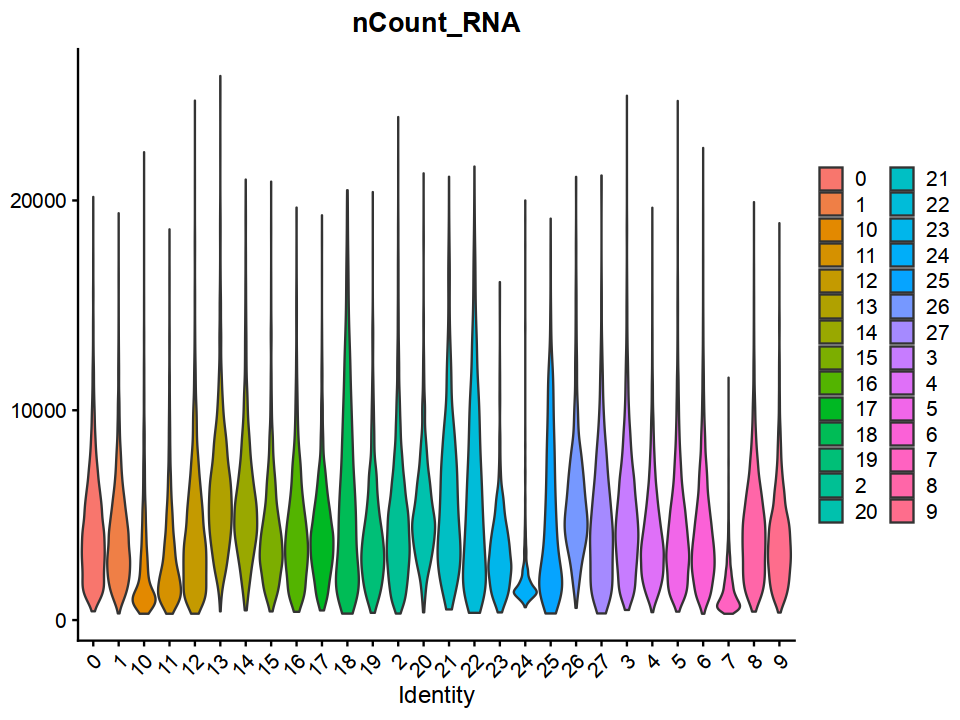

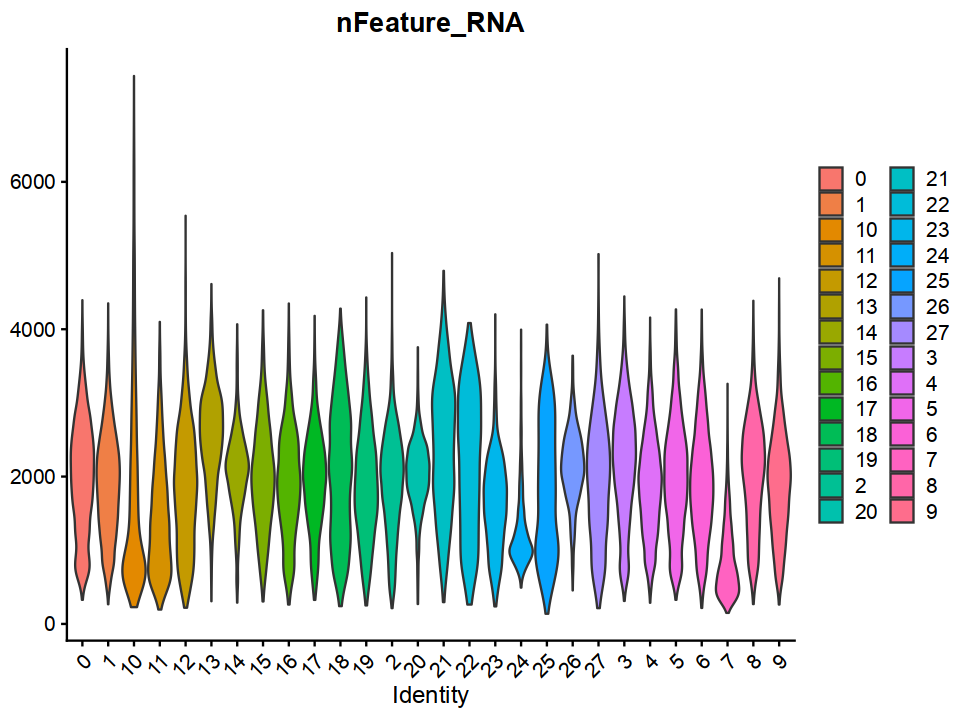

[[1]]

[[2]]

[[3]]

[[4]]


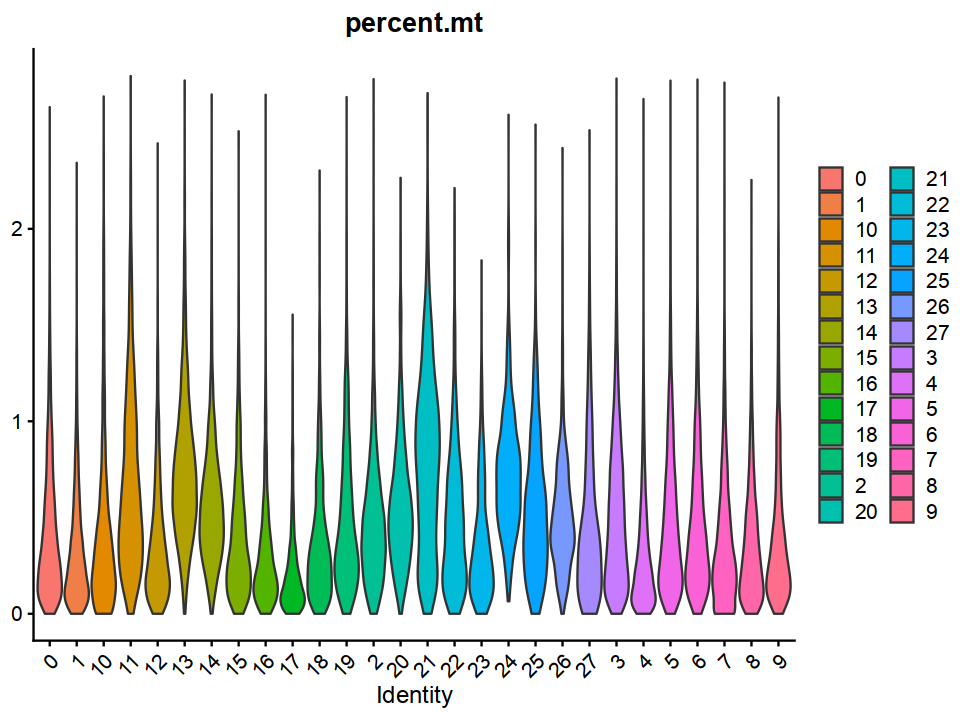

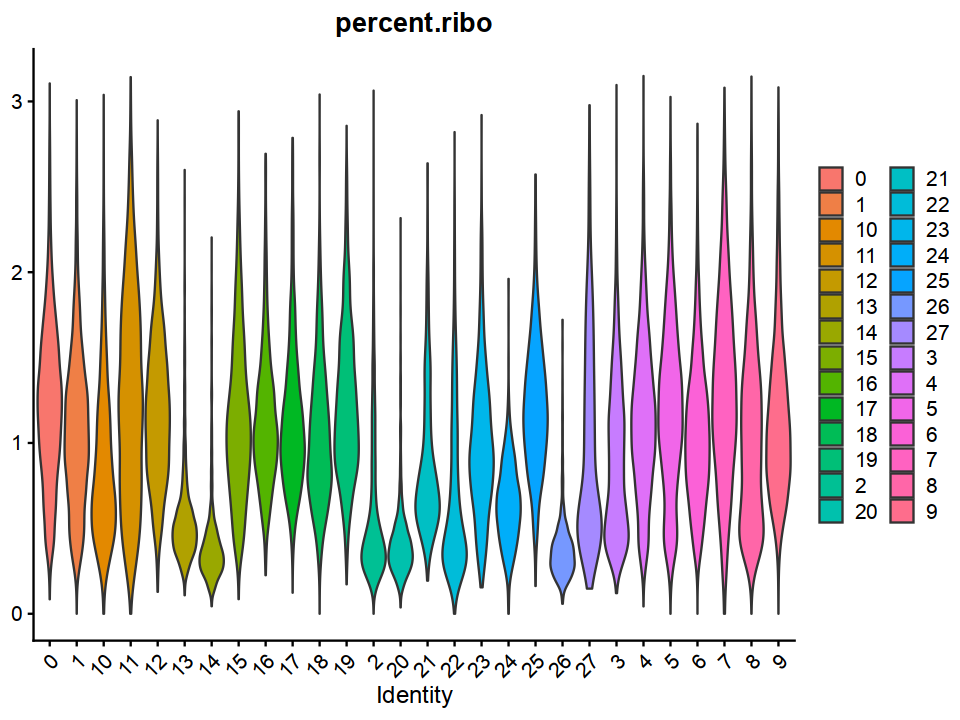

In [14]:
VlnPlot(object = embryo_rna_data,features = c('nCount_RNA','nFeature_RNA','percent.mt','percent.ribo'),
              ncol = 2, pt.size = 0,group.by = 'RNA_snn_res.0.5', combine = FALSE) 

In [15]:
saveRDS(embryo_rna_data,'/data/bio_data/zhangzhongjin/data/scCAT_seq/00_scCAT_data/Embryo/processed/RNA/embro_RNA_soupx1_filtered_2.rds')

# ATAC

In [33]:
# ATAC DATA path
data_path='scCAT_seq/00_scCAT_data/Embryo/'
sample_names=c('E8_II25_web_0', 'E8_II26_web_0', 'E8_II27_web_0', 'E8_II28_web_0', 'E8_II29_web_0', 'E9_II30_web_0', 'E9_II31_web_0', 'E9_II32_web_0', 'E10_IH15_web_0','E10_IH16_web_0','E10_IH17_web_0','E10_IH18_web_0','E10_IH19_web_0','E11_HY9_web_0','E11_HY10_web_0','E11_HY11_web_0','E12_HY15_web_0','E12_HY16_web_0','E12_HY17_web_0')
names=c('E8_II25', 'E8_II26', 'E8_II27', 'E8_II28', 'E8_II29', 'E9_II30', 'E9_II31', 'E9_II32', 'E10_IH15','E10_IH16','E10_IH17','E10_IH18','E10_IH19','E11_HY9','E11_HY10','E11_HY11','E12_HY15','E12_HY16','E12_HY17')
#
counts_files=c()
frag_files = c()
for (i in 1:length(sample_names)){
    counts_files=c(counts_files, paste0(data_path, sample_names[i],'/ATAC/Peak/'))
    frag_pattern <- file.path(data_path, sample_names[i], "ATAC", "*.fragments.tsv.gz")
    frag_files <- c(frag_files,Sys.glob(frag_pattern))
}
for (i in counts_files){print (i); print (dir.exists(i))}
for (i in frag_files){print (i); print (file.exists(i))}

[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II25_web_0/ATAC/Peak/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II26_web_0/ATAC/Peak/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II27_web_0/ATAC/Peak/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II28_web_0/ATAC/Peak/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E8_II29_web_0/ATAC/Peak/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E9_II30_web_0/ATAC/Peak/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E9_II31_web_0/ATAC/Peak/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E9_II32_web_0/ATAC/Peak/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH15_web_0/ATAC/Peak/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH16_web_0/ATAC/Peak/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH17_web_0/ATAC/Peak/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH18_web_0/ATAC/Peak/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E10_IH19_web_0/ATAC/Peak/"
[1] TRUE
[1] "scCAT_seq/00_scCAT_data/Embryo/E11_HY9_web_0/ATAC/Peak/"
[1] TRUE
[

In [73]:
# 批量创建SeuratObject
for (i in 1:length(counts_files)){
    counts <- LoadData(data_path=counts_files[i])
    atac.assay <- CreateChromatinAssay(counts, fragments = frag_files[i], sep = c(":", "-"))
    seurat.obj <- CreateSeuratObject(atac.assay, assay = "ATAC")
    # meta=seurat.obj@meta.data[, c('nCount_ATAC', 'nFeature_ATAC')]
    # colnames(meta)=c('nCounts', 'nFeatures')
    #
    seurat.list[[i]] <- seurat.obj
}

Computing hash

Computing hash

Computing hash

Computing hash

Computing hash

Computing hash

Computing hash

Computing hash

Computing hash

Computing hash

Computing hash

Computing hash

Computing hash

Computing hash

Computing hash

Computing hash

Computing hash

Computing hash

Computing hash



In [136]:
### add meta
for (i in 1:length(seurat.list)){
    seu <- seurat.list[[i]]
    # read counts
    f_counts <- CountFragments(frag_files[i])
    row.names(f_counts)=f_counts$CB
    seu$fragments <- f_counts[colnames(seu), "frequency_count"]
    # FRiP
    seu <- FRiP(object = seu,assay = "ATAC",total.fragments = "fragments",col.name = "FRiP")
    # 添加基因组注释 
    seu <- annotate_ATAC_obj(seu,annotation='mm10')
    # TSS
    seu <- TSSEnrichment(seu)
    # NucleosomeSignal
    seu <- NucleosomeSignal(seu)
    # blacklist fraction
    seu$blacklist_fraction <- FractionCountsInRegion(seu,assay = 'ATAC',regions = blacklist_mm10)
    seurat.list[[i]] <- seu
}

Calculating fraction of reads in peaks per cell

Extracting TSS positions

Extracting fragments at TSSs


Computing TSS enrichment score

Warning message in .merge_two_Seqinfo_objects(x, y):
"Each of the 2 combined objects has sequence levels not in the other:
  - in 'x': chrM
  - in 'y': chr20, chr21, chr22
  Make sure to always combine/compare objects based on the same reference
  genome (use suppressWarnings() to suppress this warning)."
Calculating fraction of reads in peaks per cell

Extracting TSS positions

Extracting fragments at TSSs


Computing TSS enrichment score

Warning message in .merge_two_Seqinfo_objects(x, y):
"Each of the 2 combined objects has sequence levels not in the other:
  - in 'x': chrM
  - in 'y': chr20, chr21, chr22
  Make sure to always combine/compare objects based on the same reference
  genome (use suppressWarnings() to suppress this warning)."
Calculating fraction of reads in peaks per cell

Extracting TSS positions

Extracting fragments at TSSs


Comp

In [137]:
# outlier / doublet
for (i in 1:length(seurat.list)){
    # outliers
    # seurat.list[[i]] <- subset(seurat.list[[i]], subset = nCount_ATAC > 100)
    outlier <- is_outlier(seurat.list[[i]], "nCount_ATAC", 4) | 
                is_outlier(seurat.list[[i]], "TSS.enrichment", 4) | 
                is_outlier(seurat.list[[i]], "FRiP", 4) |
                is_outlier(seurat.list[[i]], "blacklist_fraction", 4)
    seurat.list[[i]]$outlier <- outlier
    # doublets
    seurat.list[[i]] <- runscDblFinder(seurat.list[[i]], assay='ATAC')
    # save result
    write.csv(seurat.list[[i]]@meta.data, paste0('scCAT_seq/00_scCAT_data/Embryo/processed/ATAC/meta/', names[i], '_meta.csv'), quote=FALSE)
}
saveRDS(seurat.list,'/data/bio_data/data/scCAT_seq/00_scCAT_data/Embryo/processed/embro_ATAC_seulist.rds')

Aggregating features...

Warning message:
"Quick-TRANSfer stage steps exceeded maximum (= 6870850)"
Clustering cells...

Warning message in (function (A, nv = 5, nu = nv, maxit = 1000, work = nv + 7, reorth = TRUE, :
"You're computing too large a percentage of total singular values, use a standard svd instead."
10 clusters

Creating ~4233 artificial doublets...

Dimensional reduction

Evaluating kNN...

Training model...

iter=0, 365 cells excluded from training.

iter=1, 365 cells excluded from training.

iter=2, 365 cells excluded from training.

Threshold found:0.527

403 (7.6%) doublets called

Warning message in .checkSCE(sce):
"Some cells in `sce` have an extremely low read counts; note that these could trigger errors and might best be filtered out"
Aggregating features...

Warning message:
"Quick-TRANSfer stage steps exceeded maximum (= 7786300)"
Clustering cells...

Warning message in (function (A, nv = 5, nu = nv, maxit = 1000, work = nv + 7, reorth = TRUE, :
"You're computing

In [ ]:
# merge seulist
seurat.obj <- merge(x = seurat.list[[1]], y = seurat.list[c(1:length(seurat.list))[-1]])

In [59]:
seurat.obj

An object of class Seurat 
264125 features across 156478 samples within 1 assay 
Active assay: ATAC (264125 features, 0 variable features)
 2 layers present: counts, data

---

In [153]:
embryo_atac <- readRDS('/data/bio_data/data/scCAT_seq/00_scCAT_data/Embryo/processed/embro_ATAC_seuobj.rds')

In [155]:
# read metadata
meta_files=list.files('scCAT_seq/00_scCAT_data/Embryo/processed/ATAC/meta/', full.names=TRUE)
meta_datas=data.frame()
for (i in 1:length(meta_files)){
    meta_data=read.csv(meta_files[i], row.names=1)
    meta_datas=rbind(meta_datas,meta_data)
}
# 处理sample名
meta_datas$sample <- sub("^([^_]+_[^_]+)_.*", "\\1", rownames(meta_datas))
meta_datas$Sample <- meta_datas$orig.ident
#
meta_datas <- subset(meta_datas, nCount_ATAC > 0)

In [158]:
embryo_atac@meta.data <- meta_datas[colnames(embryo_atac),]

In [167]:
embryo_atac

An object of class Seurat 
264125 features across 156478 samples within 1 assay 
Active assay: ATAC (264125 features, 0 variable features)
 2 layers present: counts, data

In [168]:
saveRDS(embryo_atac,'/data/bio_data/data/scCAT_seq/00_scCAT_data/Embryo/processed/embro_ATAC_seuobj.rds')

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



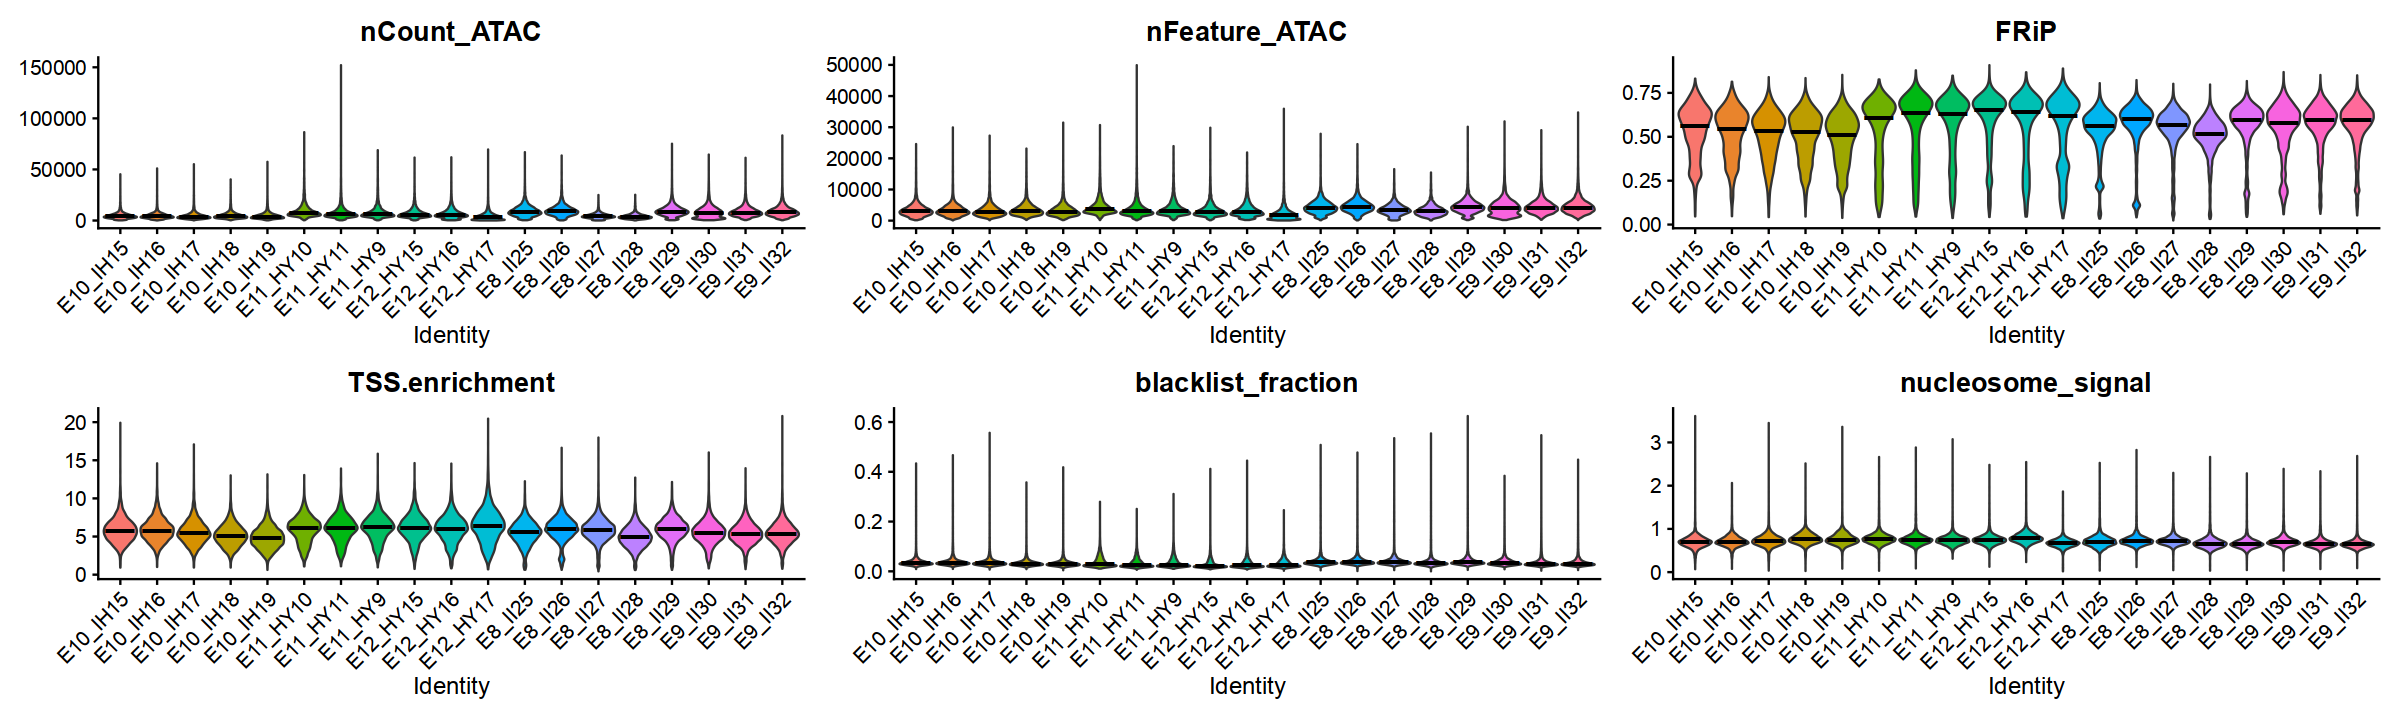

In [162]:
Plot_QC_ATAC(embryo_atac, group='sample', width=20, height=6)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



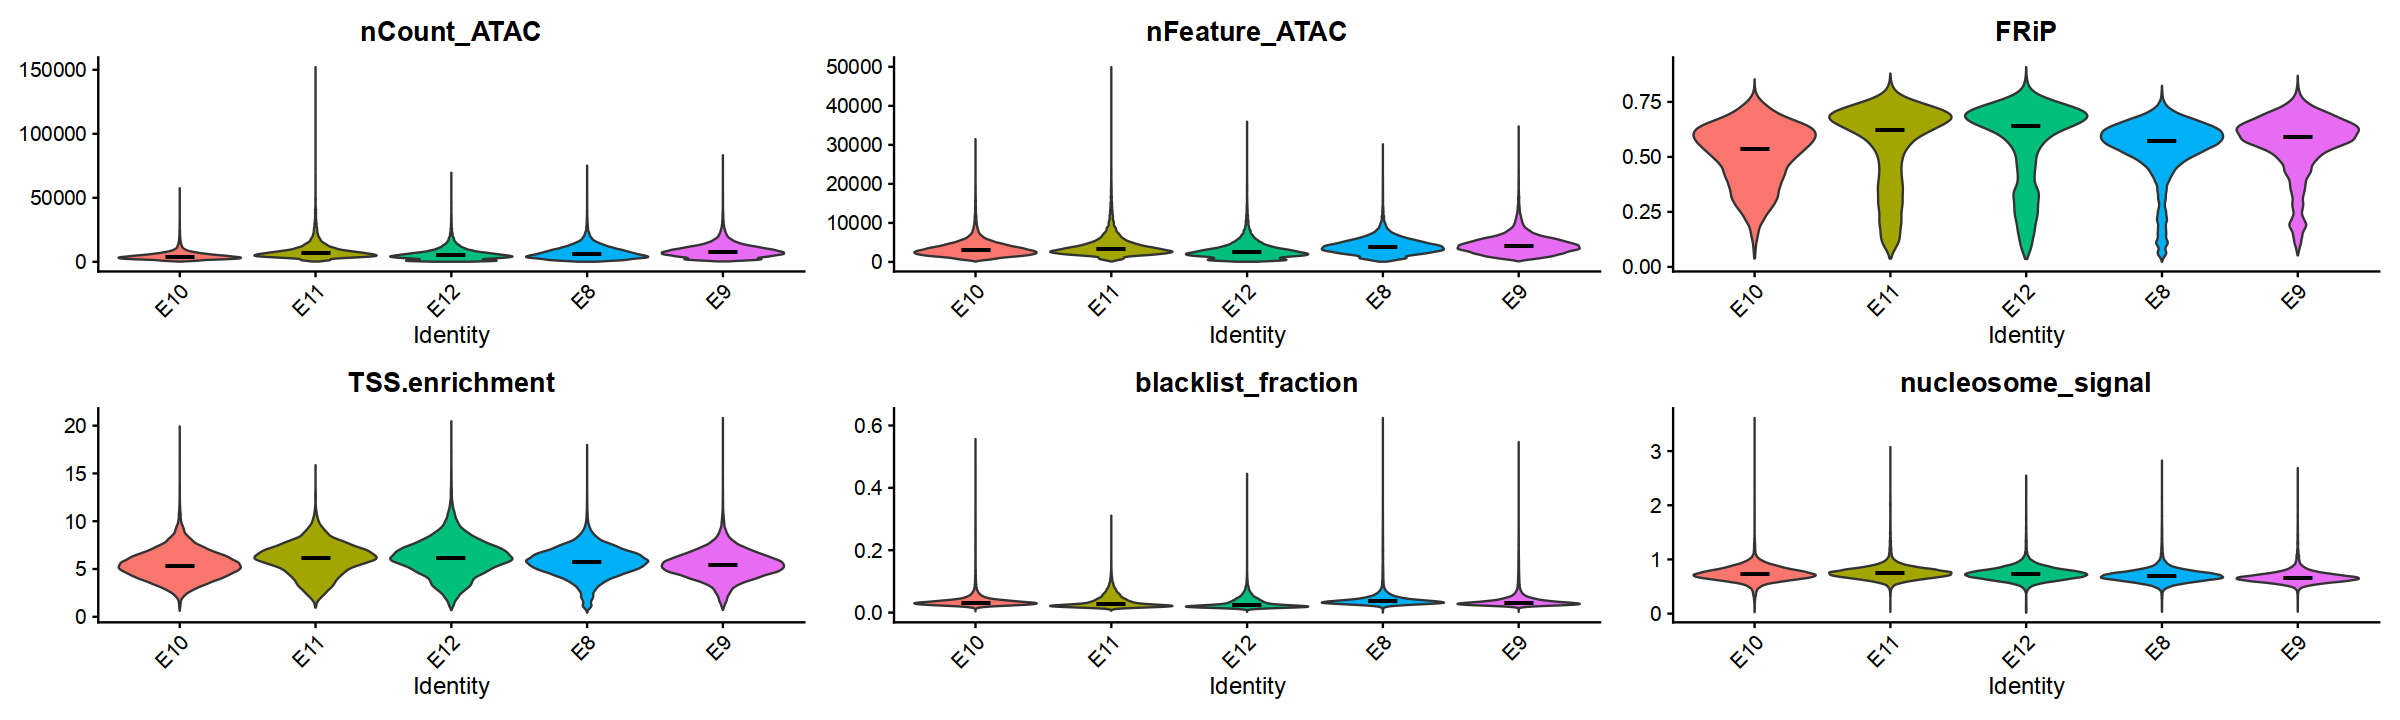

In [169]:
Plot_QC_ATAC(embryo_atac, group='orig.ident', width=20, height=6)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Picking joint bandwidth of 437

Picking joint bandwidth of 207

Picking joint bandwidth of 0.0166

Picking joint bandwidth of 0.175

Picking joint bandwidth of 0.00143

Picking joint bandwidth of 0.0116



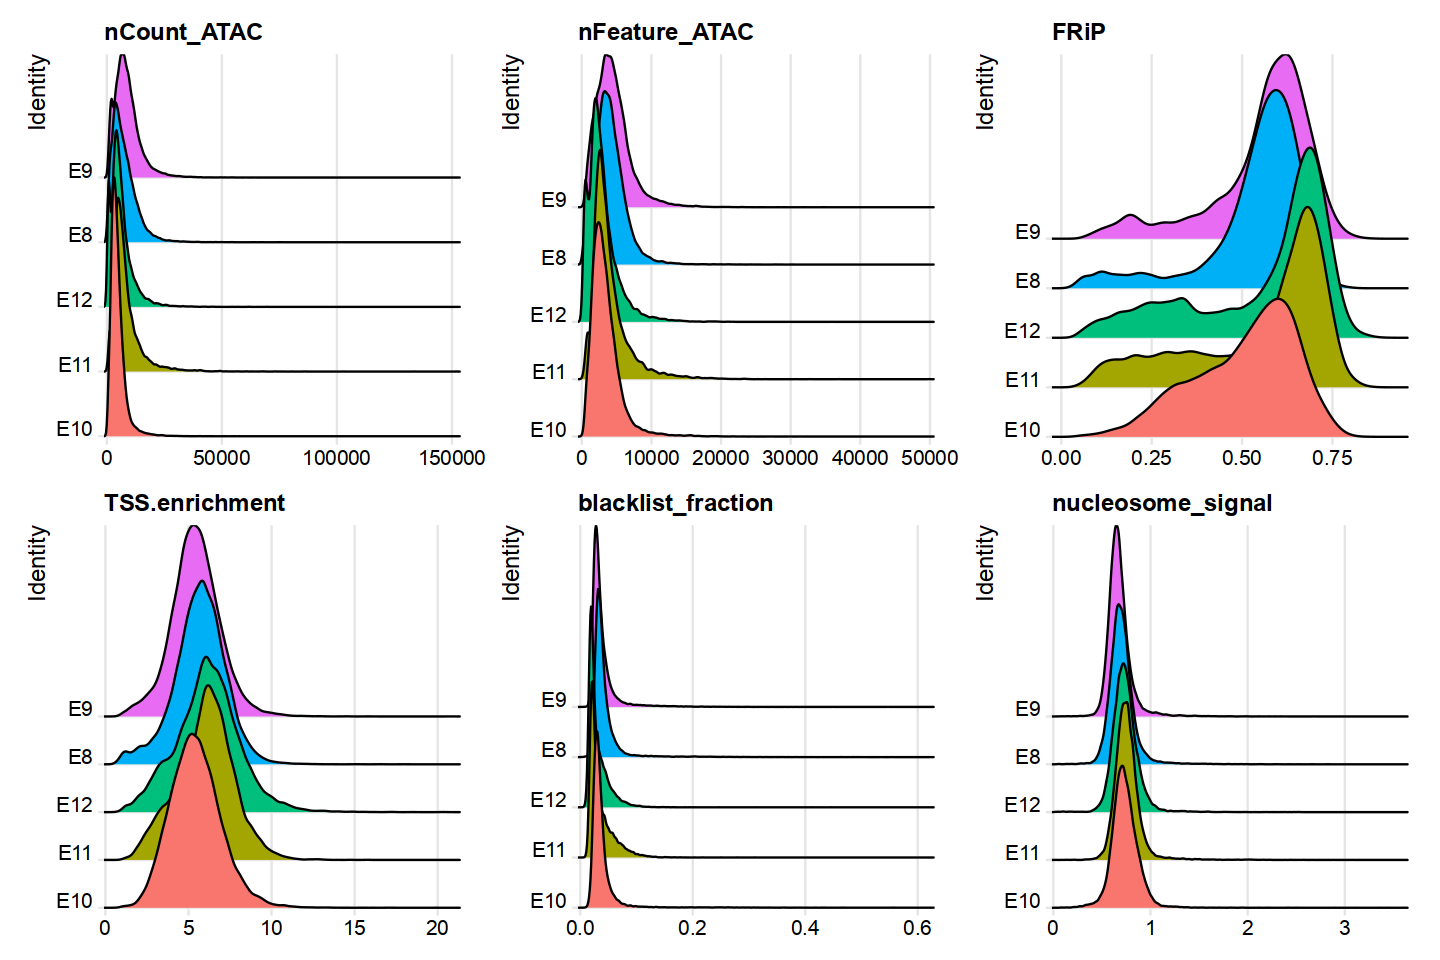

In [164]:
options(repr.plot.width=12, repr.plot.height=8)
RidgePlot(embryo_atac, group.by = 'orig.ident', features = c('nCount_ATAC', 'nFeature_ATAC', 'FRiP',
               'TSS.enrichment', 'blacklist_fraction', 'nucleosome_signal'), ncol = 3)

Warning message:
"Removed 4348 rows containing non-finite outside the scale range (`stat_density()`)."
Warning message:
"Removed 10898 rows containing non-finite outside the scale range (`stat_density()`)."
Warning message:
"Removed 3 rows containing non-finite outside the scale range (`stat_density()`)."
Warning message:
"Removed 142530 rows containing non-finite outside the scale range (`stat_density()`)."
Warning message:
"Removed 62 rows containing non-finite outside the scale range (`stat_density()`)."


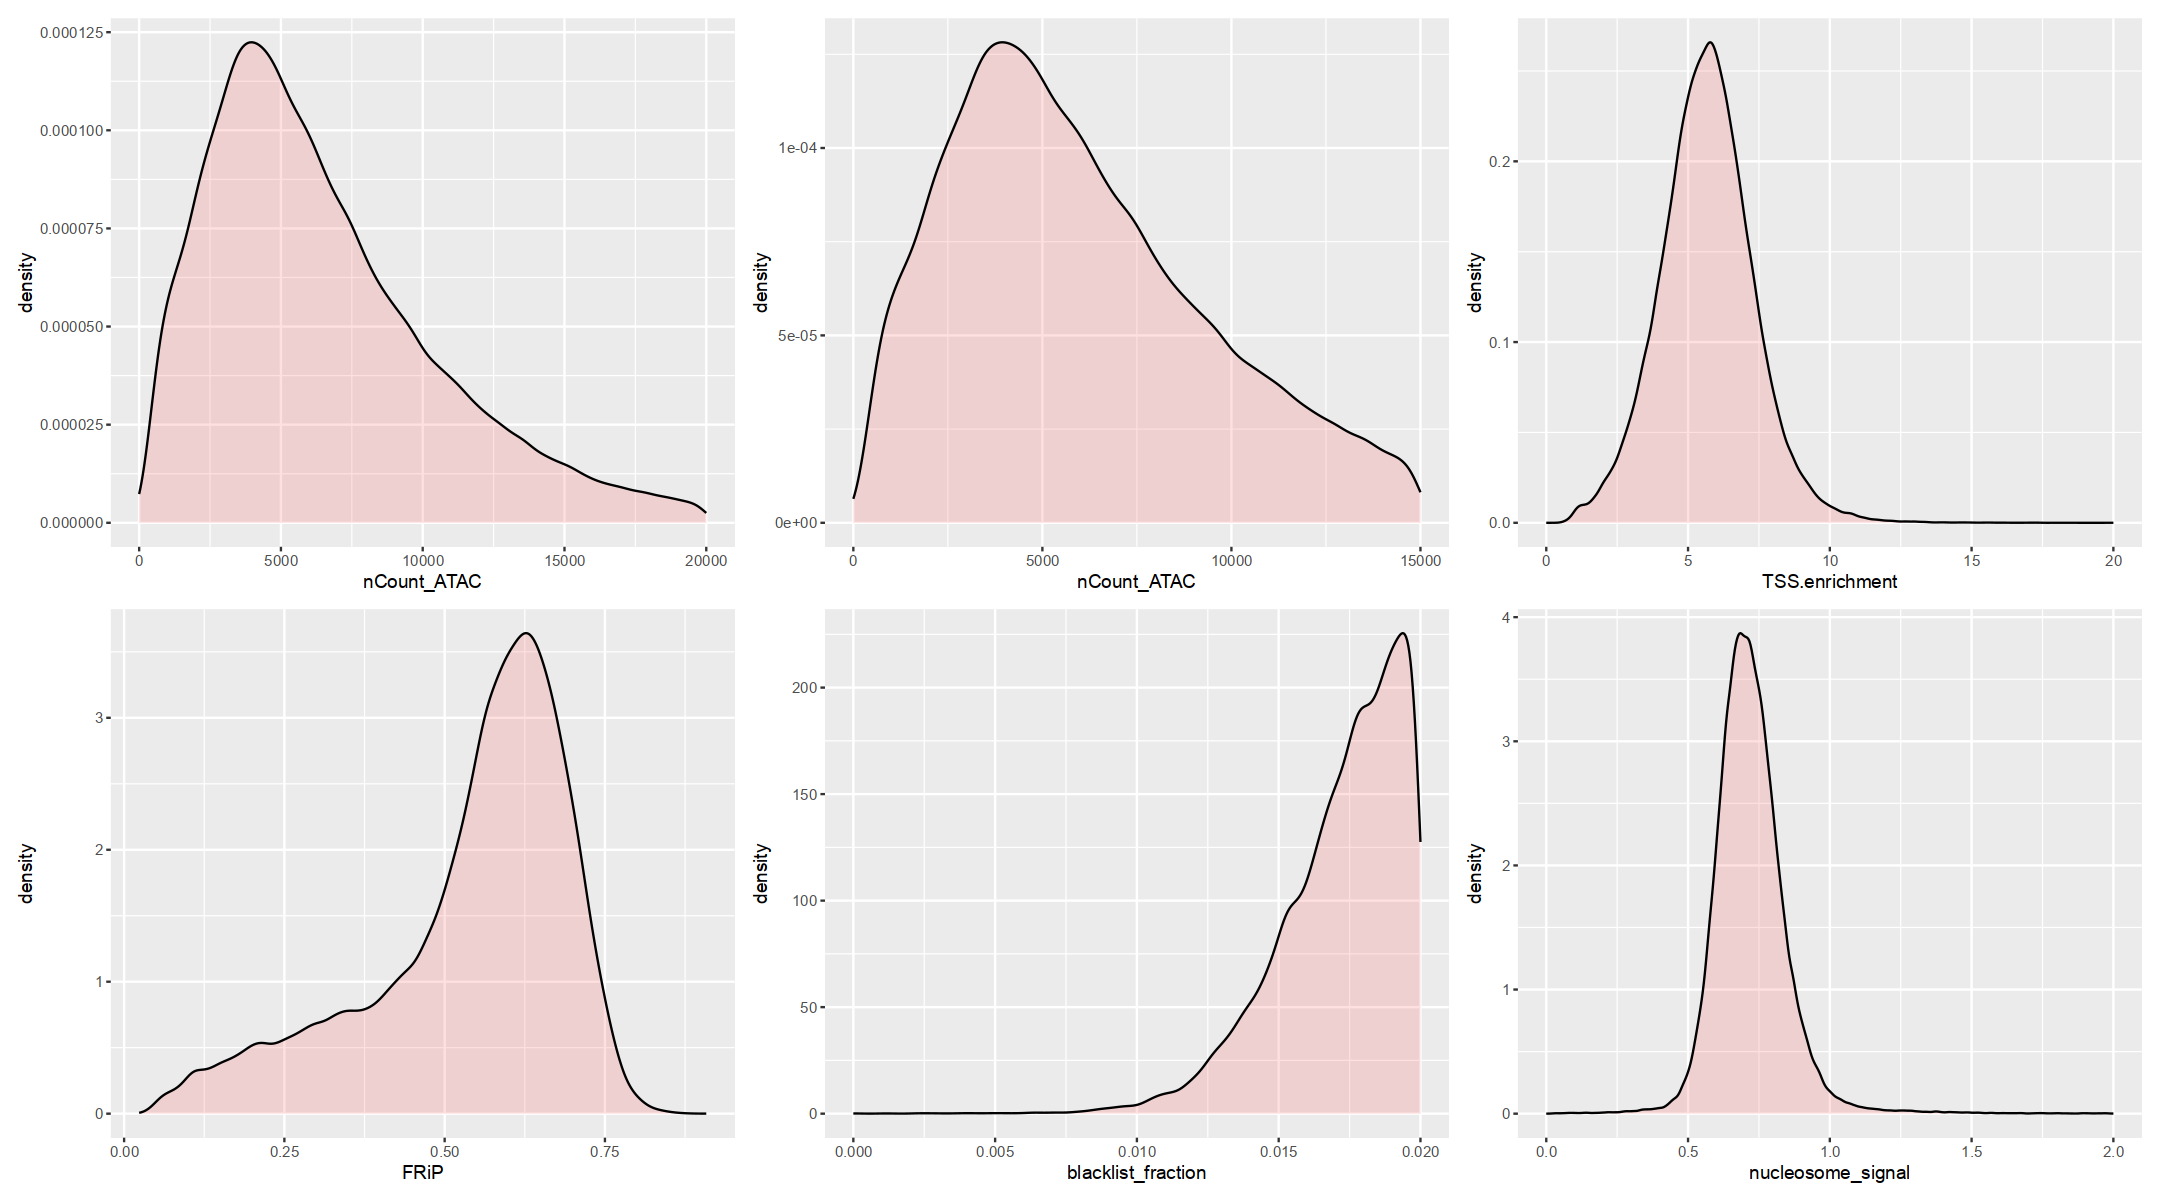

In [171]:
options(repr.plot.width=18, repr.plot.height=10)
p1=ggplot(embryo_atac@meta.data, aes(x=nCount_ATAC)) + geom_density(alpha=.2, fill="#FF6666") + scale_x_continuous(limits = c(0, 20000))
p2=ggplot(embryo_atac@meta.data, aes(x=nCount_ATAC)) + geom_density(alpha=.2, fill="#FF6666") + scale_x_continuous(limits = c(0, 15000))
p3=ggplot(embryo_atac@meta.data, aes(x=TSS.enrichment)) + geom_density(alpha=.2, fill="#FF6666") + scale_x_continuous(limits = c(0, 20)) #+ theme_classic()
p4=ggplot(embryo_atac@meta.data, aes(x=FRiP)) + geom_density(alpha=.2, fill="#FF6666")
p5=ggplot(embryo_atac@meta.data, aes(x=blacklist_fraction)) + geom_density(alpha=.2, fill="#FF6666") + scale_x_continuous(limits = c(0, 0.02)) #+ theme_classic()
# p6=ggplot(meta_datas, aes(x=MitoProportion)) + geom_density(alpha=.2, fill="#FF6666") + scale_x_continuous(limits = c(0, 0.2))
p6=ggplot(seurat.obj@meta.data, aes(x=nucleosome_signal)) + geom_density(alpha=.2, fill="#FF6666") + scale_x_continuous(limits = c(0, 2))
p1+p2+p3+p4+p5+p6

In [37]:
embryo_atac <- readRDS('embryo/00_rawdata/embro_ATAC_seuobj.rds')

In [38]:
embryo_atac@meta.data$stage <- sapply(strsplit(embryo_atac$sample,"_"), "[", 1)
embryo_atac$stage <- factor(embryo_atac$stage,levels=c('E8','E9','E10','E11','E12'))
embryo_atac$log10_nCount_ATAC <- log10(embryo_atac$nCount_ATAC)
embryo_atac$log10_nFeature_ATAC <- log10(embryo_atac$nFeature_ATAC)

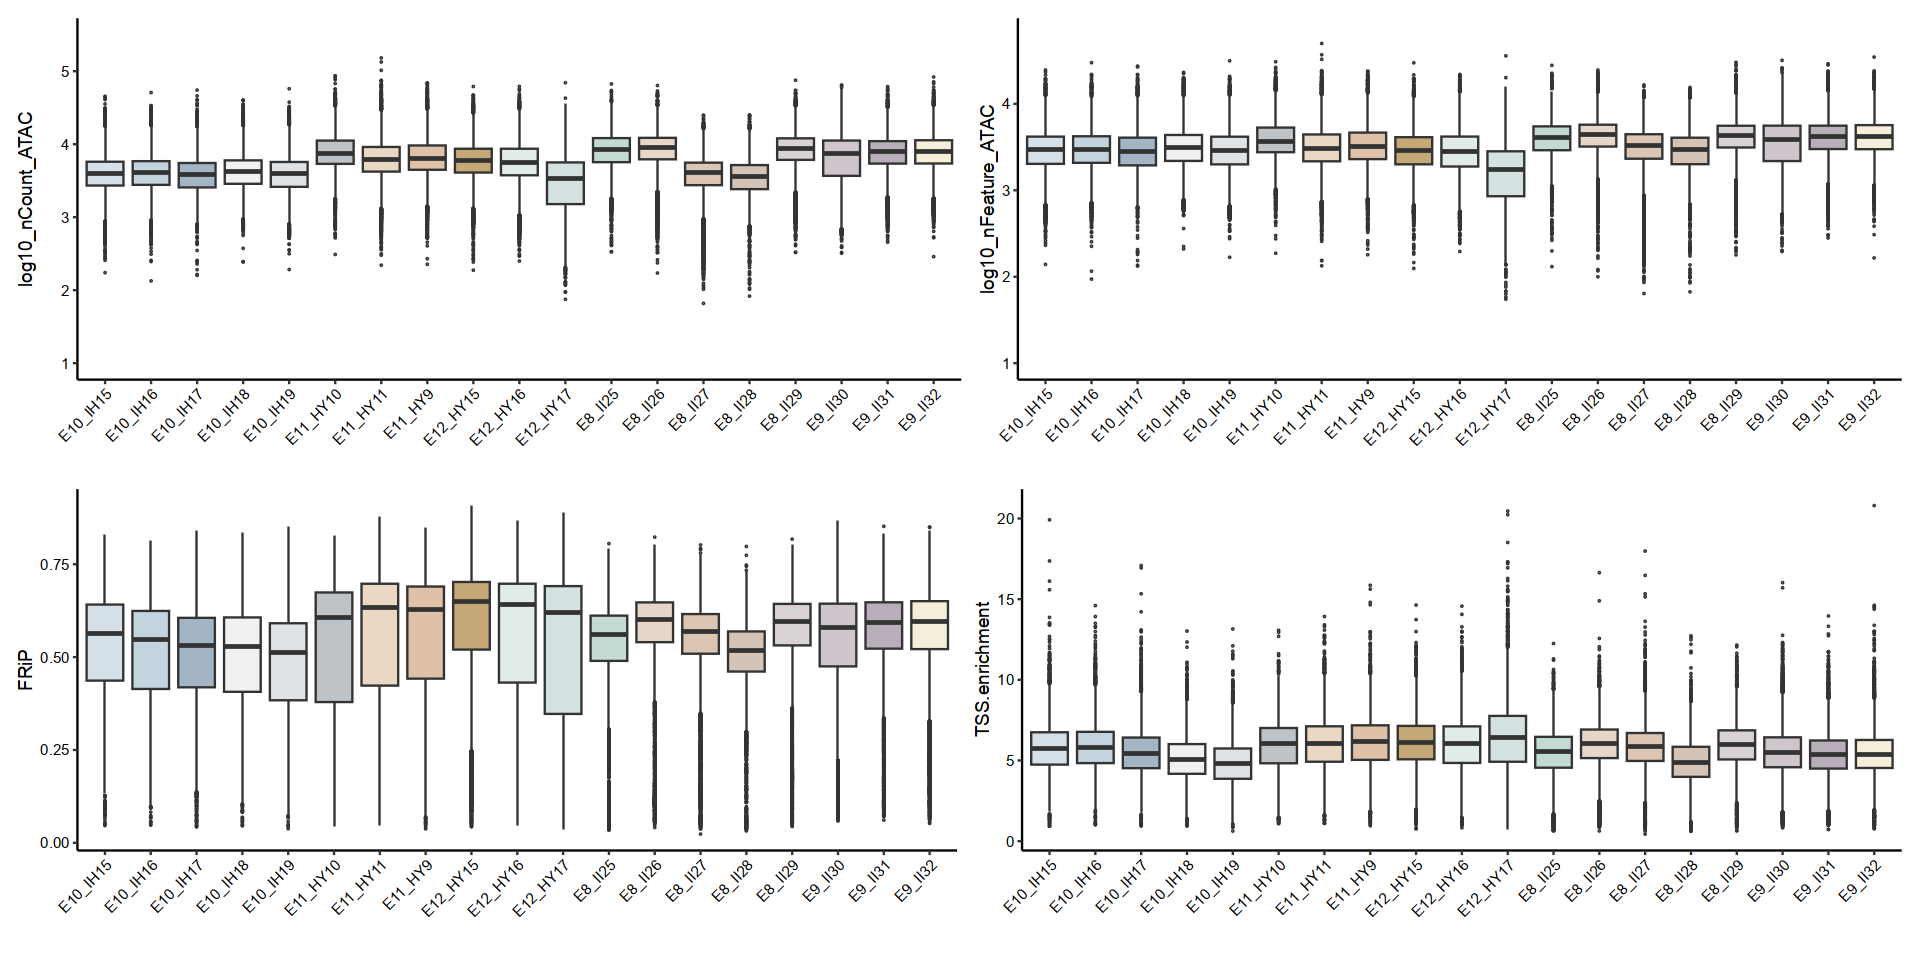

In [49]:
options(repr.plot.width = 16, repr.plot.height = 8)
p1 <- ggplot(embryo_atac@meta.data, aes_string(x = 'sample', y = 'log10_nCount_ATAC', fill = 'sample')) +
            geom_boxplot(outlier.shape = 1, outlier.size = 0.01, width = 0.8) +  # 设置异常值点的形状和大小，以及箱线图的宽度
            scale_fill_manual(values = color) + theme(legend.position='none') + xlab('') + ylim(1, 5.5) +
            theme(panel.background = element_rect(fill = "white"), axis.text.x = element_text(angle = 45, hjust = 1),
            axis.line = element_line(colour = "black"), axis.text = element_text(colour = "black"), axis.title = element_text(colour = "black"))
p2 <- ggplot(embryo_atac@meta.data, aes_string(x = 'sample', y = 'log10_nFeature_ATAC', fill = 'sample')) +
            geom_boxplot(outlier.shape = 1, outlier.size = 0.01, width = 0.8) +  # 设置异常值点的形状和大小，以及箱线图的宽度
            scale_fill_manual(values = color) + theme(legend.position='none') + xlab('') + ylim(1, 4.8) +
            theme(panel.background = element_rect(fill = "white"), axis.text.x = element_text(angle = 45, hjust = 1),
            axis.line = element_line(colour = "black"), axis.text = element_text(colour = "black"), axis.title = element_text(colour = "black"))
p3 <- ggplot(embryo_atac@meta.data, aes_string(x = 'sample', y = 'FRiP', fill = 'sample')) +
            geom_boxplot(outlier.shape = 1, outlier.size = 0.01, width = 0.8) +  # 设置异常值点的形状和大小，以及箱线图的宽度
            scale_fill_manual(values = color) + theme(legend.position='none') + xlab('')  +
            theme(panel.background = element_rect(fill = "white"), axis.text.x = element_text(angle = 45, hjust = 1),
            axis.line = element_line(colour = "black"), axis.text = element_text(colour = "black"), axis.title = element_text(colour = "black"))
p4 <- ggplot(embryo_atac@meta.data, aes_string(x = 'sample', y = 'TSS.enrichment', fill = 'sample')) +
            geom_boxplot(outlier.shape = 1, outlier.size = 0.01, width = 0.8) +  # 设置异常x1值点的形状和大小，以及箱线图的宽度
            scale_fill_manual(values = color) + theme(legend.position='none') + xlab('')  +
            theme(panel.background = element_rect(fill = "white"), axis.text.x = element_text(angle = 45, hjust = 1),
            axis.line = element_line(colour = "black"), axis.text = element_text(colour = "black"), axis.title = element_text(colour = "black"))
(p1|p2)/(p3|p4)
ggsave("embryo/01_processed_data/ATAC_QC_plot.pdf",(p1|p2)/(p3|p4),width=16,height=8)

## QC

In [180]:
embryo_atac <- subset(embryo_atac,
  subset = outlier == FALSE &
    scDblFinder.class == 'singlet' &
    nCount_ATAC > 2000 &
    nCount_ATAC < 20000 &
    TSS.enrichment > 2 &
    TSS.enrichment < 20 &
    FRiP > 0.2)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



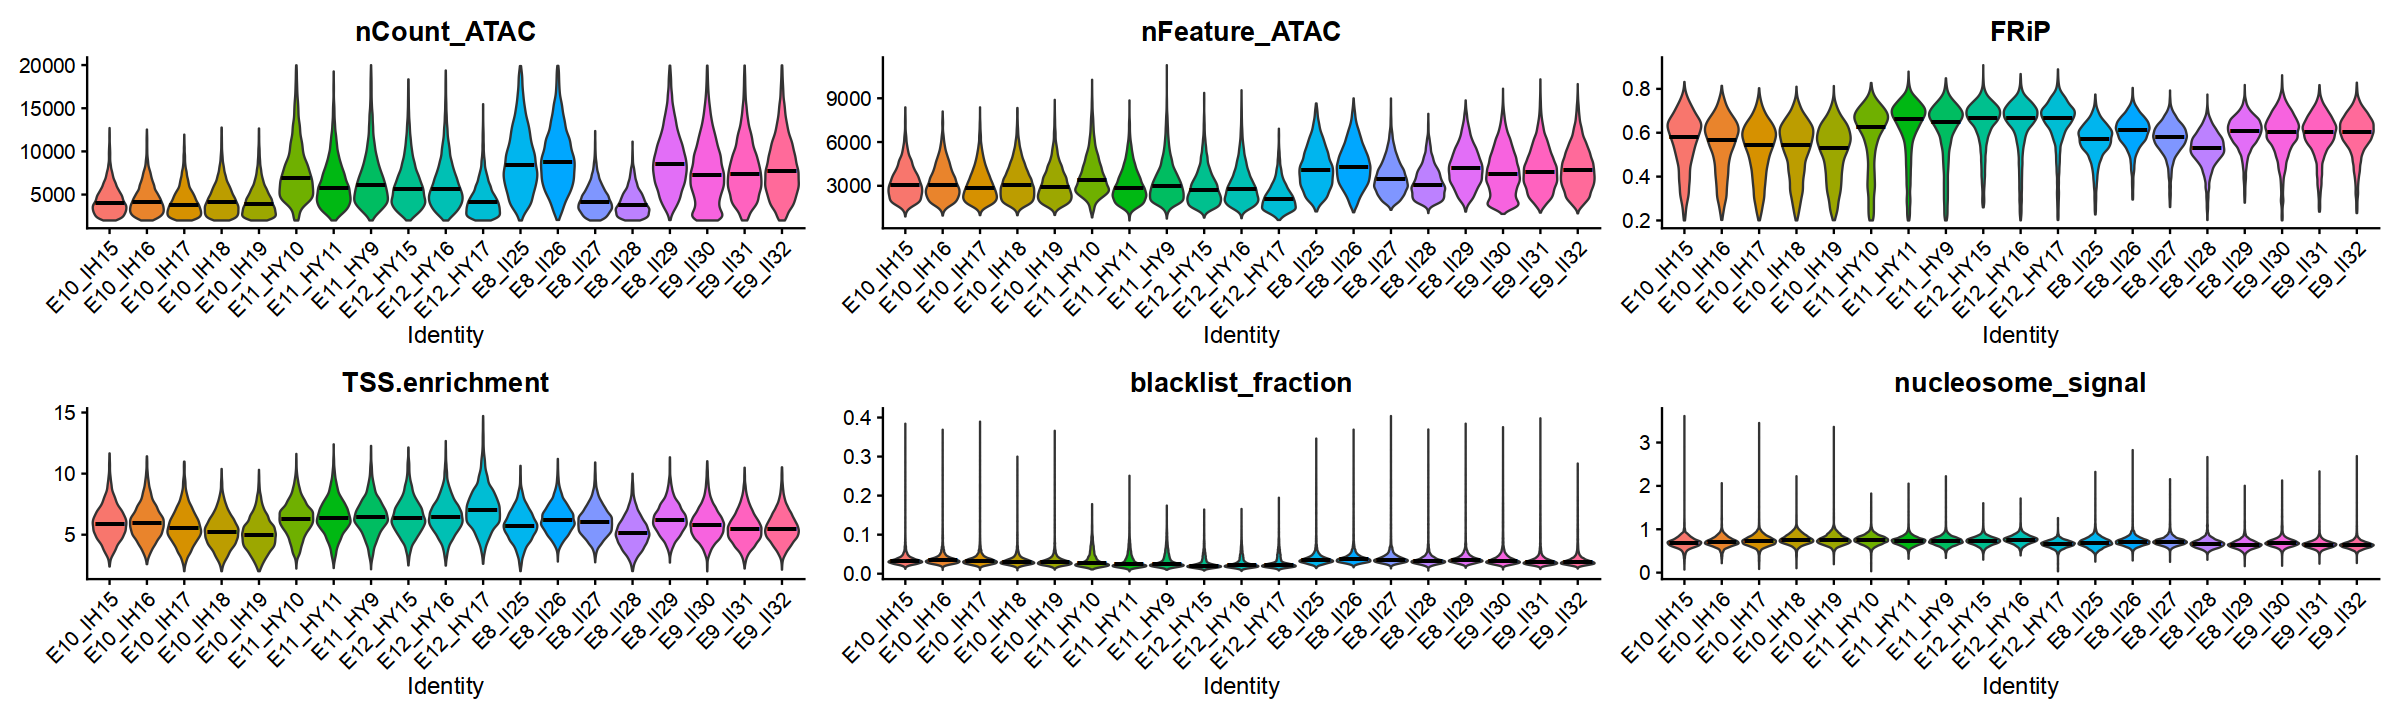

In [181]:
Plot_QC_ATAC(embryo_atac, group='sample', width=20, height=6)

In [182]:
saveRDS(embryo_atac,'/data/bio_data/data/scCAT_seq/00_scCAT_data/Embryo/processed/embro_ATAC_filtered.rds')

## data process

In [ ]:
embryo_atac <- readRDS('scCAT_seq/00_scCAT_data/Embryo/processed/embro_ATAC_filtered.rds')

In [26]:
embryo_atac

An object of class Seurat 
264125 features across 117539 samples within 1 assay 
Active assay: ATAC (264125 features, 132099 variable features)
 2 layers present: counts, data
 3 dimensional reductions calculated: lsi, harmony_lsi, umap.atac

In [10]:
embryo_atac@meta.data

,orig.ident,nCount_ATAC,nFeature_ATAC,fragments,FRiP,TSS.enrichment,TSS.percentile,nucleosome_signal,nucleosome_percentile,blacklist_fraction,outlier,scDblFinder.class,scDblFinder.score,sample,Sample
,<chr>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<chr>,<dbl>,<chr>,<chr>
E8_II25_BC0099_N01,E8,12483,6690,48904,0.2552552,3.858240,0.14,0.9763072,0.97,0.03428663,FALSE,singlet,0.3473916,E8_II25,E8
E8_II25_BC0107_N03,E8,19237,7871,55082,0.3492429,5.613840,0.52,0.8628929,0.91,0.02619951,FALSE,singlet,0.4307475,E8_II25,E8
E8_II25_BC0111_N02,E8,19878,8417,53221,0.3734992,4.831978,0.31,0.8554629,0.90,0.03345407,FALSE,singlet,0.4708393,E8_II25,E8
E8_II25_BC0121_N01,E8,10302,6643,45010,0.2288825,3.479202,0.10,0.8192908,0.85,0.04465152,FALSE,singlet,0.3812719,E8_II25,E8
E8_II25_BC0127_N01,E8,17419,8191,43647,0.3990881,4.164510,0.18,0.8643298,0.91,0.04305643,FALSE,singlet,0.4742236,E8_II25,E8
E8_II25_BC0128_N01,E8,12224,6345,43023,0.2841271,3.229899,0.08,0.7542501,0.68,0.02691427,FALSE,singlet,0.3528517,E8_II25,E8
E8_II25_BC0129_N01,E8,17155,7620,43444,0.3948762,5.864546,0.60,1.0533563,0.98,0.04097931,FALSE,singlet,0.4534284,E8_II25,E8
E8_II25_BC0132_N02,E8,12645,5570,49151,0.2572684,4.867859,0.32,0.9306145,0.95,0.03566627,FALSE,singlet,0.3413018,E8_II25,E8
E8_II25_BC0133_N01,E8,15186,7035,43952,0.3455133,4.062264,0.17,0.9849106,0.97,0.11517187,FALSE,singlet,0.3780089,E8_II25,E8


In [13]:
## LSI reduction
embryo_atac <- RunTFIDF(embryo_atac)
embryo_atac <- FindTopFeatures(embryo_atac, min.cutoff = 'q50')
embryo_atac <- RunSVD(embryo_atac)
# seurat.obj <- RunUMAP(seurat.obj, reduction = 'lsi', dims = c(2:40), reduction.name = "umap.atac", reduction.key = "atacUMAP_")
# seurat.obj <- FindNeighbors(seurat.obj, reduction = 'lsi', dims = 2:40)
# seurat.obj <- FindClusters(seurat.obj, verbose = FALSE, algorithm = 3, resolution = c(0.1, 0.3, 0.5))

Performing TF-IDF normalization

Running SVD

Scaling cell embeddings



In [14]:
var_int <- "sample"
#var_int <- "stage"
embryo_atac <- RunHarmony(embryo_atac, group.by.vars = var_int, assay.use="ATAC", reduction = "lsi", reduction.save = 'harmony_lsi', project.dim = FALSE)
embryo_atac <- RunUMAP(embryo_atac, reduction = 'harmony_lsi', dims = c(2:40), reduction.name = "umap.atac", reduction.key = "atacUMAP_")
embryo_atac <- FindNeighbors(embryo_atac, reduction = 'harmony_lsi', dims = c(2:40), n.neighbors = 40)
embryo_atac <- FindClusters(embryo_atac, verbose = FALSE, algorithm = 3, resolution = c(0.1, 0.3, 0.5))

Transposing data matrix

Initializing state using k-means centroids initialization

Warning message:
“Quick-TRANSfer stage steps exceeded maximum (= 5876950)”
Harmony 1/10

Harmony 2/10

Harmony 3/10

Harmony converged after 3 iterations

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
21:00:09 UMAP embedding parameters a = 0.9922 b = 1.112

21:00:09 Read 117539 rows and found 39 numeric columns

21:00:09 Using Annoy for neighbor search, n_neighbors = 30

21:00:10 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

21:00:25 Writing NN inde

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



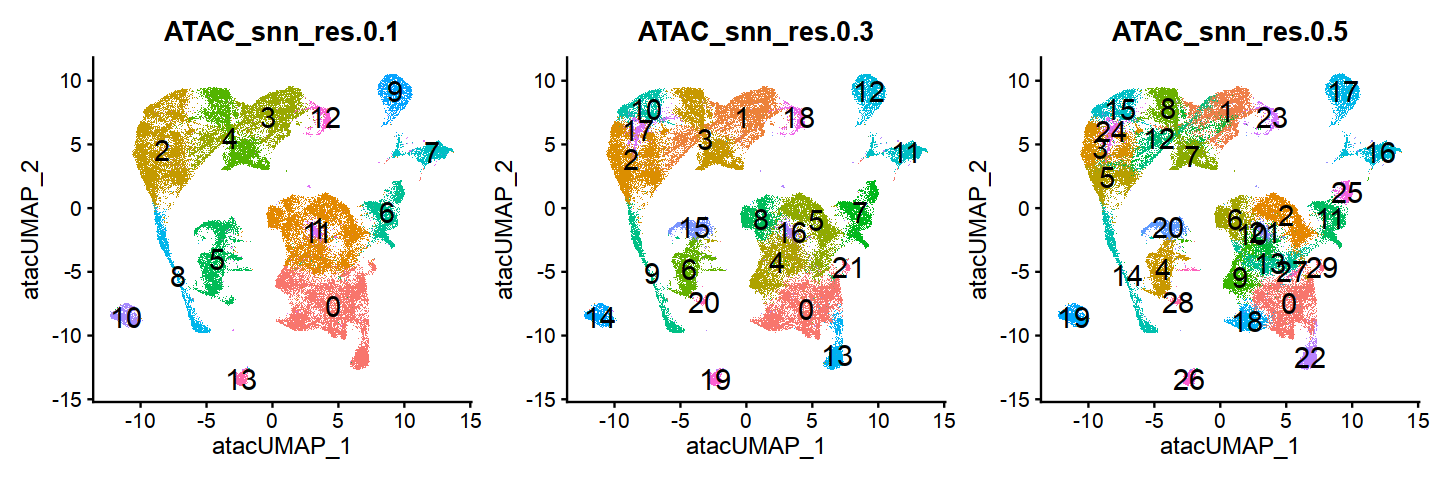

In [30]:
options(repr.plot.width=12, repr.plot.height=4)
p1 <- DimPlot(atac, label = TRUE, group.by = 'ATAC_snn_res.0.1',label.size = 6) + NoLegend()
p2 <- DimPlot(atac, label = TRUE, group.by = 'ATAC_snn_res.0.3',label.size = 6) + NoLegend()
p3 <- DimPlot(atac, label = TRUE, group.by = 'ATAC_snn_res.0.5',label.size = 6) + NoLegend()
p1|p2|p3

In [90]:
embryo_rna1 <- readRDS('/data/bio_data/zhangzhongjin/data/scCAT_seq/00_scCAT_data/Embryo/processed/RNA/embro_RNA_soupx0_filtered.rds')

In [91]:
embryo_rna2 <- readRDS('/data/bio_data/zhangzhongjin/data/scCAT_seq/00_scCAT_data/Embryo/processed/RNA/embro_RNA_soupx1_filtered.rds')

In [92]:
embryo_rna1

An object of class Seurat 
28425 features across 124245 samples within 1 assay 
Active assay: RNA (28425 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 3 dimensional reductions calculated: pca, harmony, umap

In [93]:
embryo_rna2

An object of class Seurat 
28425 features across 122874 samples within 1 assay 
Active assay: RNA (28425 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 3 dimensional reductions calculated: pca, harmony, umap

In [100]:
embryo_rna1@meta.data

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,percent.ribo,percent_mito,percent_ribo,percent_mito_ribo,log10GenesPerUMI,outlier,scDblFinder.class,scDblFinder.score,sample,Sample,RNA_snn_res.0.5,seurat_clusters
,<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<chr>,<dbl>,<chr>,<chr>,<fct>,<fct>
E8_II25_BC5290_N01,E8,421,325,0.47505938,1.9002375,0.47505938,1.9002375,2.3752969,0.9571697,FALSE,singlet,0.02884615,E8_II25,E8,1,1
E8_II25_BC5289_N01,E8,1420,936,0.07042254,1.2676056,0.07042254,1.2676056,1.3380282,0.9425774,FALSE,singlet,0.25007601,E8_II25,E8,1,1
E8_II25_BC5284_N01,E8,1315,856,0.38022814,1.2927757,0.38022814,1.2927757,1.6730038,0.9402192,FALSE,singlet,0.14430678,E8_II25,E8,1,1
E8_II25_BC5283_N01,E8,372,240,0.00000000,0.2688172,0.00000000,0.2688172,0.2688172,0.9259566,FALSE,singlet,0.05769231,E8_II25,E8,1,1
E8_II25_BC5282_N02,E8,3674,2053,0.54436581,0.7348938,0.54436581,0.7348938,1.2792597,0.9291051,FALSE,singlet,0.40424829,E8_II25,E8,14,14
E8_II25_BC5281_N01,E8,303,241,0.33003300,0.9900990,0.33003300,0.9900990,1.3201320,0.9599323,FALSE,singlet,0.05769231,E8_II25,E8,1,1
E8_II25_BC5280_N01,E8,1127,768,0.53238687,1.5084295,0.53238687,1.5084295,2.0408163,0.9454237,FALSE,singlet,0.16353755,E8_II25,E8,1,1
E8_II25_BC5278_N01,E8,578,423,0.34602076,0.8650519,0.34602076,0.8650519,1.2110727,0.9509084,FALSE,singlet,0.18269231,E8_II25,E8,1,1
E8_II25_BC5277_N02,E8,2231,1171,0.40340654,2.1963245,0.40340654,2.1963245,2.5997311,0.9163976,FALSE,singlet,0.21000747,E8_II25,E8,10,10


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



[[1]]

[[2]]


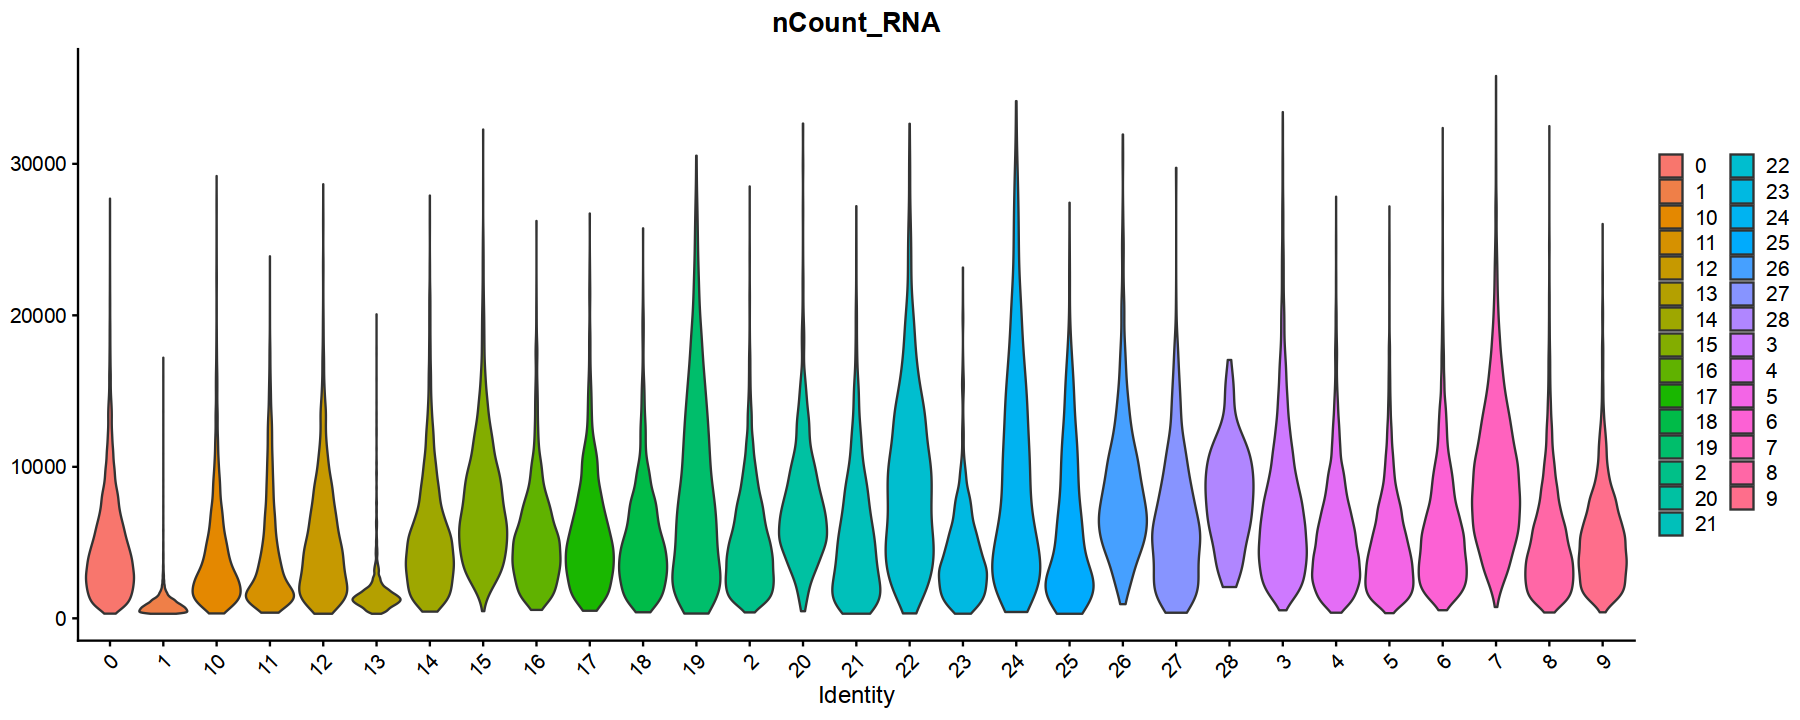

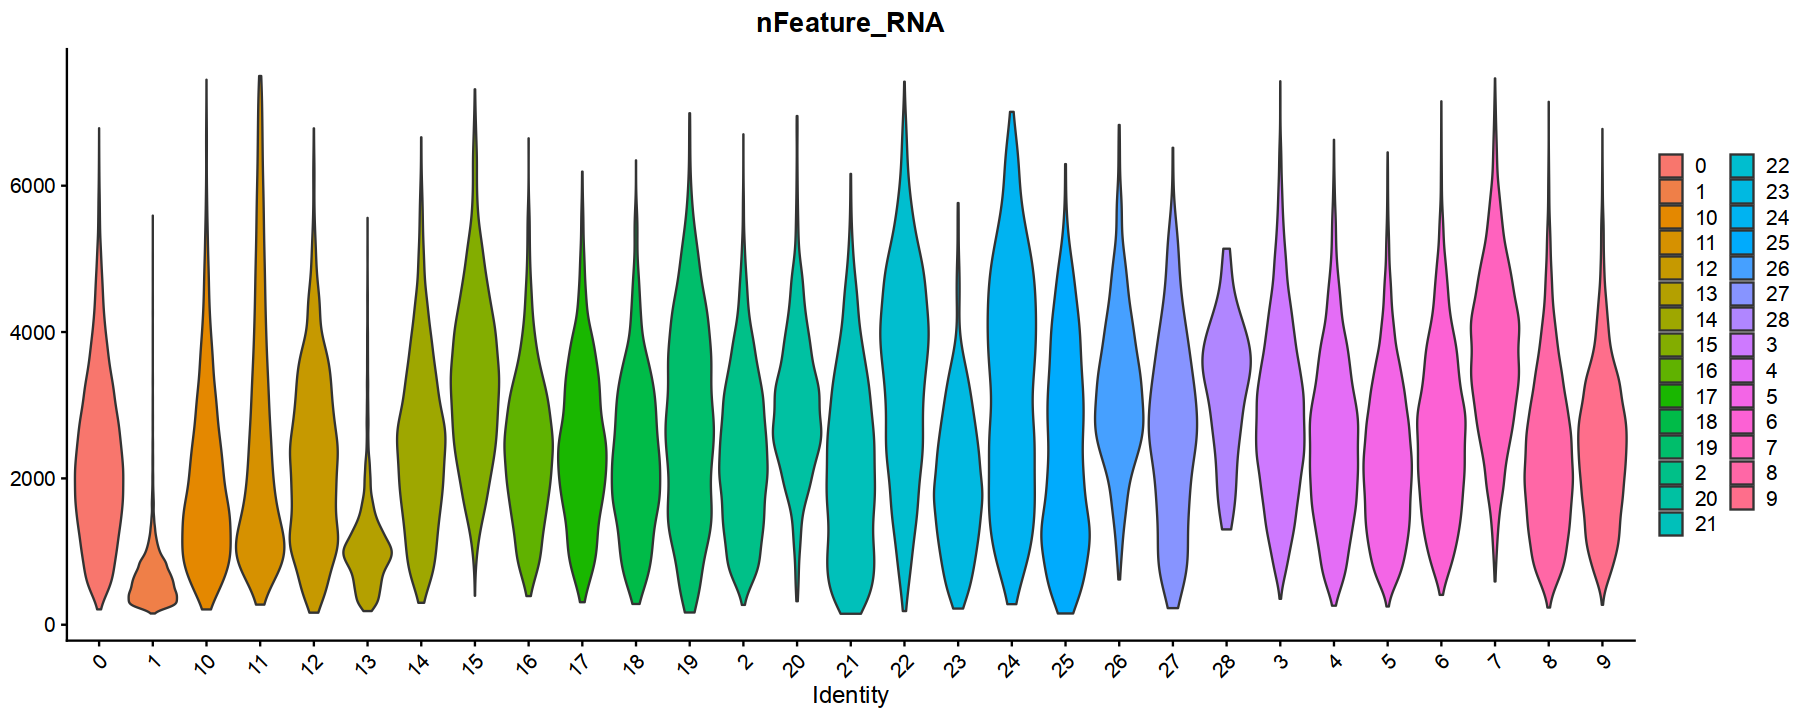

[[1]]

[[2]]


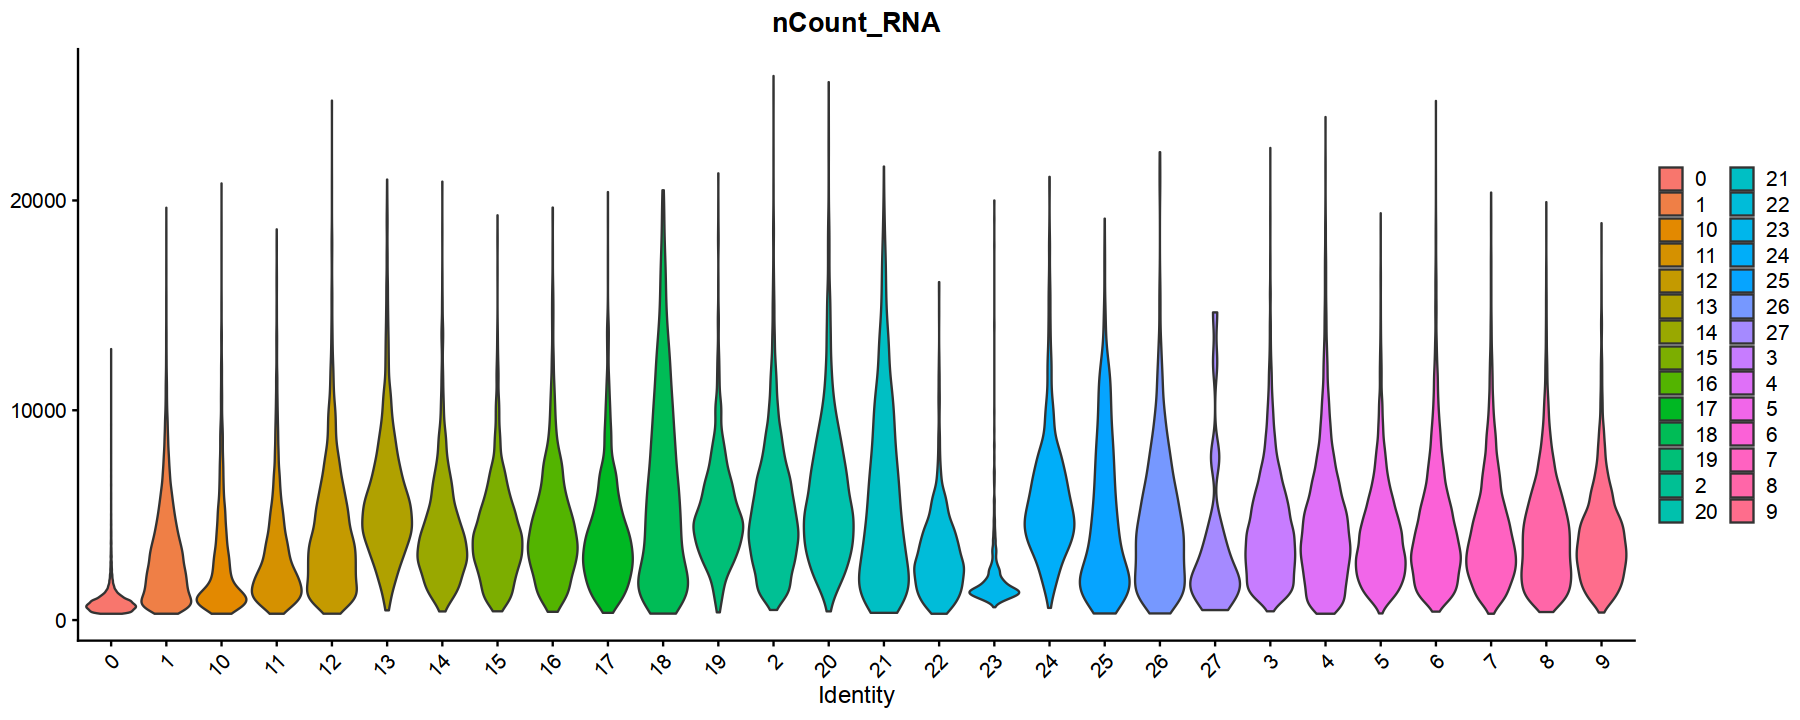

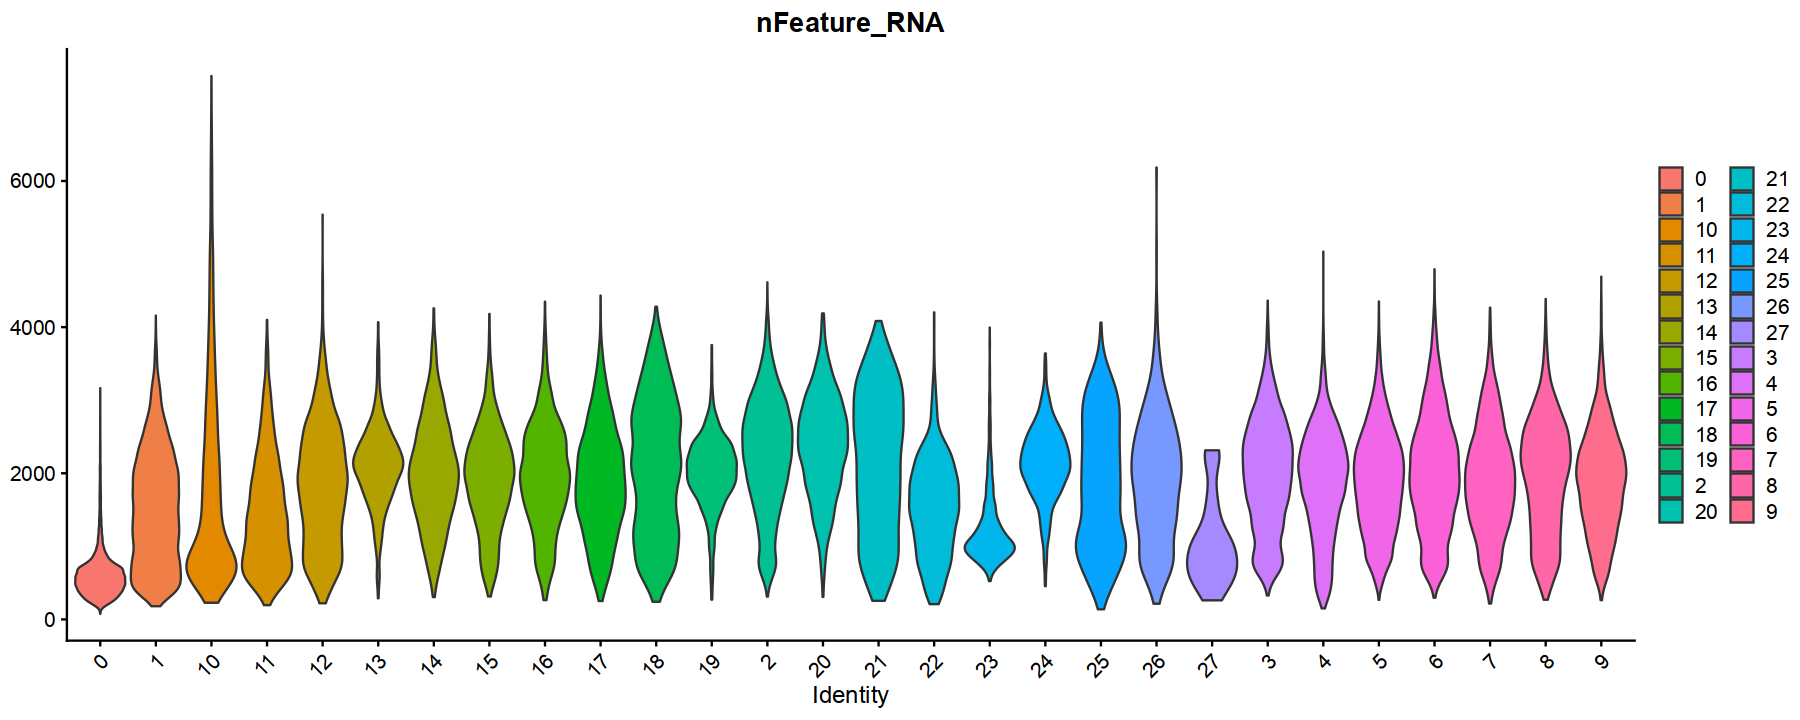

In [96]:
p1 <- VlnPlot(object = embryo_rna1,features = c('nCount_RNA','nFeature_RNA'),
              ncol = 1, pt.size = 0,group.by = 'RNA_snn_res.0.5', combine = FALSE) 
p2 <- VlnPlot(object = embryo_rna2,features = c('nCount_RNA','nFeature_RNA'),
              ncol = 1, pt.size = 0,group.by = 'RNA_snn_res.0.5', combine = FALSE) 
p1
p2

In [102]:
table(embryo_rna1$orig.ident,embryo_rna1$RNA_snn_res.0.5)
table(embryo_rna2$orig.ident,embryo_rna2$RNA_snn_res.0.5)

     
         0    1   10   11   12   13   14   15   16   17   18   19    2   20
  E10 4211 4370  823  385  946  759  510   36  102   93  238  189 3517   64
  E11  692  667  976 1134   99  712  224 1374    4    2   27   11  359  454
  E12  569 1007  646 1099   78 1548  167  932    4    0   36   22  314  924
  E8  4978 2772  828  536 1206   11 1013    1 1136 1287 1040 1023 2637    0
  E9  5466 3463  456  571 1105   93  599   14  747  526  541  348 2937    8
     
        21   22   23   24   25   26   27   28    3    4    5    6    7    8
  E10  481  233  303  283  335   39  163    3 1553 2524 2772 2713  334 1571
  E11   19  463   39  438    7  290  135   31 3709  775  289  966 2313  258
  E12    8  523   31  311    2  515  137   73 3395  866  313  978 3041  244
  E8   425    3  404    0  204    0   12    0   31 2025 2231 1084  141 2263
  E9   402   61  486  107  380    0   43    0  679 3121 2431 2107  139 1560
     
         9
  E10 1128
  E11  144
  E12  206
  E8  1696
  E9  1590

     
         0    1   10   11   12   13   14   15   16   17   18   19    2   20
  E10 4633 3724  452  865  921  143  408  101  109  233  211   63 2719   58
  E11 1230  656 1062  977   84 1112  182    8    5   32   26  543 2335  446
  E12 1611  651 1034  650   80  989   96    9    7   46   54  989 2758  792
  E8  2869 3575  595  839 1241    0  929 1179 1271 1039 1021    0 1458  114
  E9  3316 4002  745  482 1070    9  570  839  540  438  381   14 2286   33
     
        21   22   23   24   25   26   27    3    4    5    6    7    8    9
  E10  341  262   13   46  351  183    0 2924 2080 2032 2261 1933 1292 1086
  E11  496   48  144  362   11  164    0  472 3530  693  837  370  646  148
  E12  287   34  918  583    8  168    0  478 2928  623  959  379  865  232
  E8     1  363    0    0  191   26   24 2670   57 2616 2224 1895  962 1546
  E9   132  453    2    1  425   43    0 2821  751 3190 2380 1794 1714 1447

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



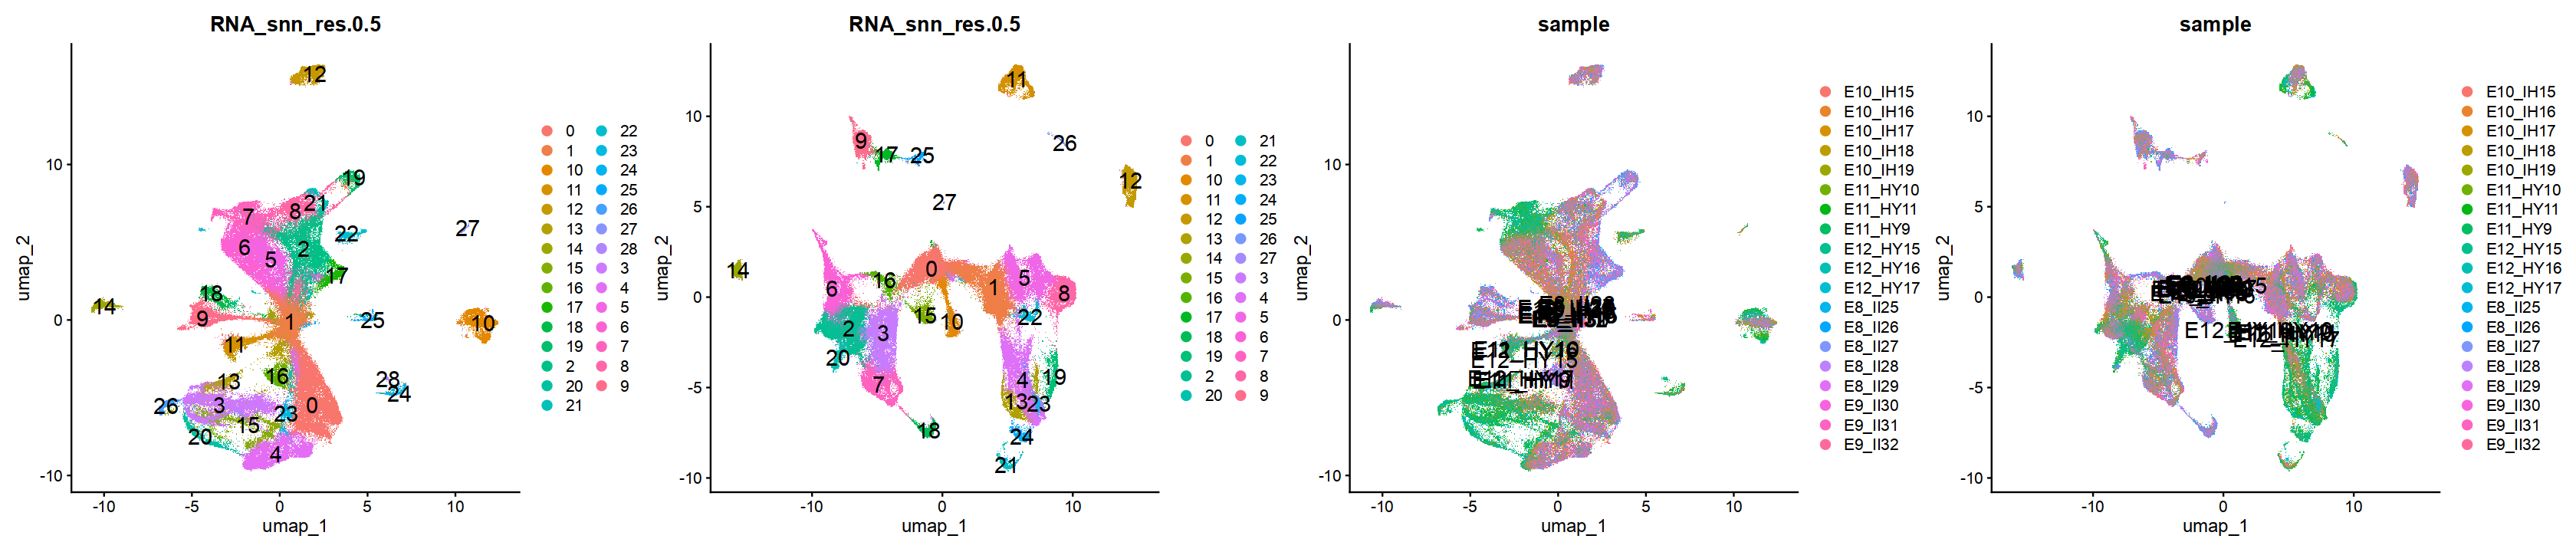

In [104]:
options(repr.plot.width=28, repr.plot.height=6)
p1 <- DimPlot(embryo_rna1, label = TRUE, group.by = 'RNA_snn_res.0.5',label.size = 6) #+ NoLegend()
p2 <- DimPlot(embryo_rna2, label = TRUE, group.by = 'RNA_snn_res.0.5',label.size = 6) #+ NoLegend()
p3 <- DimPlot(embryo_rna1, label = TRUE, group.by = 'sample',label.size = 6) #+ NoLegend()
p4 <- DimPlot(embryo_rna2, label = TRUE, group.by = 'sample',label.size = 6) #+ NoLegend()
p1|p2|p3|p4